In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats
import yfinance as yf
import datetime
import xgboost
import os

from scipy.stats import norm
from scipy.integrate import quad
from scipy.optimize import minimize, least_squares, newton, differential_evolution, dual_annealing, LinearConstraint
from sklearn.model_selection import train_test_split
from sklearn.metrics import explained_variance_score, mean_absolute_error, mean_squared_error, mean_squared_log_error
from xgboost import XGBRegressor
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.metrics import r2_score
import torch
import torch.nn.functional as F
import contextlib
from concurrent.futures import ThreadPoolExecutor, as_completed


In [ ]:
# Full training Dataset configurations — split by model type

BASE_PATH = r"C:\Users\chril\Downloads\Master_Thesis_Materials\Data\Working\Option_Metrics\models_final_output"

DATASET_CONFIGS_PRICE = [
    {"name": "heston_local_2002",
     "path": fr"{BASE_PATH}\Stochastic_models\data_heston_local_2002_top3_qual.dta",
     "model_price_col": "heston_price",
     "model_ivol_col":  "BS_impl_vol_heston"},
    {"name": "sabr_local_2002",
     "path": fr"{BASE_PATH}\Stochastic_models\data_sabr_local_2002_top3_qual.dta",
     "model_price_col": "sabr_price",
     "model_ivol_col":  "sabr_volatility"},
    {"name": "output_xgb_price_2002",
     "path": fr"{BASE_PATH}\ML_models\price_xgb_output_2002.dta",
     "model_price_col": "price_xgb",
     "model_ivol_col":  "-NA-"},
    {"name": "output_ann_price_lbfgs_2002",
     "path": fr"{BASE_PATH}\ML_models\price_ann_lbfgs_output_2002.dta",
     "model_price_col": "price_ann",
     "model_ivol_col":  "-NA-"},
    {"name": "heston_local_2003",
     "path": fr"{BASE_PATH}\Stochastic_models\data_heston_local_2003_top3_qual.dta",
     "model_price_col": "heston_price",
     "model_ivol_col":  "BS_impl_vol_heston"},
    {"name": "sabr_local_2003",
     "path": fr"{BASE_PATH}\Stochastic_models\data_sabr_local_2003_top3_qual.dta",
     "model_price_col": "sabr_price",
     "model_ivol_col":  "sabr_volatility"},
    {"name": "output_xgb_price_2003",
     "path": fr"{BASE_PATH}\ML_models\price_xgb_output_2003.dta",
     "model_price_col": "price_xgb",
     "model_ivol_col":  "-NA-"},
    {"name": "output_ann_price_lbfgs_2003",
     "path": fr"{BASE_PATH}\ML_models\price_ann_lbfgs_output_2003.dta",
     "model_price_col": "price_ann",
     "model_ivol_col":  "-NA-"},
]


DATASET_CONFIGS_IVOL = [
    {"name": "heston_local_2002",
     "path": fr"{BASE_PATH}\Stochastic_models\data_heston_local_2002_top3_qual.dta",
     "model_price_col": "heston_price",
     "model_ivol_col":  "BS_impl_vol_heston",
     "market_price":    "price"},
    {"name": "sabr_local_2002",
     "path": fr"{BASE_PATH}\Stochastic_models\data_sabr_local_2002_top3_qual.dta",
     "model_price_col": "sabr_price",
     "model_ivol_col":  "sabr_volatility",
     "market_price":    "price"},
    {"name": "output_xgb_ivol_2002",
     "path": fr"{BASE_PATH}\ML_models\ivol_xgb_output_2002.dta",
     "model_price_col": "-NA-",
     "model_ivol_col":  "impl_vol_xgb",
     "market_price":    "price"},
    {"name": "output_ann_ivol_lbfgs_2002",
     "path": fr"{BASE_PATH}\ML_models\ivol_ann_lbfgs_output_2002.dta",
     "model_price_col": "-NA-",
     "model_ivol_col":  "impl_vol_ann",
     "market_price":    "price"},
    {"name": "heston_local_2003",
     "path": fr"{BASE_PATH}\Stochastic_models\data_heston_local_2003_top3_qual.dta",
     "model_price_col": "heston_price",
     "model_ivol_col":  "BS_impl_vol_heston",
     "market_price":    "price"},
    {"name": "sabr_local_2003",
     "path": fr"{BASE_PATH}\Stochastic_models\data_sabr_local_2003_top3_qual.dta",
     "model_price_col": "sabr_price",
     "model_ivol_col":  "sabr_volatility",
     "market_price":    "price"},
    {"name": "output_xgb_ivol_2003",
     "path": fr"{BASE_PATH}\ML_models\ivol_xgb_output_2003.dta",
     "model_price_col": "-NA-",
     "model_ivol_col":  "impl_vol_xgb",
     "market_price":    "price"},
    {"name": "output_ann_ivol_lbfgs_2003",
     "path": fr"{BASE_PATH}\ML_models\ivol_ann_lbfgs_output_2003.dta",
     "model_price_col": "-NA-",
     "model_ivol_col":  "impl_vol_ann",
     "market_price":    "price"},
]

In [ ]:
# Partial training Dataset configurations — split by model type

BASE_PATH = r"C:\Users\chril\Downloads\Master_Thesis_Materials\Data\Working\Option_Metrics\models_final_output"

DATASET_PARTIAL_CONFIGS_PRICE = [
    {"name": "heston_surface_2002",
     "path": fr"{BASE_PATH}\Stochastic_models\data_heston_surface_2002_top3_qual.dta",
     "model_price_col": "heston_price",
     "model_ivol_col":  "BS_impl_vol_heston"},
    {"name": "heston_variable_2002",
     "path": fr"{BASE_PATH}\Stochastic_models\data_heston_variable_2002_top3_qual.dta",
     "model_price_col": "heston_price",
     "model_ivol_col":  "BS_impl_vol_heston"},
    {"name": "sabr_surface_2002",
     "path": fr"{BASE_PATH}\Stochastic_models\data_sabr_surface_2002_top3_qual.dta",
     "model_price_col": "sabr_price",
     "model_ivol_col":  "sabr_volatility"},
    {"name": "sabr_variable_2002",
     "path": fr"{BASE_PATH}\Stochastic_models\data_sabr_variable_2002_top3_qual.dta",
     "model_price_col": "sabr_price",
     "model_ivol_col":  "sabr_volatility"},
    {"name": "surface_xgb_price_2002",
     "path": fr"{BASE_PATH}\ML_models\surface_xgb_price_data_2002.dta",
     "model_price_col": "price_xgb",
     "model_ivol_col":  "-NA-"},
    {"name": "surface_ann_price_lbfgs_2002",
     "path": fr"{BASE_PATH}\ML_models\surface_ann_lbfgs_price_data_2002.dta",
     "model_price_col": "price_ann",
     "model_ivol_col":  "-NA-"},
    {"name": "variable_ann_price_lbfgs_2002",
     "path": fr"{BASE_PATH}\ML_models\variable_ann_lbfgs_price_data_2002.dta",
     "model_price_col": "price_ann",
     "model_ivol_col":  "-NA-"},
    {"name": "heston_surface_2003",
     "path": fr"{BASE_PATH}\Stochastic_models\data_heston_surface_2003_top3_qual.dta",
     "model_price_col": "heston_price",
     "model_ivol_col":  "BS_impl_vol_heston"},
    {"name": "heston_variable_2003",
     "path": fr"{BASE_PATH}\Stochastic_models\data_heston_variable_2003_top3_qual.dta",
     "model_price_col": "heston_price",
     "model_ivol_col":  "BS_impl_vol_heston"},
    {"name": "sabr_surface_2003",
     "path": fr"{BASE_PATH}\Stochastic_models\data_sabr_surface_2003_top3_qual.dta",
     "model_price_col": "sabr_price",
     "model_ivol_col":  "sabr_volatility"},
    {"name": "sabr_variable_2003",
     "path": fr"{BASE_PATH}\Stochastic_models\data_sabr_variable_2003_top3_qual.dta",
     "model_price_col": "sabr_price",
     "model_ivol_col":  "sabr_volatility"},
    {"name": "surface_xgb_price_2003",
     "path": fr"{BASE_PATH}\ML_models\surface_xgb_price_data_2003.dta",
     "model_price_col": "price_xgb",
     "model_ivol_col":  "-NA-"},
    {"name": "surface_ann_price_lbfgs_2003",
     "path": fr"{BASE_PATH}\ML_models\surface_ann_lbfgs_price_data_2003.dta",
     "model_price_col": "price_ann",
     "model_ivol_col":  "-NA-"},
    {"name": "variable_ann_price_lbfgs_2003",
     "path": fr"{BASE_PATH}\ML_models\variable_ann_lbfgs_price_data_2003.dta",
     "model_price_col": "price_ann",
     "model_ivol_col":  "-NA-"},
]


DATASET_PARTIAL_CONFIGS_IVOL = [
    {"name": "heston_surface_2002",
     "path": fr"{BASE_PATH}\Stochastic_models\data_heston_surface_2002_top3_qual.dta",
     "model_price_col": "heston_price",
     "model_ivol_col":  "BS_impl_vol_heston",
     "market_price":    "price"},
    {"name": "heston_variable_2002",
     "path": fr"{BASE_PATH}\Stochastic_models\data_heston_variable_2002_top3_qual.dta",
     "model_price_col": "heston_price",
     "model_ivol_col":  "BS_impl_vol_heston",
     "market_price":    "price"},
    {"name": "sabr_surface_2002",
     "path": fr"{BASE_PATH}\Stochastic_models\data_sabr_surface_2002_top3_qual.dta",
     "model_price_col": "sabr_price",
     "model_ivol_col":  "sabr_volatility",
     "market_price":    "price"},
    {"name": "sabr_variable_2002",
     "path": fr"{BASE_PATH}\Stochastic_models\data_sabr_variable_2002_top3_qual.dta",
     "model_price_col": "sabr_price",
     "model_ivol_col":  "sabr_volatility",
     "market_price":    "price"},
    {"name": "surface_xgb_ivol_2002",
     "path": fr"{BASE_PATH}\ML_models\surface_xgb_ivol_data_2002.dta",
     "model_price_col": "-NA-",
     "model_ivol_col":  "impl_vol_xgb",
     "market_price":    "price"},
    {"name": "surface_ann_ivol_lbfgs_2002",
     "path": fr"{BASE_PATH}\ML_models\surface_ann_lbfgs_ivol_data_2002.dta",
     "model_price_col": "-NA-",
     "model_ivol_col":  "impl_vol_ann",
     "market_price":    "price"},
    {"name": "variable_ann_ivol_lbfgs_2002",
     "path": fr"{BASE_PATH}\ML_models\variable_ann_lbfgs_ivol_data_2002.dta",
     "model_price_col": "-NA-",
     "model_ivol_col":  "impl_vol_ann",
     "market_price":    "price"},
    {"name": "heston_surface_2003",
     "path": fr"{BASE_PATH}\Stochastic_models\data_heston_surface_2003_top3_qual.dta",
     "model_price_col": "heston_price",
     "model_ivol_col":  "BS_impl_vol_heston",
     "market_price":    "price"},
    {"name": "heston_variable_2003",
     "path": fr"{BASE_PATH}\Stochastic_models\data_heston_variable_2003_top3_qual.dta",
     "model_price_col": "heston_price",
     "model_ivol_col":  "BS_impl_vol_heston",
     "market_price":    "price"},
    {"name": "sabr_surface_2003",
     "path": fr"{BASE_PATH}\Stochastic_models\data_sabr_surface_2003_top3_qual.dta",
     "model_price_col": "sabr_price",
     "model_ivol_col":  "sabr_volatility",
     "market_price":    "price"},
    {"name": "sabr_variable_2003",
     "path": fr"{BASE_PATH}\Stochastic_models\data_sabr_variable_2003_top3_qual.dta",
     "model_price_col": "sabr_price",
     "model_ivol_col":  "sabr_volatility",
     "market_price":    "price"},
    {"name": "surface_xgb_ivol_2003",
     "path": fr"{BASE_PATH}\ML_models\surface_xgb_ivol_data_2003.dta",
     "model_price_col": "-NA-",
     "model_ivol_col":  "impl_vol_xgb",
     "market_price":    "price"},
    {"name": "surface_ann_ivol_lbfgs_2003",
     "path": fr"{BASE_PATH}\ML_models\surface_ann_lbfgs_ivol_data_2003.dta",
     "model_price_col": "-NA-",
     "model_ivol_col":  "impl_vol_ann",
     "market_price":    "price"},
    {"name": "variable_ann_ivol_lbfgs_2003",
     "path": fr"{BASE_PATH}\ML_models\variable_ann_lbfgs_ivol_data_2003.dta",
     "model_price_col": "-NA-",
     "model_ivol_col":  "impl_vol_ann",
     "market_price":    "price"},
]

In [ ]:
# Stoch vol ML model Dataset configurations — split by model type

BASE_PATH = r"C:\Users\chril\Downloads\Master_Thesis_Materials\Data\Working\Option_Metrics\models_final_output"

DATASET_STOCH_VOL_CONFIGS_PRICE = [
    {"name": "twostep_xgb_heston_2002",
     "path": fr"{BASE_PATH}\Stochastic_ML_models\twostep_xgb_heston_2002.dta",
     "model_price_col": "heston_price",
     "model_ivol_col":  "heston_volatility"},
    {"name": "twostep_xgb_sabr_2002",
     "path": fr"{BASE_PATH}\Stochastic_ML_models\twostep_xgb_sabr_2002.dta",
     "model_price_col": "sabr_price",
     "model_ivol_col":  "sabr_volatility"},
    {"name": "twostep_lbfgs_heston_2002",
     "path": fr"{BASE_PATH}\Stochastic_ML_models\twostep_lbfgs_heston_2002.dta",
     "model_price_col": "heston_price",
     "model_ivol_col":  "heston_volatility"},
    {"name": "twostep_lbfgs_sabr_2002",
     "path": fr"{BASE_PATH}\Stochastic_ML_models\twostep_lbfgs_sabr_2002.dta",
     "model_price_col": "sabr_price",
     "model_ivol_col":  "sabr_volatility"},
    {"name": "onestep_xgb_heston_2002",
     "path": fr"{BASE_PATH}\Stochastic_ML_models\onestep_xgb_heston_2002.dta",
     "model_price_col": "heston_price",
     "model_ivol_col":  "heston_volatility"},
    {"name": "onestep_xgb_sabr_2002",
     "path": fr"{BASE_PATH}\Stochastic_ML_models\onestep_xgb_sabr_2002.dta",
     "model_price_col": "sabr_price",
     "model_ivol_col":  "sabr_volatility"},
    {"name": "onestep_lbfgs_heston_2002",
     "path": fr"{BASE_PATH}\Stochastic_ML_models\onestep_lbfgs_heston_2002.dta",
     "model_price_col": "heston_price",
     "model_ivol_col":  "heston_volatility"},
    {"name": "onestep_lbfgs_sabr_2002",
     "path": fr"{BASE_PATH}\Stochastic_ML_models\onestep_lbfgs_sabr_2002.dta",
     "model_price_col": "sabr_price",
     "model_ivol_col":  "sabr_volatility"},
    {"name": "twostep_xgb_heston_2003",
     "path": fr"{BASE_PATH}\Stochastic_ML_models\twostep_xgb_heston_2003.dta",
     "model_price_col": "heston_price",
     "model_ivol_col":  "heston_volatility"},
    {"name": "twostep_xgb_sabr_2003",
     "path": fr"{BASE_PATH}\Stochastic_ML_models\twostep_xgb_sabr_2003.dta",
     "model_price_col": "sabr_price",
     "model_ivol_col":  "sabr_volatility"},
    {"name": "twostep_lbfgs_heston_2003",
     "path": fr"{BASE_PATH}\Stochastic_ML_models\twostep_lbfgs_heston_2003.dta",
     "model_price_col": "heston_price",
     "model_ivol_col":  "heston_volatility"},
    {"name": "twostep_lbfgs_sabr_2003",
     "path": fr"{BASE_PATH}\Stochastic_ML_models\twostep_lbfgs_sabr_2003.dta",
     "model_price_col": "sabr_price",
     "model_ivol_col":  "sabr_volatility"},
    {"name": "onestep_xgb_heston_2003",
     "path": fr"{BASE_PATH}\Stochastic_ML_models\onestep_xgb_heston_2003.dta",
     "model_price_col": "heston_price",
     "model_ivol_col":  "heston_volatility"},
    {"name": "onestep_xgb_sabr_2003",
     "path": fr"{BASE_PATH}\Stochastic_ML_models\onestep_xgb_sabr_2003.dta",
     "model_price_col": "sabr_price",
     "model_ivol_col":  "sabr_volatility"},
    {"name": "onestep_lbfgs_heston_2003",
     "path": fr"{BASE_PATH}\Stochastic_ML_models\onestep_lbfgs_heston_2003.dta",
     "model_price_col": "heston_price",
     "model_ivol_col":  "heston_volatility"},
    {"name": "onestep_lbfgs_sabr_2003",
     "path": fr"{BASE_PATH}\Stochastic_ML_models\onestep_lbfgs_sabr_2003.dta",
     "model_price_col": "sabr_price",
     "model_ivol_col":  "sabr_volatility"}
]


DATASET_STOCH_VOL_CONFIGS_IVOL = [
        {"name": "twostep_xgb_heston_2002",
         "path": fr"{BASE_PATH}\Stochastic_ML_models\twostep_xgb_heston_2002.dta",
         "model_price_col": "heston_price",
         "model_ivol_col":  "heston_volatility"},
        {"name": "twostep_xgb_sabr_2002",
         "path": fr"{BASE_PATH}\Stochastic_ML_models\twostep_xgb_sabr_2002.dta",
         "model_price_col": "sabr_price",
         "model_ivol_col":  "sabr_volatility"},
        {"name": "twostep_lbfgs_heston_2002",
         "path": fr"{BASE_PATH}\Stochastic_ML_models\twostep_lbfgs_heston_2002.dta",
         "model_price_col": "heston_price",
         "model_ivol_col":  "heston_volatility"},
        {"name": "twostep_lbfgs_sabr_2002",
         "path": fr"{BASE_PATH}\Stochastic_ML_models\twostep_lbfgs_sabr_2002.dta",
         "model_price_col": "sabr_price",
         "model_ivol_col":  "sabr_volatility"},
        {"name": "onestep_xgb_heston_2002",
         "path": fr"{BASE_PATH}\Stochastic_ML_models\onestep_xgb_heston_2002.dta",
         "model_price_col": "heston_price",
         "model_ivol_col":  "heston_volatility"},
        {"name": "onestep_xgb_sabr_2002",
         "path": fr"{BASE_PATH}\Stochastic_ML_models\onestep_xgb_sabr_2002.dta",
         "model_price_col": "sabr_price",
         "model_ivol_col":  "sabr_volatility"},
        {"name": "onestep_lbfgs_heston_2002",
         "path": fr"{BASE_PATH}\Stochastic_ML_models\onestep_lbfgs_heston_2002.dta",
         "model_price_col": "heston_price",
         "model_ivol_col":  "heston_volatility"},
        {"name": "onestep_lbfgs_sabr_2002",
         "path": fr"{BASE_PATH}\Stochastic_ML_models\onestep_lbfgs_sabr_2002.dta",
         "model_price_col": "sabr_price",
         "model_ivol_col":  "sabr_volatility"},
        {"name": "twostep_xgb_heston_2003",
         "path": fr"{BASE_PATH}\Stochastic_ML_models\twostep_xgb_heston_2003.dta",
         "model_price_col": "heston_price",
         "model_ivol_col":  "heston_volatility"},
        {"name": "twostep_xgb_sabr_2003",
         "path": fr"{BASE_PATH}\Stochastic_ML_models\twostep_xgb_sabr_2003.dta",
         "model_price_col": "sabr_price",
         "model_ivol_col":  "sabr_volatility"},
        {"name": "twostep_lbfgs_heston_2003",
         "path": fr"{BASE_PATH}\Stochastic_ML_models\twostep_lbfgs_heston_2003.dta",
         "model_price_col": "heston_price",
         "model_ivol_col":  "heston_volatility"},
        {"name": "twostep_lbfgs_sabr_2003",
         "path": fr"{BASE_PATH}\Stochastic_ML_models\twostep_lbfgs_sabr_2003.dta",
         "model_price_col": "sabr_price",
         "model_ivol_col":  "sabr_volatility"},
        {"name": "onestep_xgb_heston_2003",
         "path": fr"{BASE_PATH}\Stochastic_ML_models\onestep_xgb_heston_2003.dta",
         "model_price_col": "heston_price",
         "model_ivol_col":  "heston_volatility"},
        {"name": "onestep_xgb_sabr_2003",
         "path": fr"{BASE_PATH}\Stochastic_ML_models\onestep_xgb_sabr_2003.dta",
         "model_price_col": "sabr_price",
         "model_ivol_col":  "sabr_volatility"},
        {"name": "onestep_lbfgs_heston_2003",
         "path": fr"{BASE_PATH}\Stochastic_ML_models\onestep_lbfgs_heston_2003.dta",
         "model_price_col": "heston_price",
         "model_ivol_col":  "heston_volatility"},
        {"name": "onestep_lbfgs_sabr_2003",
         "path": fr"{BASE_PATH}\Stochastic_ML_models\onestep_lbfgs_sabr_2003.dta",
         "model_price_col": "sabr_price",
         "model_ivol_col":  "sabr_volatility"}
]

In [ ]:
# GPU-accelerated optimization functions for absolute and relative price strategies

def optimization_absolute_p_gpu(
    market_pivot_p, model_pivot_p, past_pivot_p,
    gamma=3, use_ewma=False, ewma_lambda=0.94,
    device=None, n_iter=20, lr=1.0,
    l1_penalty_weight=500,
):
    if device is None:
        device = 'cuda' if torch.cuda.is_available() else 'cpu'

    op_r      = ((model_pivot_p - market_pivot_p) / market_pivot_p).fillna(0)
    ret_pivot = np.log(past_pivot_p / past_pivot_p.shift(1)).fillna(0)[1:]
    Sigma_np  = np.cov(ret_pivot.T) + np.eye(len(ret_pivot.columns)) * 1e-6

    T = len(op_r)
    n = len(op_r.columns)

    MU      = torch.tensor(op_r.values, dtype=torch.float32, device=device)
    Sigma_t = torch.tensor(Sigma_np,    dtype=torch.float32, device=device)
    mk_r    = np.log(market_pivot_p / market_pivot_p.shift(1)).fillna(0)
    mk_r_t  = torch.tensor(mk_r.values, dtype=torch.float32, device=device)

    relu      = torch.nn.functional.relu
    L1_budget = 1.0
    rho       = l1_penalty_weight

    if not use_ewma:
        R   = torch.zeros(T, n, device=device, requires_grad=True)
        opt = torch.optim.LBFGS([R], lr=lr, max_iter=20, line_search_fn='strong_wolfe')
        def closure():
            opt.zero_grad()
            Wc   = torch.tanh(R).clamp(-1.0, 1.0)
            vt   = (Wc @ Sigma_t * Wc).sum(dim=1)
            rt   = (Wc * MU).sum(dim=1)
            l1_viol  = relu(Wc.abs().sum(dim=1) - L1_budget)
            net_viol = relu(Wc.sum(dim=1).abs() - L1_budget)
            loss = (gamma / 2 * vt - rt + rho * l1_viol.pow(2) + rho * net_viol.pow(2)).sum()
            loss.backward()
            return loss
        for _ in range(n_iter):
            opt.step(closure)
        W_np = torch.tanh(R.detach()).clamp(-1.0, 1.0).cpu().numpy()
        return pd.DataFrame(W_np, columns=op_r.columns)

    portfolio_R = [torch.zeros(n, device=device)]
    for t in range(T):
        mu_t = MU[t]
        r    = torch.nn.Parameter(portfolio_R[-1].clone())
        opt  = torch.optim.LBFGS([r], lr=lr, max_iter=20, line_search_fn='strong_wolfe')
        def closure():
            opt.zero_grad()
            w    = torch.tanh(r).clamp(-1.0, 1.0)
            vt   = w @ Sigma_t @ w
            rt   = torch.dot(w, mu_t)
            l1_viol  = relu(w.abs().sum() - L1_budget)
            net_viol = relu(w.sum().abs() - L1_budget)
            loss = gamma / 2 * vt - rt + rho * l1_viol.pow(2) + rho * net_viol.pow(2)
            loss.backward()
            return loss
        for _ in range(n_iter):
            opt.step(closure)
        portfolio_R.append(r.detach())
        r_t     = mk_r_t[t].nan_to_num(0).reshape(-1, 1)
        Sigma_t = ewma_lambda * Sigma_t + (1 - ewma_lambda) * (r_t @ r_t.T)
        Sigma_t = Sigma_t + torch.eye(n, device=device) * 1e-6

    R_stack = torch.stack(portfolio_R[1:])
    W_np    = torch.tanh(R_stack).clamp(-1.0, 1.0).cpu().numpy()
    return pd.DataFrame(W_np, columns=op_r.columns)

def optimization_relative_p_gpu(
    model_pivot_p, past_pivot_p,
    gamma=3, use_ewma=False, ewma_lambda=0.94, market_pivot_ewma=None,
    device=None, n_iter=20, lr=1.0,
    l1_penalty_weight=500,
    short_window=5, long_window=20,
):
    if device is None:
        device = 'cuda' if torch.cuda.is_available() else 'cpu'

    ma_short = model_pivot_p.rolling(window=short_window, min_periods=short_window).mean()
    ma_long  = model_pivot_p.rolling(window=long_window,  min_periods=long_window).mean()
    op_r     = ((ma_short - ma_long) / ma_long).fillna(0)

    warmup   = long_window - 1
    op_r     = op_r.iloc[warmup:]

    ret_pivot = np.log(past_pivot_p / past_pivot_p.shift(1)).fillna(0)
    ret_pivot = ret_pivot.iloc[warmup:]
    Sigma_np  = np.cov(ret_pivot.T) + np.eye(len(ret_pivot.columns)) * 1e-6

    T = len(op_r)
    n = len(op_r.columns)

    MU      = torch.tensor(op_r.values, dtype=torch.float32, device=device)
    Sigma_t = torch.tensor(Sigma_np,    dtype=torch.float32, device=device)

    ewma_src = market_pivot_ewma if market_pivot_ewma is not None else model_pivot_p
    ewma_r   = np.log(ewma_src / ewma_src.shift(1)).fillna(0)
    ewma_r   = ewma_r.iloc[warmup:]
    ewma_r_t = torch.tensor(ewma_r.values, dtype=torch.float32, device=device)

    relu      = torch.nn.functional.relu
    L1_budget = 1.0
    rho       = l1_penalty_weight

    if not use_ewma:
        R   = torch.zeros(T, n, device=device, requires_grad=True)
        opt = torch.optim.LBFGS([R], lr=lr, max_iter=20, line_search_fn='strong_wolfe')
        def closure():
            opt.zero_grad()
            Wc   = torch.tanh(R).clamp(-1.0, 1.0)
            vt   = (Wc @ Sigma_t * Wc).sum(dim=1)
            rt   = (Wc * MU).sum(dim=1)
            l1_viol  = relu(Wc.abs().sum(dim=1) - L1_budget)
            net_viol = relu(Wc.sum(dim=1).abs() - L1_budget)
            loss = (gamma / 2 * vt - rt + rho * l1_viol.pow(2) + rho * net_viol.pow(2)).sum()
            loss.backward()
            return loss
        for _ in range(n_iter):
            opt.step(closure)
        W_np = torch.tanh(R.detach()).clamp(-1.0, 1.0).cpu().numpy()
        return pd.DataFrame(W_np, columns=op_r.columns)

    portfolio_R = [torch.zeros(n, device=device)]
    for t in range(T):
        mu_t = MU[t]
        r    = torch.nn.Parameter(portfolio_R[-1].clone())
        opt  = torch.optim.LBFGS([r], lr=lr, max_iter=20, line_search_fn='strong_wolfe')
        def closure():
            opt.zero_grad()
            w    = torch.tanh(r).clamp(-1.0, 1.0)
            vt   = w @ Sigma_t @ w
            rt   = torch.dot(w, mu_t)
            l1_viol  = relu(w.abs().sum() - L1_budget)
            net_viol = relu(w.sum().abs() - L1_budget)
            loss = gamma / 2 * vt - rt + rho * l1_viol.pow(2) + rho * net_viol.pow(2)
            loss.backward()
            return loss
        for _ in range(n_iter):
            opt.step(closure)
        portfolio_R.append(r.detach())
        ewma_row = ewma_r_t[t].nan_to_num(0).reshape(-1, 1)
        Sigma_t  = ewma_lambda * Sigma_t + (1 - ewma_lambda) * (ewma_row @ ewma_row.T)
        Sigma_t  = Sigma_t + torch.eye(n, device=device) * 1e-6

    R_stack = torch.stack(portfolio_R[1:])
    W_np    = torch.tanh(R_stack).clamp(-1.0, 1.0).cpu().numpy()
    return pd.DataFrame(W_np, columns=op_r.columns)

In [ ]:
def run_price_trading_strategies_gpu(
    dataset_configs,
    gamma           = 3,
    use_ewma        = False,
    ewma_lambda     = 0.94,
    os_trade_filter = 1,
    os_cov_filter   = 0,
    min_nan_days    = 2,
    n_iter          = 20,
    lr              = 0.01,
    l1_penalty_weight = 500,
    min_ttm         = 7/365,
    max_workers     = 4,
    short_window    = 5,
    long_window     = 20,
    verbose         = True,
):
    device = 'cuda' if torch.cuda.is_available() else 'cpu'
    if verbose:
        print(f"Device: {device}  |  max_workers: {max_workers}")

    def _process_one(cfg):
        name            = cfg['name']
        model_price_col = cfg['model_price_col']

        if torch.cuda.is_available():
            stream = torch.cuda.Stream()
            ctx    = torch.cuda.stream(stream)
        else:
            ctx = contextlib.nullcontext()

        with ctx:
            data = pd.read_stata(cfg['path'])
            if 'index' in data.columns:
                data = data.drop('index', axis=1)
            data['optionid'] = data['optionid'].astype(float).astype(int)
            data['date']     = pd.to_datetime(data['date'])

            trade_data = data[data['out_of_sample'] == os_trade_filter].copy()
            cov_data   = data[data['out_of_sample'] == os_cov_filter].copy()

            trade_data = trade_data[trade_data['time_to_mat'] > min_ttm]
            cov_data   = cov_data[cov_data['time_to_mat'] > min_ttm]

            market_pivot_p = trade_data.pivot(index='date', columns='optionid', values='price')
            model_pivot_p  = trade_data.pivot(index='date', columns='optionid', values=model_price_col)
            past_pivot_p   = cov_data.pivot(  index='date', columns='optionid', values='price')

            common = (market_pivot_p.columns
                      .intersection(model_pivot_p.columns)
                      .intersection(past_pivot_p.columns))
            good = common[market_pivot_p[common].isnull().sum() <= min_nan_days]
            market_pivot_p = market_pivot_p[good]
            model_pivot_p  = model_pivot_p[good]
            past_pivot_p   = past_pivot_p[good]

            if verbose:
                print(f"  [{name}] Options: {len(good)} x {market_pivot_p.shape[0]} days")

            w_abs_p = optimization_absolute_p_gpu(
                market_pivot_p, model_pivot_p, past_pivot_p,
                gamma=gamma, use_ewma=use_ewma, ewma_lambda=ewma_lambda,
                device=device, n_iter=n_iter, lr=lr,
                l1_penalty_weight=l1_penalty_weight)

            w_rel_p = optimization_relative_p_gpu(
                model_pivot_p, past_pivot_p,
                gamma=gamma, use_ewma=use_ewma, ewma_lambda=ewma_lambda,
                market_pivot_ewma=market_pivot_p,
                device=device, n_iter=n_iter, lr=lr,
                l1_penalty_weight=l1_penalty_weight,
                short_window=short_window, long_window=long_window)

            w_abs_p.index = market_pivot_p.index
            warmup_p = long_window - 1
            w_rel_p.index = market_pivot_p.index[warmup_p:]

            mk_r_p     = np.log(market_pivot_p / market_pivot_p.shift(1)).fillna(0)
            mk_r_p_fwd = mk_r_p.shift(-1).fillna(0)

            port_ret_abs_p = pd.Series(
                np.diag(w_abs_p.values @ mk_r_p_fwd.values.T),
                index=w_abs_p.index, name='portfolio_return')
            port_ret_rel_p = pd.Series(
                np.diag(w_rel_p.values @ mk_r_p_fwd.iloc[warmup_p:warmup_p+len(w_rel_p)].values.T),
                index=w_rel_p.index, name='portfolio_return')

            port_ret_eq_abs = mk_r_p_fwd.mean(axis=1).loc[w_abs_p.index]
            port_ret_eq_rel = mk_r_p_fwd.mean(axis=1).loc[w_rel_p.index]

            def _metrics(r):
                T       = len(r)
                total   = np.exp(r.sum()) - 1
                ann_ret = np.exp(r.sum() * 252 / T) - 1 if T > 0 else 0
                sharpe  = r.mean() / r.std() * np.sqrt(252) if r.std() > 0 else 0
                down    = r[r < 0]
                sortino = r.mean() / down.std() * np.sqrt(252) if len(down) > 1 and down.std() > 0 else 0
                cum     = np.exp(r.cumsum())
                mdd     = ((cum - cum.cummax()) / cum.cummax()).min()
                calmar  = ann_ret / abs(mdd) if mdd < 0 else 0
                win_pct = (r > 0).mean() * 100
                destroyed = total <= -0.99
                return dict(total=total, ann=ann_ret, sharpe=sharpe, sortino=sortino,
                            mdd=mdd, calmar=calmar, win=win_pct, destroyed=destroyed)

            m_abs    = _metrics(port_ret_abs_p)
            m_rel    = _metrics(port_ret_rel_p)
            m_eq_abs = _metrics(port_ret_eq_abs)
            m_eq_rel = _metrics(port_ret_eq_rel)

            if verbose:
                print(f"  [{name}] abs_price: {m_abs['total']:.2%} (Sharpe {m_abs['sharpe']:.2f}) | "
                      f"rel_price: {m_rel['total']:.2%} (Sharpe {m_rel['sharpe']:.2f})")

            df_abs_p = w_abs_p.copy()
            df_abs_p['portfolio_return'] = port_ret_abs_p.values
            df_rel_p = w_rel_p.copy()
            df_rel_p['portfolio_return'] = port_ret_rel_p.values

        row = {
            'dataset': name,
            'abs_p_total_%':     round(m_abs['total']   * 100, 2),
            'abs_p_ann_%':       round(m_abs['ann']     * 100, 2),
            'abs_p_sharpe':      round(m_abs['sharpe'],        3),
            'abs_p_sortino':     round(m_abs['sortino'],       3),
            'abs_p_mdd_%':       round(m_abs['mdd']     * 100, 2),
            'abs_p_calmar':      round(m_abs['calmar'],        3),
            'abs_p_win_%':       round(m_abs['win'],           1),
            'rel_p_total_%':     round(m_rel['total']   * 100, 2),
            'rel_p_ann_%':       round(m_rel['ann']     * 100, 2),
            'rel_p_sharpe':      round(m_rel['sharpe'],        3),
            'rel_p_sortino':     round(m_rel['sortino'],       3),
            'rel_p_mdd_%':       round(m_rel['mdd']     * 100, 2),
            'rel_p_calmar':      round(m_rel['calmar'],        3),
            'rel_p_win_%':       round(m_rel['win'],           1),
            'eq_abs_p_total_%':  round(m_eq_abs['total']  * 100, 2),
            'eq_abs_p_sharpe':   round(m_eq_abs['sharpe'],      3),
            'eq_abs_p_mdd_%':    round(m_eq_abs['mdd']    * 100, 2),
            'eq_rel_p_total_%':  round(m_eq_rel['total']  * 100, 2),
            'eq_rel_p_sharpe':   round(m_eq_rel['sharpe'],      3),
            'eq_rel_p_mdd_%':    round(m_eq_rel['mdd']    * 100, 2),
            'abs_p_destroyed':   m_abs.get('destroyed', False),
            'rel_p_destroyed':   m_rel.get('destroyed', False),
        }
        return name, df_abs_p, df_rel_p, row, port_ret_eq_abs, port_ret_eq_rel

    all_weights  = {}
    summary_rows = []

    with ThreadPoolExecutor(max_workers=min(len(dataset_configs), max_workers)) as pool:
        futures = {pool.submit(_process_one, cfg): cfg['name'] for cfg in dataset_configs}
        for fut in as_completed(futures):
            name, df_abs_p, df_rel_p, row, port_ret_eq_abs, port_ret_eq_rel = fut.result()
            all_weights[name] = {'abs_price': df_abs_p, 'rel_price': df_rel_p,
                                  'benchmark_abs': port_ret_eq_abs, 'benchmark_rel': port_ret_eq_rel}
            summary_rows.append(row)

    summary_df = (pd.DataFrame(summary_rows)
                    .set_index('dataset')
                    .loc[[c['name'] for c in dataset_configs]])
    return all_weights, summary_df


In [ ]:
# GPU + parallel price-based models
price_weights_gpu, price_summary_gpu = run_price_trading_strategies_gpu(
    DATASET_CONFIGS_PRICE,
    gamma           = 3,
    use_ewma        = True,
    ewma_lambda     = 0.94,
    os_trade_filter = 1,
    os_cov_filter   = 0,
    n_iter          = 20,
    lr              = 0.01,
    max_workers     = 4,
    verbose         = True,
)
price_summary_gpu


Device: cuda  |  max_workers: 4
  [heston_local_2002] Options: 168 x 75 days  [output_ann_price_lbfgs_2002] Options: 168 x 75 days

  [output_xgb_price_2002] Options: 168 x 75 days
  [sabr_local_2002] Options: 168 x 75 days
  [sabr_local_2002] abs_price: 131.32% (Sharpe 2.71) | rel_price: -78.56% (Sharpe -2.31)
  [heston_local_2003] Options: 141 x 75 days
  [heston_local_2002] abs_price: -73.91% (Sharpe -2.08) | rel_price: 155.27% (Sharpe 1.76)
  [sabr_local_2003] Options: 141 x 75 days
  [heston_local_2003] abs_price: 26.00% (Sharpe 0.39) | rel_price: 76.62% (Sharpe 1.61)
  [output_xgb_price_2003] Options: 141 x 75 days
  [output_xgb_price_2002] abs_price: -80.64% (Sharpe -2.06) | rel_price: -19.32% (Sharpe -0.41)
  [output_ann_price_lbfgs_2003] Options: 141 x 75 days
  [output_ann_price_lbfgs_2002] abs_price: -23.44% (Sharpe -0.49) | rel_price: -1.32% (Sharpe -0.03)
  [sabr_local_2003] abs_price: 30.01% (Sharpe 0.48) | rel_price: 156.94% (Sharpe 2.55)
  [output_xgb_price_2003] abs_pr

,abs_p_total_%,abs_p_ann_%,abs_p_sharpe,abs_p_sortino,abs_p_mdd_%,abs_p_calmar,abs_p_win_%,rel_p_total_%,rel_p_ann_%,rel_p_sharpe,...,rel_p_calmar,rel_p_win_%,eq_abs_p_total_%,eq_abs_p_sharpe,eq_abs_p_mdd_%,eq_rel_p_total_%,eq_rel_p_sharpe,eq_rel_p_mdd_%,abs_p_destroyed,rel_p_destroyed
dataset,,,,,,,,,,,,,,,,,,,,,
heston_local_2002,-73.91,-98.90,-2.078,-3.668,-77.19,-1.281,40.0,155.27,6683.98,1.761,...,128.432,62.5,-44.89,-5.671,-45.17,-30.30,-4.874,-38.72,False,False
sabr_local_2002,131.32,1574.11,2.709,4.131,-44.43,35.430,57.3,-78.56,-99.90,-2.305,...,-1.200,48.2,-44.89,-5.671,-45.17,-30.30,-4.874,-38.72,False,False
output_xgb_price_2002,-80.64,-99.60,-2.062,-3.834,-82.25,-1.211,37.3,-19.32,-61.95,-0.407,...,-1.005,58.9,-44.89,-5.671,-45.17,-30.30,-4.874,-38.72,False,False
output_ann_price_lbfgs_2002,-23.44,-59.24,-0.494,-0.701,-57.74,-1.026,48.0,-1.32,-5.79,-0.028,...,-0.097,44.6,-44.89,-5.671,-45.17,-30.30,-4.874,-38.72,False,False
heston_local_2003,26.00,117.38,0.388,0.880,-65.84,1.783,52.0,76.62,1193.11,1.614,...,20.337,60.7,-49.28,-9.754,-50.04,-45.31,-10.732,-46.53,False,False
sabr_local_2003,30.01,141.55,0.476,1.019,-62.45,2.267,52.0,156.94,6886.39,2.547,...,118.386,58.9,-49.28,-9.754,-50.04,-45.31,-10.732,-46.53,False,False
output_xgb_price_2003,22.66,98.65,0.390,0.832,-61.56,1.603,53.3,88.93,1651.20,2.026,...,35.657,62.5,-49.28,-9.754,-50.04,-45.31,-10.732,-46.53,False,False
output_ann_price_lbfgs_2003,20.25,85.83,0.580,1.174,-42.55,2.017,50.7,54.93,617.08,1.299,...,10.449,53.6,-49.28,-9.754,-50.04,-45.31,-10.732,-46.53,False,False


In [ ]:
def optimization_absolute_ivol_gpu(
    market_pivot, model_pivot, vega_pivot, vega_past_piv, past_pivot,
    gamma=3, use_ewma=False, ewma_lambda=0.94, straddle_price_pivot=None,
    device=None,
    n_iter=20,
    lr=1.0,
    l1_penalty_weight=500,
):
    if device is None:
        device = 'cuda' if torch.cuda.is_available() else 'cpu'

    relu = torch.nn.functional.relu

    op_r = ((model_pivot - market_pivot) * vega_pivot).fillna(0)

    ret_pivot = np.log(past_pivot / past_pivot.shift(1)).fillna(0)[1:]
    Sigma_np  = np.cov(ret_pivot.T) + np.eye(len(ret_pivot.columns)) * 1e-6

    T        = len(op_r)
    n        = len(op_r.columns)
    L1_budget = 1.0

    MU      = torch.tensor(op_r.values,  dtype=torch.float32, device=device)
    Sigma_t = torch.tensor(Sigma_np,     dtype=torch.float32, device=device)

    if use_ewma and straddle_price_pivot is not None:
        straddle_r = np.log(straddle_price_pivot / straddle_price_pivot.shift(1)).fillna(0)
        straddle_r_t = torch.tensor(straddle_r.values, dtype=torch.float32, device=device)
    else:
        straddle_r_t = None

    rho = l1_penalty_weight

    if not use_ewma:
        W = torch.zeros(T, n, device=device, requires_grad=True)
        opt = torch.optim.LBFGS([W], lr=lr, max_iter=20, line_search_fn='strong_wolfe')

        def closure():
            opt.zero_grad()
            Wc       = torch.tanh(W).clamp(-1.0, 1.0)
            var_term = (Wc @ Sigma_t * Wc).sum(dim=1)
            ret_term = (Wc * MU).sum(dim=1)
            l1_viol  = relu(Wc.abs().sum(dim=1) - L1_budget)
            loss     = (gamma / 2 * var_term - ret_term + rho * l1_viol.pow(2)).sum()
            loss.backward()
            return loss

        for _ in range(n_iter):
            opt.step(closure)

        weights_np = torch.tanh(W.detach()).clamp(-1, 1).cpu().numpy()
        return pd.DataFrame(weights_np, columns=op_r.columns)

    portfolio_weights = [torch.zeros(n, device=device)]

    for t in range(T):
        mu_t = MU[t]
        w    = portfolio_weights[-1].clone().requires_grad_(False)
        w    = torch.nn.Parameter(w.clone())
        opt  = torch.optim.LBFGS([w], lr=lr, max_iter=20, line_search_fn='strong_wolfe')

        def closure():
            opt.zero_grad()
            wc       = torch.tanh(w).clamp(-1.0, 1.0)
            var_term = (wc @ Sigma_t @ wc)
            ret_term = torch.dot(wc, mu_t)
            l1_viol  = relu(wc.abs().sum() - L1_budget)
            loss     = gamma / 2 * var_term - ret_term + rho * l1_viol.pow(2)
            loss.backward()
            return loss

        for _ in range(n_iter):
            opt.step(closure)

        portfolio_weights.append(w.detach())

        if straddle_r_t is not None:
            r_t     = straddle_r_t[t].nan_to_num(0).reshape(-1, 1)
            Sigma_t = ewma_lambda * Sigma_t + (1 - ewma_lambda) * (r_t @ r_t.T)
            Sigma_t = Sigma_t + torch.eye(n, device=device) * 1e-6

    weights_np = torch.tanh(torch.stack(portfolio_weights[1:])).clamp(-1, 1).cpu().numpy()
    return pd.DataFrame(weights_np, columns=op_r.columns)


def optimization_relative_ivol_gpu(
    model_pivot, vega_pivot, vega_past_piv, past_pivot,
    gamma=3, use_ewma=False, ewma_lambda=0.94, straddle_price_pivot=None,
    device=None,
    n_iter=20,
    lr=1.0,
    l1_penalty_weight=500,
    short_window=5, long_window=20,
):
    if device is None:
        device = 'cuda' if torch.cuda.is_available() else 'cpu'

    relu = torch.nn.functional.relu

    ma_short = model_pivot.rolling(window=short_window, min_periods=short_window).mean()
    ma_long  = model_pivot.rolling(window=long_window,  min_periods=long_window).mean()
    op_r     = ((ma_short - ma_long) * vega_pivot).fillna(0)

    warmup   = long_window - 1
    op_r     = op_r.iloc[warmup:]

    ret_pivot = np.log(past_pivot / past_pivot.shift(1)).fillna(0)
    ret_pivot = ret_pivot.iloc[warmup:]
    Sigma_np  = np.cov(ret_pivot.T) + np.eye(len(ret_pivot.columns)) * 1e-6

    T         = len(op_r)
    n         = len(op_r.columns)
    L1_budget = 1.0

    MU      = torch.tensor(op_r.values, dtype=torch.float32, device=device)
    Sigma_t = torch.tensor(Sigma_np,    dtype=torch.float32, device=device)

    if use_ewma and straddle_price_pivot is not None:
        straddle_r   = np.log(straddle_price_pivot / straddle_price_pivot.shift(1)).fillna(0)
        straddle_r   = straddle_r.iloc[warmup:]
        straddle_r_t = torch.tensor(straddle_r.values, dtype=torch.float32, device=device)
    else:
        straddle_r_t = None

    rho = l1_penalty_weight

    if not use_ewma:
        W = torch.zeros(T, n, device=device, requires_grad=True)
        opt = torch.optim.LBFGS([W], lr=lr, max_iter=20, line_search_fn='strong_wolfe')

        def closure():
            opt.zero_grad()
            Wc       = torch.tanh(W).clamp(-1.0, 1.0)
            var_term = (Wc @ Sigma_t * Wc).sum(dim=1)
            ret_term = (Wc * MU).sum(dim=1)
            l1_viol  = relu(Wc.abs().sum(dim=1) - L1_budget)
            loss     = (gamma / 2 * var_term - ret_term + rho * l1_viol.pow(2)).sum()
            loss.backward()
            return loss

        for _ in range(n_iter):
            opt.step(closure)

        weights_np = torch.tanh(W.detach()).clamp(-1, 1).cpu().numpy()
        return pd.DataFrame(weights_np, columns=op_r.columns)

    portfolio_weights = [torch.zeros(n, device=device)]

    for t in range(T):
        mu_t = MU[t]
        w    = portfolio_weights[-1].clone().requires_grad_(False)
        w    = torch.nn.Parameter(w.clone())
        opt  = torch.optim.LBFGS([w], lr=lr, max_iter=20, line_search_fn='strong_wolfe')

        def closure():
            opt.zero_grad()
            wc       = torch.tanh(w).clamp(-1.0, 1.0)
            var_term = (wc @ Sigma_t @ wc)
            ret_term = torch.dot(wc, mu_t)
            l1_viol  = relu(wc.abs().sum() - L1_budget)
            loss     = gamma / 2 * var_term - ret_term + rho * l1_viol.pow(2)
            loss.backward()
            return loss

        for _ in range(n_iter):
            opt.step(closure)

        portfolio_weights.append(w.detach())

        if straddle_r_t is not None:
            r_t     = straddle_r_t[t].nan_to_num(0).reshape(-1, 1)
            Sigma_t = ewma_lambda * Sigma_t + (1 - ewma_lambda) * (r_t @ r_t.T)
            Sigma_t = Sigma_t + torch.eye(n, device=device) * 1e-6

    weights_np = torch.tanh(torch.stack(portfolio_weights[1:])).clamp(-1, 1).cpu().numpy()
    return pd.DataFrame(weights_np, columns=op_r.columns)

In [ ]:
# Straddle function prep for implied volatility trading:
def black_scholes_vega(S, K, T, r, sigma, q=0):
    d1 = (np.log(S / K) + (r - q + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    return S * np.exp(-q * T) * norm.pdf(d1) * np.sqrt(T)


def straddle_funct(data, use):
    calls_ivol = data[data['cp_flag'] == 'C'].copy()
    puts_ivol = data[data['cp_flag'] == 'P'].copy()

    calls_ivol["vega_x"] = black_scholes_vega(calls_ivol["stock_price"], calls_ivol["strike_price"], calls_ivol["time_to_mat"], calls_ivol["rf"], calls_ivol["impl_volatility"], q=0)
    puts_ivol["vega_y"] = black_scholes_vega(puts_ivol["stock_price"], puts_ivol["strike_price"], puts_ivol["time_to_mat"], puts_ivol["rf"], puts_ivol["impl_volatility"], q=0)

    straddles = pd.merge(
        calls_ivol, puts_ivol,
        on=['date', 'cusip', 'strike_price', 'time_to_mat'],
        how='inner'
    )

    straddles['price_straddle'] = straddles['price_x'] + straddles['price_y']
    straddles['bid_straddle'] = straddles['best_bid_x'] + straddles['best_bid_y']
    straddles['offer_straddle'] = straddles['best_offer_x'] + straddles['best_offer_y']
    straddles['iv_straddle'] = (straddles['impl_volatility_x'] + straddles['impl_volatility_y'])/2
    if use == "impl_vol_ann":
        straddles['iv_model_straddle'] = (straddles['impl_vol_ann_x'] + straddles['impl_vol_ann_y'])/2
    elif use == "impl_vol_xgb":
        straddles['iv_model_straddle'] = (straddles['impl_vol_xgb_x'] + straddles['impl_vol_xgb_y'])/2
    elif use == "sabr_volatility":
        straddles['iv_model_straddle'] = (straddles['sabr_volatility_x'] + straddles['sabr_volatility_y'])/2
    elif use == "BS_impl_vol_heston":
        straddles['iv_model_straddle'] = (straddles['BS_impl_vol_heston_x'] + straddles['BS_impl_vol_heston_y'])/2
    elif use == "heston_volatility":
        straddles['iv_model_straddle'] = (straddles['heston_volatility_x'] + straddles['heston_volatility_y'])/2
    else:
        pass
    
    
    straddles['realized_vol_straddle'] = (straddles['realized_vol_x'] + straddles['realized_vol_y'])/2
    straddles['vega_straddle'] = straddles['vega_x'] + straddles['vega_y']
    straddles['straddle_id'] = straddles['optionid_x'].astype(str) + straddles['optionid_y'].astype(str)


    if use in {"impl_vol_ann", "impl_vol_xgb", "sabr_volatility", "BS_impl_vol_heston", "heston_volatility"}:
        straddles = straddles[['date', 'strike_price', 'time_to_mat', 'rf_x', 'stock_price_x',
        'vega_x', 'vega_y', 'price_straddle', 'bid_straddle', 'offer_straddle',
        'iv_straddle', 'iv_model_straddle', 'realized_vol_straddle', 'vega_straddle', 'straddle_id']]
    else:
        straddles = straddles[['date', 'strike_price', 'time_to_mat', 'rf_x', 'stock_price_x',
        'vega_x', 'vega_y', 'price_straddle', 'bid_straddle', 'offer_straddle',
        'iv_straddle', 'realized_vol_straddle', 'vega_straddle', 'straddle_id']]
    return(straddles)

In [ ]:
def run_ivol_trading_strategies_gpu(
    dataset_configs,
    gamma           = 3,
    use_ewma        = False,
    ewma_lambda     = 0.94,
    os_trade_filter = 1,
    os_cov_filter   = 0,
    min_nan_days    = 2,
    n_iter          = 20,
    lr              = 0.01,
    l1_penalty_weight = 500,
    min_ttm         = 7/365,
    max_workers     = 4,
    short_window    = 5,
    long_window     = 20,
    verbose         = True,
):
    device = 'cuda' if torch.cuda.is_available() else 'cpu'
    if verbose:
        print(f"Device: {device}  |  max_workers: {max_workers}")

    def _process_one(cfg):
        name       = cfg['name']
        model_ivol = cfg['model_ivol_col']

        if torch.cuda.is_available():
            stream = torch.cuda.Stream()
            ctx    = torch.cuda.stream(stream)
        else:
            ctx = contextlib.nullcontext()

        with ctx:
            data = pd.read_stata(cfg['path'])
            if 'index' in data.columns:
                data = data.drop('index', axis=1)
            data['optionid'] = data['optionid'].astype(float).astype(int)
            data['date']     = pd.to_datetime(data['date'])

            trade_data = data[data['out_of_sample'] == os_trade_filter].copy()
            cov_data   = data[data['out_of_sample'] == os_cov_filter].copy()

            trade_data = trade_data[trade_data['time_to_mat'] > min_ttm]
            cov_data   = cov_data[cov_data['time_to_mat'] > min_ttm]

            straddle_trade = straddle_funct(trade_data, model_ivol)
            straddle_cov   = straddle_funct(cov_data,   "price")

            def s_pivot(df_s, col):
                return df_s.pivot(index='date', columns='straddle_id', values=col)

            mkt_iv_piv     = s_pivot(straddle_trade, 'iv_straddle')
            mdl_iv_piv     = s_pivot(straddle_trade, 'iv_model_straddle')
            vega_piv       = s_pivot(straddle_trade, 'vega_straddle')
            price_piv      = s_pivot(straddle_trade, 'price_straddle')
            past_price_piv = s_pivot(straddle_cov,   'price_straddle')
            vega_past_piv  = s_pivot(straddle_cov,   'vega_straddle')

            common = (mkt_iv_piv.columns
                      .intersection(mdl_iv_piv.columns)
                      .intersection(past_price_piv.columns))
            good = common[mdl_iv_piv[common].isnull().sum() <= min_nan_days]

            mkt_iv_piv     = mkt_iv_piv[good]
            mdl_iv_piv     = mdl_iv_piv[good]
            vega_piv       = vega_piv[good]
            price_piv      = price_piv[good]
            past_price_piv = past_price_piv[good]
            vega_past_piv  = vega_past_piv[good]

            if verbose:
                print(f"  [{name}] Straddles: {len(good)} x {mkt_iv_piv.shape[0]} days")

            w_ivol = optimization_absolute_ivol_gpu(
                mkt_iv_piv, mdl_iv_piv, vega_piv, vega_past_piv, past_price_piv,
                gamma=gamma, use_ewma=use_ewma, ewma_lambda=ewma_lambda,
                straddle_price_pivot=price_piv,
                device=device, n_iter=n_iter, lr=lr,
                l1_penalty_weight=l1_penalty_weight,
            )
            w_ivol.index = mkt_iv_piv.index

            w_rel_ivol = optimization_relative_ivol_gpu(
                mdl_iv_piv, vega_piv, vega_past_piv, past_price_piv,
                gamma=gamma, use_ewma=use_ewma, ewma_lambda=ewma_lambda,
                straddle_price_pivot=price_piv,
                device=device, n_iter=n_iter, lr=lr,
                l1_penalty_weight=l1_penalty_weight,
                short_window=short_window, long_window=long_window,
            )
            warmup_iv = long_window - 1
            w_rel_ivol.index = mdl_iv_piv.index[warmup_iv:]

            mk_r_s     = np.log(price_piv / price_piv.shift(1)).fillna(0)
            mk_r_s_fwd = mk_r_s.shift(-1).fillna(0)
            port_ret = pd.Series(
                np.diag(w_ivol.values @ mk_r_s_fwd.values.T),
                index=w_ivol.index, name='portfolio_return')

            port_ret_rel = pd.Series(
                np.diag(w_rel_ivol.values @ mk_r_s_fwd.iloc[warmup_iv:warmup_iv+len(w_rel_ivol)].values.T),
                index=w_rel_ivol.index, name='portfolio_return')

            port_ret_eq_abs = mk_r_s_fwd.mean(axis=1).loc[w_ivol.index]
            port_ret_eq_rel = mk_r_s_fwd.mean(axis=1).loc[w_rel_ivol.index]

            def _metrics(r):
                T       = len(r)
                total   = np.exp(r.sum()) - 1
                ann_ret = np.exp(r.sum() * 252 / T) - 1 if T > 0 else 0
                sharpe  = r.mean() / r.std() * np.sqrt(252) if r.std() > 0 else 0
                down    = r[r < 0]
                sortino = r.mean() / down.std() * np.sqrt(252) if len(down) > 1 and down.std() > 0 else 0
                cum     = np.exp(r.cumsum())
                mdd     = ((cum - cum.cummax()) / cum.cummax()).min()
                calmar  = ann_ret / abs(mdd) if mdd < 0 else 0
                win_pct = (r > 0).mean() * 100
                destroyed = total <= -0.99
                return dict(total=total, ann=ann_ret, sharpe=sharpe, sortino=sortino,
                            mdd=mdd, calmar=calmar, win=win_pct, destroyed=destroyed)

            m_abs    = _metrics(port_ret)
            m_rel    = _metrics(port_ret_rel)
            m_eq_abs = _metrics(port_ret_eq_abs)
            m_eq_rel = _metrics(port_ret_eq_rel)

            if verbose:
                print(f"  [{name}] abs_ivol: {m_abs['total']:.2%} (Sharpe {m_abs['sharpe']:.2f}) | "
                      f"rel_ivol: {m_rel['total']:.2%} (Sharpe {m_rel['sharpe']:.2f})")

            df_ivol = w_ivol.copy()
            df_ivol['portfolio_return'] = port_ret.values
            df_rel_ivol = w_rel_ivol.copy()
            df_rel_ivol['portfolio_return'] = port_ret_rel.values

        return name, df_ivol, df_rel_ivol, {
            'dataset': name,
            'abs_iv_total_%':     round(m_abs['total']   * 100, 2),
            'abs_iv_ann_%':       round(m_abs['ann']     * 100, 2),
            'abs_iv_sharpe':      round(m_abs['sharpe'],        3),
            'abs_iv_sortino':     round(m_abs['sortino'],       3),
            'abs_iv_mdd_%':       round(m_abs['mdd']     * 100, 2),
            'abs_iv_calmar':      round(m_abs['calmar'],        3),
            'abs_iv_win_%':       round(m_abs['win'],           1),
            'rel_iv_total_%':     round(m_rel['total']   * 100, 2),
            'rel_iv_ann_%':       round(m_rel['ann']     * 100, 2),
            'rel_iv_sharpe':      round(m_rel['sharpe'],        3),
            'rel_iv_sortino':     round(m_rel['sortino'],       3),
            'rel_iv_mdd_%':       round(m_rel['mdd']     * 100, 2),
            'rel_iv_calmar':      round(m_rel['calmar'],        3),
            'rel_iv_win_%':       round(m_rel['win'],           1),
            'eq_abs_iv_total_%':  round(m_eq_abs['total']  * 100, 2),
            'eq_abs_iv_sharpe':   round(m_eq_abs['sharpe'],      3),
            'eq_abs_iv_mdd_%':    round(m_eq_abs['mdd']    * 100, 2),
            'eq_rel_iv_total_%':  round(m_eq_rel['total']  * 100, 2),
            'eq_rel_iv_sharpe':   round(m_eq_rel['sharpe'],      3),
            'eq_rel_iv_mdd_%':    round(m_eq_rel['mdd']    * 100, 2),
            'abs_iv_destroyed':   m_abs.get('destroyed', False),
            'rel_iv_destroyed':   m_rel.get('destroyed', False),
        }, port_ret_eq_abs, port_ret_eq_rel

    all_weights  = {}
    summary_rows = []

    with ThreadPoolExecutor(max_workers=min(len(dataset_configs), max_workers)) as pool:
        futures = {pool.submit(_process_one, cfg): cfg['name'] for cfg in dataset_configs}
        for fut in as_completed(futures):
            name, df_ivol, df_rel_ivol, row, port_ret_eq_abs, port_ret_eq_rel = fut.result()
            all_weights[name]  = {'abs_ivol': df_ivol, 'rel_ivol': df_rel_ivol,
                                   'benchmark_abs': port_ret_eq_abs, 'benchmark_rel': port_ret_eq_rel}
            summary_rows.append(row)

    summary_df = (pd.DataFrame(summary_rows)
                    .set_index('dataset')
                    .loc[[c['name'] for c in dataset_configs]])
    return all_weights, summary_df

In [ ]:
# GPU + parallel implied-vol models
ivol_weights_gpu, ivol_summary_gpu = run_ivol_trading_strategies_gpu(
    DATASET_CONFIGS_IVOL,
    gamma             = 3,
    use_ewma          = True,
    ewma_lambda       = 0.94,
    os_trade_filter   = 1,
    os_cov_filter     = 0,
    n_iter            = 20,
    lr                = 0.01,
    l1_penalty_weight = 500,
    max_workers       = 4,
    verbose           = True,
)
ivol_summary_gpu

Device: cuda  |  max_workers: 4
  [sabr_local_2002] Straddles: 68 x 75 days
  [output_ann_ivol_lbfgs_2002] Straddles: 68 x 75 days
  [heston_local_2002] Straddles: 68 x 75 days
  [output_xgb_ivol_2002] Straddles: 68 x 75 days
  [sabr_local_2002] abs_ivol: 41.76% (Sharpe 2.60) | rel_ivol: 12.43% (Sharpe 0.82)
  [heston_local_2003] Straddles: 57 x 75 days
  [heston_local_2002] abs_ivol: 37.98% (Sharpe 2.17) | rel_ivol: 43.07% (Sharpe 2.11)
  [sabr_local_2003] Straddles: 57 x 75 days
  [output_xgb_ivol_2002] abs_ivol: 42.21% (Sharpe 2.10) | rel_ivol: -12.37% (Sharpe -1.06)
  [output_xgb_ivol_2003] Straddles: 57 x 75 days
  [heston_local_2003] abs_ivol: -34.42% (Sharpe -3.89) | rel_ivol: -14.52% (Sharpe -1.09)
  [output_ann_ivol_lbfgs_2003] Straddles: 57 x 75 days
  [output_ann_ivol_lbfgs_2002] abs_ivol: -18.57% (Sharpe -1.63) | rel_ivol: -30.86% (Sharpe -3.31)
  [sabr_local_2003] abs_ivol: -23.08% (Sharpe -3.41) | rel_ivol: -14.44% (Sharpe -1.51)
  [output_xgb_ivol_2003] abs_ivol: -21.69%

,abs_iv_total_%,abs_iv_ann_%,abs_iv_sharpe,abs_iv_sortino,abs_iv_mdd_%,abs_iv_calmar,abs_iv_win_%,rel_iv_total_%,rel_iv_ann_%,rel_iv_sharpe,...,rel_iv_calmar,rel_iv_win_%,eq_abs_iv_total_%,eq_abs_iv_sharpe,eq_abs_iv_mdd_%,eq_rel_iv_total_%,eq_rel_iv_sharpe,eq_rel_iv_mdd_%,abs_iv_destroyed,rel_iv_destroyed
dataset,,,,,,,,,,,,,,,,,,,,,
heston_local_2002,37.98,195.01,2.168,2.915,-22.17,8.794,57.3,43.07,401.12,2.110,...,15.110,55.4,-22.42,-3.820,-24.07,-24.07,-5.391,-21.91,False,False
sabr_local_2002,41.76,222.98,2.598,3.332,-19.90,11.203,58.7,12.43,69.42,0.825,...,3.202,64.3,-22.42,-3.820,-24.07,-24.07,-5.391,-21.91,False,False
output_xgb_ivol_2002,42.21,226.51,2.098,2.847,-25.23,8.979,56.0,-12.37,-44.79,-1.058,...,-2.055,48.2,-22.42,-3.820,-24.07,-24.07,-5.391,-21.91,False,False
output_ann_ivol_lbfgs_2002,-18.57,-49.85,-1.631,-2.532,-33.03,-1.509,40.0,-30.86,-81.00,-3.314,...,-2.445,37.5,-22.42,-3.820,-24.07,-24.07,-5.391,-21.91,False,False
heston_local_2003,-34.42,-75.77,-3.892,-5.691,-42.33,-1.790,34.7,-14.52,-50.63,-1.092,...,-1.816,44.6,-17.01,-4.177,-23.63,-13.39,-4.197,-18.93,False,False
sabr_local_2003,-23.08,-58.60,-3.414,-5.399,-34.15,-1.716,32.0,-14.44,-50.42,-1.508,...,-1.742,46.4,-17.01,-4.177,-23.63,-13.39,-4.197,-18.93,False,False
output_xgb_ivol_2003,-21.69,-56.02,-3.376,-5.504,-32.68,-1.714,33.3,-13.59,-48.17,-3.056,...,-2.599,44.6,-17.01,-4.177,-23.63,-13.39,-4.197,-18.93,False,False
output_ann_ivol_lbfgs_2003,-20.06,-52.87,-3.097,-4.361,-27.11,-1.950,37.3,-1.92,-8.37,-0.425,...,-0.593,48.2,-17.01,-4.177,-23.63,-13.39,-4.197,-18.93,False,False


In [ ]:
# ============================================================

def plot_trading_returns(
    all_weights,
    strategy  = 'abs',
    ncols     = 3,
    figsize   = None,
    title     = None,
    save_path = None,
    dpi       = 300,
):
    first = next(iter(all_weights.values()), {})
    if f'{strategy}_price' in first:
        ret_key = f'{strategy}_price'
        domain  = 'price'
    elif f'{strategy}_ivol' in first:
        ret_key = f'{strategy}_ivol'
        domain  = 'ivol'
    else:
        raise ValueError(
            f"strategy='{strategy}' not found in all_weights. "
            f"Available keys: {list(first.keys())}")

    bench_key = f'benchmark_{strategy}'

    entries = {
        name: v for name, v in all_weights.items()
        if ret_key in v and 'portfolio_return' in v[ret_key].columns
    }

    if not entries:
        print(f"No valid entries found for strategy='{strategy}'.")
        return

    n      = len(entries)
    ncols  = min(ncols, n)
    nrows  = (n + ncols - 1) // ncols
    fw, fh = figsize if figsize else (ncols * 5, nrows * 3.5)

    fig, axes = plt.subplots(nrows, ncols, figsize=(fw, fh))
    axes_flat = np.array(axes).flatten() if n > 1 else [axes]

    for ax, (name, v) in zip(axes_flat, entries.items()):
        ret_series = v[ret_key]['portfolio_return']
        cum_ret    = np.exp(ret_series.cumsum()) - 1
        zero_date  = cum_ret.index[0] - pd.Timedelta(days=1)
        cum_ret    = pd.concat([pd.Series([0.0], index=[zero_date]), cum_ret])

        ax.plot(cum_ret.index, cum_ret.values * 100,
                color='steelblue', linewidth=1.4, label=f'{strategy} portfolio')

        if bench_key in v:
            bench     = v[bench_key]
            cum_bench = np.exp(bench.cumsum()) - 1
            cum_bench = pd.concat([pd.Series([0.0], index=[zero_date]), cum_bench])
            ax.plot(cum_bench.index, cum_bench.values * 100,
                    color='grey', linewidth=1.0, linestyle='--', label='equal weight')

        ax.axhline(0, color='black', linewidth=0.6)
        ax.set_title(name, fontsize=9)
        ax.set_ylabel('Cum. return (%)', fontsize=8)
        ax.tick_params(axis='x', labelsize=7, rotation=30)
        ax.tick_params(axis='y', labelsize=7)
        ax.legend(fontsize=7, loc='upper left')

    for ax in axes_flat[n:]:
        ax.set_visible(False)

    strat_label = 'Absolute' if strategy == 'abs' else 'Relative'
    auto_title  = f'{strat_label} {domain.capitalize()} Trading — Cumulative Return per Model'
    fig.suptitle(title or auto_title, fontsize=11, y=1.01)
    fig.tight_layout()

    if save_path:
        fig.savefig(save_path, dpi=dpi, bbox_inches='tight')
        print(f"✓ Saved plot: {save_path}")

    plt.show()


def export_trading_plots(weights_dict, output_dir, prefix, fmt="png", dpi=300):
    for strategy in ('abs', 'rel'):
        save_path = os.path.join(output_dir, f"{prefix}_{strategy}.{fmt}")
        try:
            plot_trading_returns(weights_dict, strategy=strategy,
                                save_path=save_path, dpi=dpi)
        except ValueError:
            pass

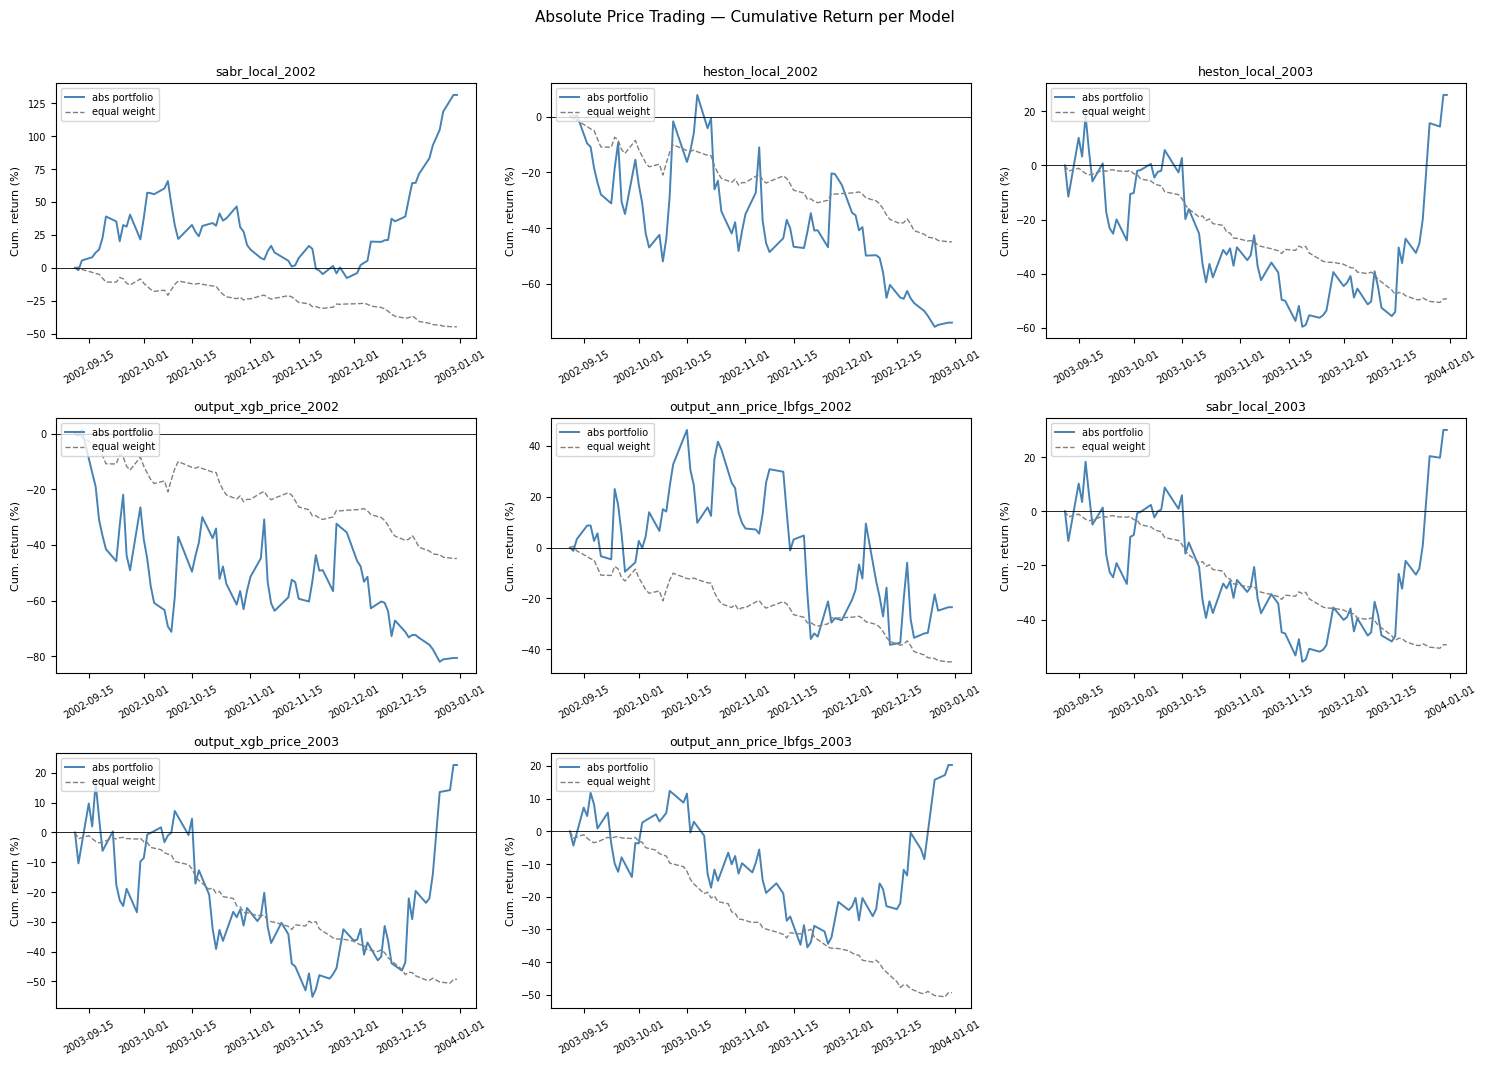

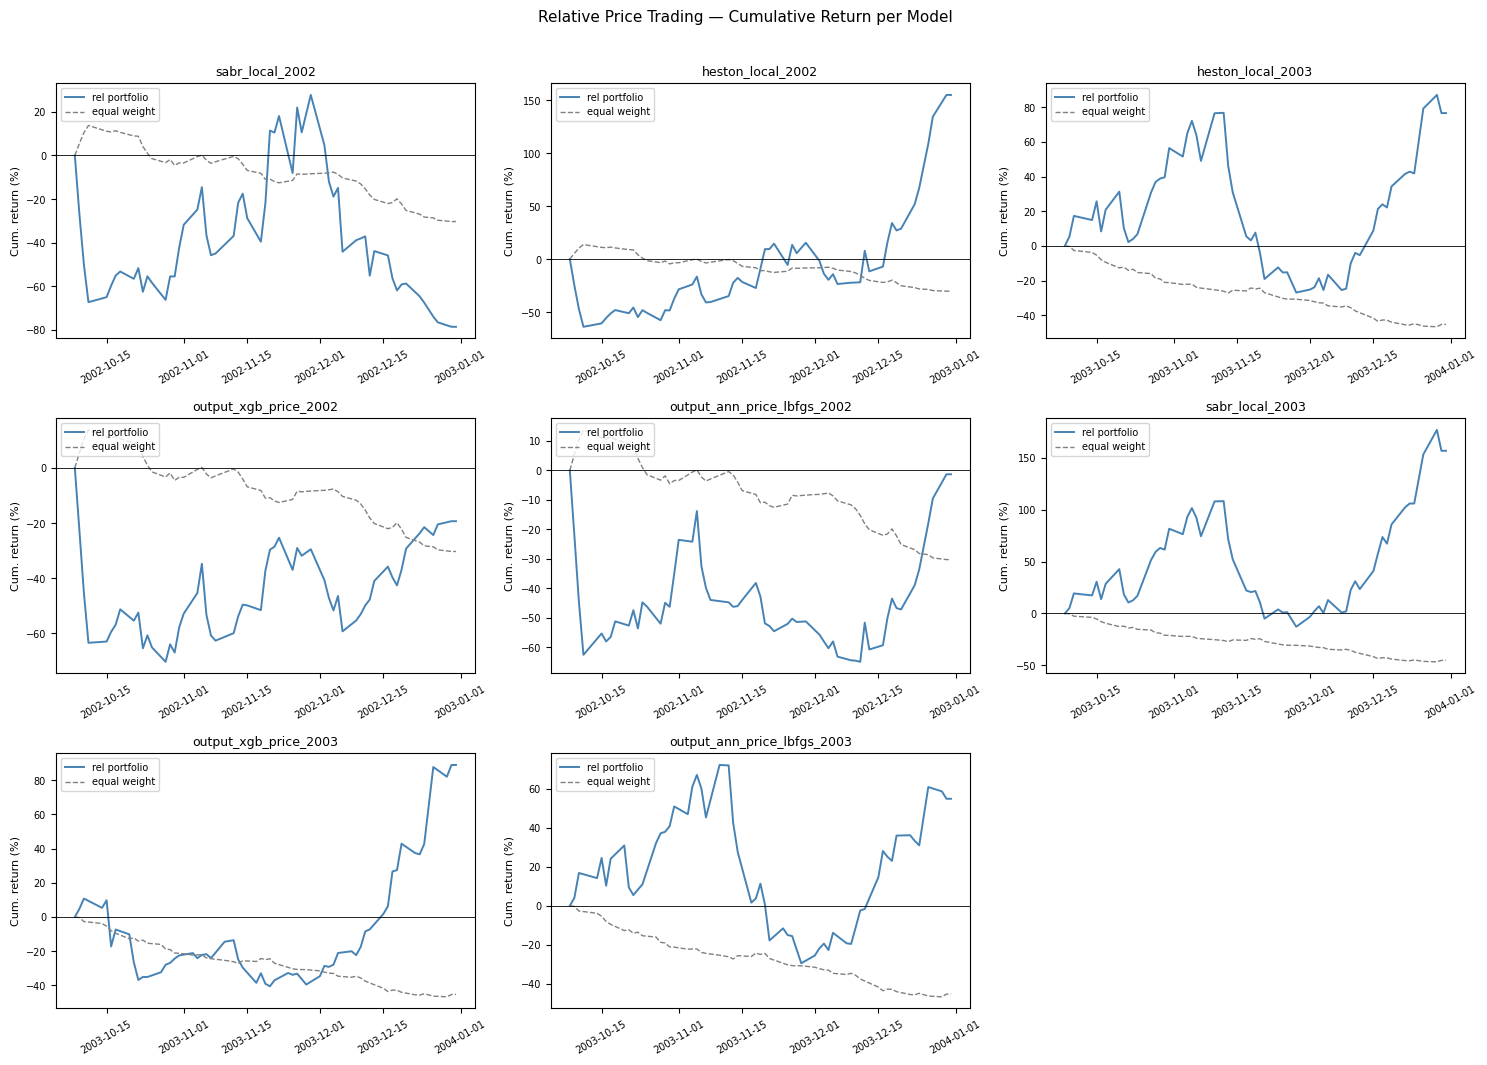

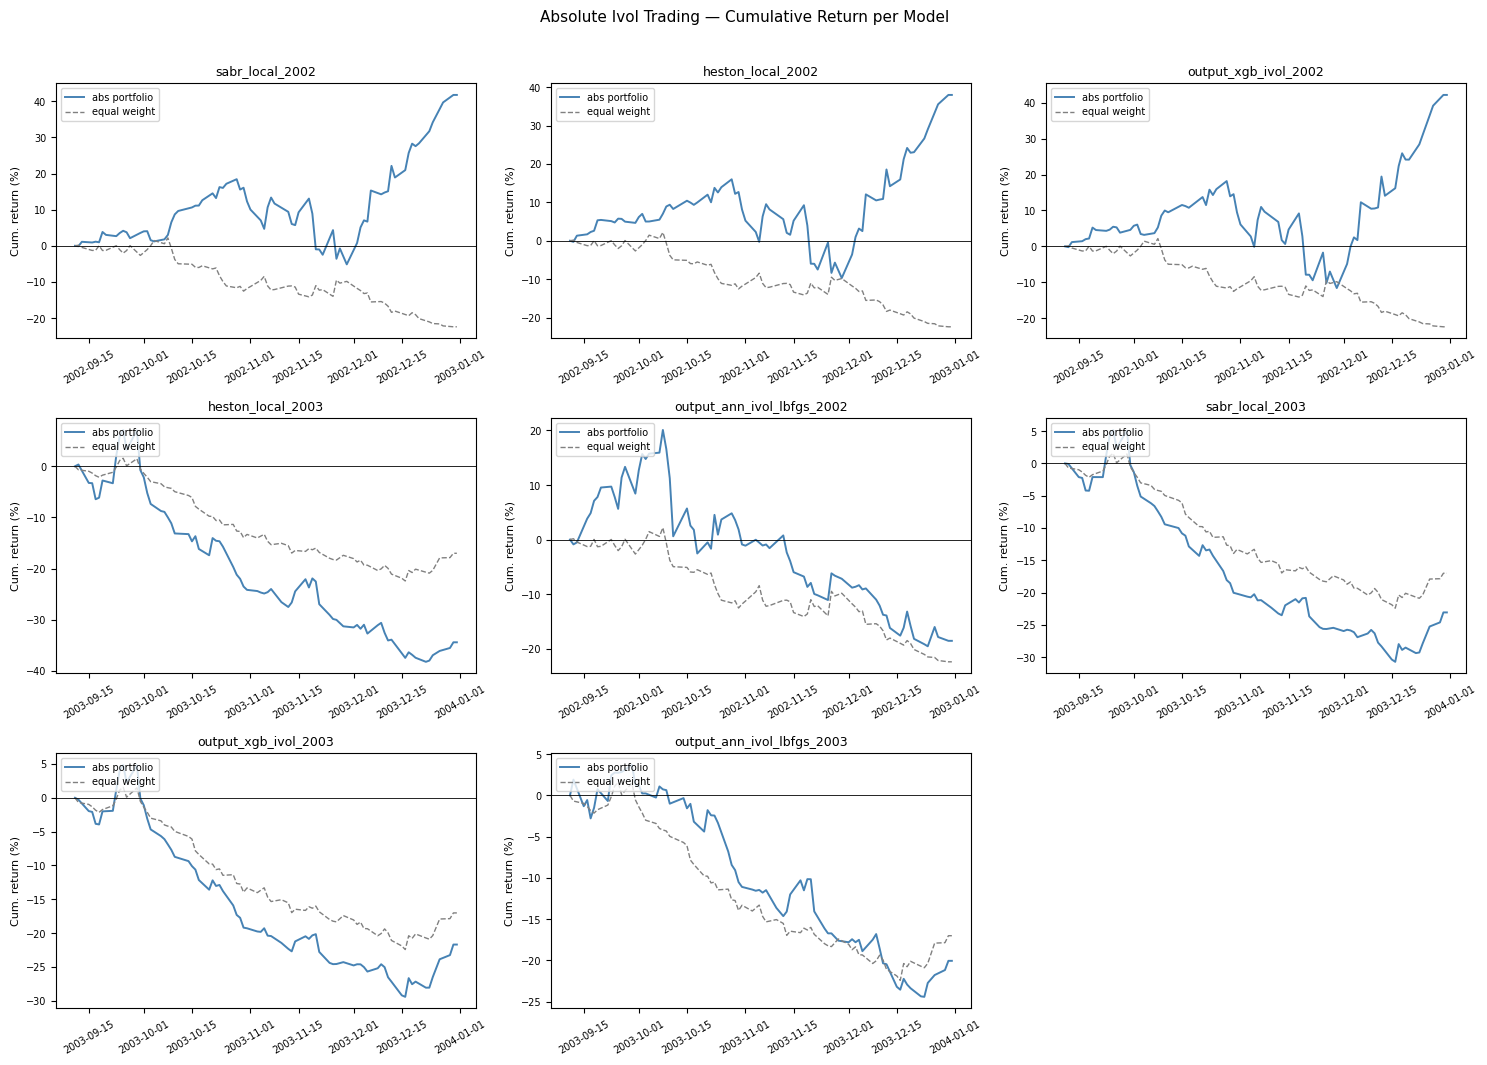

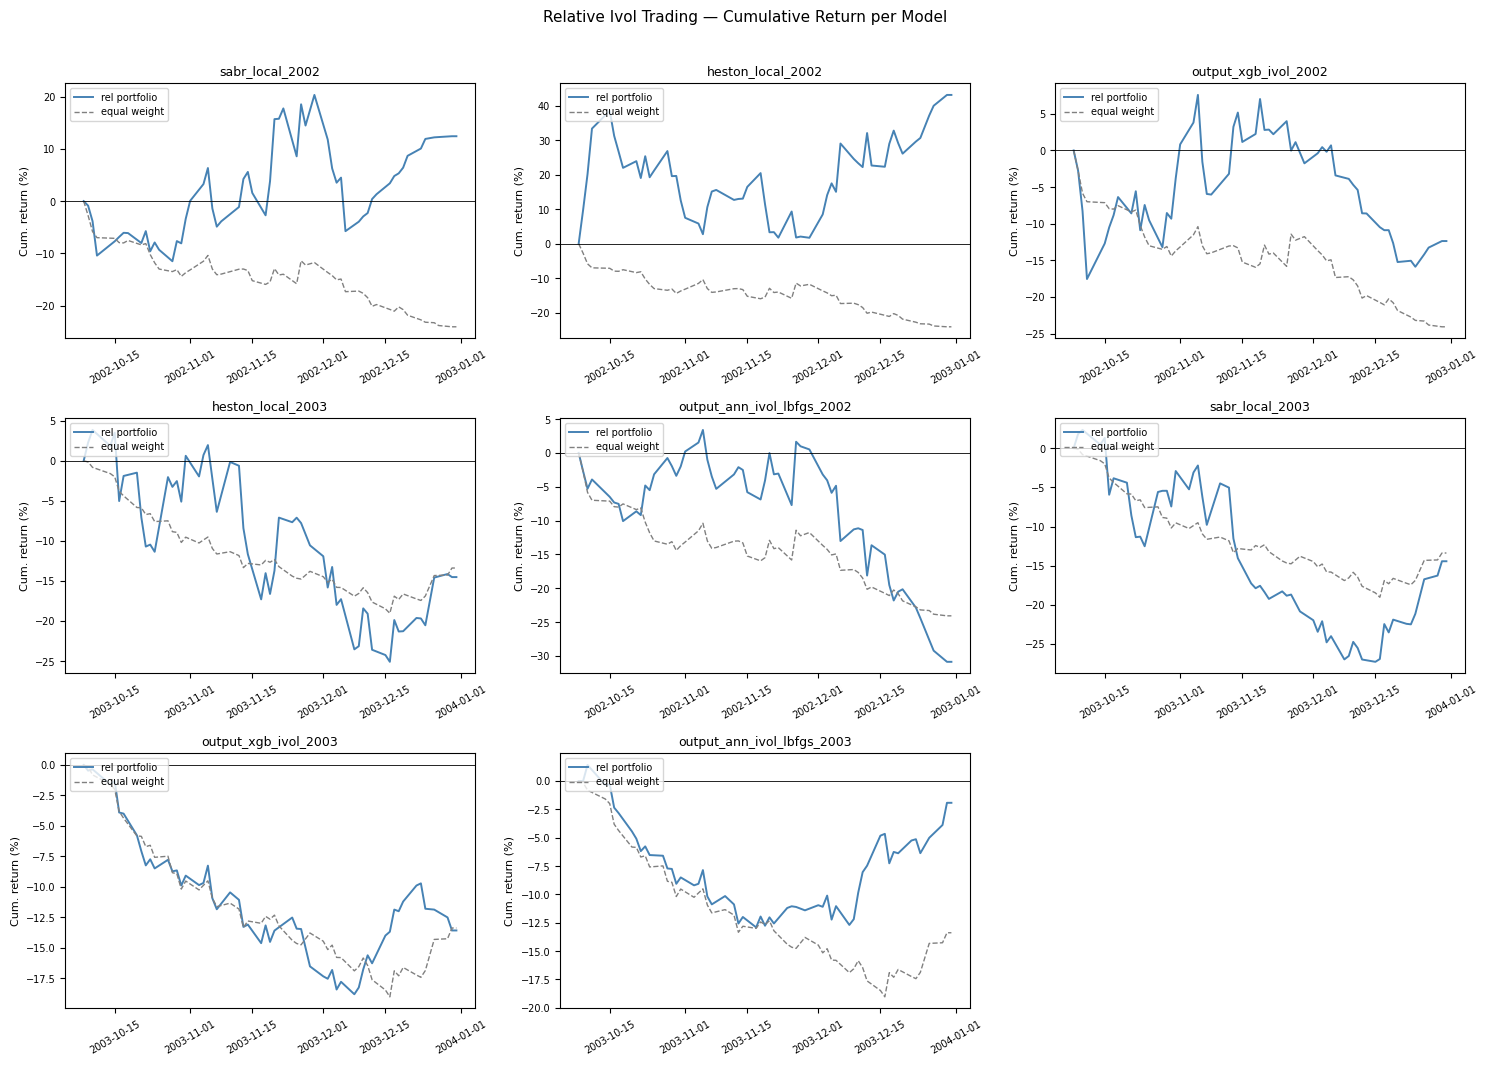

In [ ]:
# Plot cumulative returns

plot_trading_returns(price_weights_gpu, strategy='abs')
plot_trading_returns(price_weights_gpu, strategy='rel')

plot_trading_returns(ivol_weights_gpu, strategy='abs')
plot_trading_returns(ivol_weights_gpu, strategy='rel')

In [ ]:
def run_price_trading_strategies_partial_v2_gpu(
    dataset_configs,
    gamma             = 3,
    use_ewma          = True,
    ewma_lambda       = 0.94,
    train_size        = 0.7,
    min_oos_days      = 20,
    min_return_obs    = 3,
    l1_penalty_weight = 500,
    n_iter            = 5,
    lr                = 1.0,
    min_ttm           = 7/365,
    max_workers       = 4,
    verbose           = True,
):
    device = 'cuda' if torch.cuda.is_available() else 'cpu'
    if verbose:
        print(f"Device: {device}  |  max_workers: {max_workers}  |  use_ewma: {use_ewma}")

    def _process_one(cfg):
        name            = cfg['name']
        model_price_col = cfg['model_price_col']
        if model_price_col == '-NA-':
            return name, None, None, None, None, None

        if torch.cuda.is_available():
            stream = torch.cuda.Stream()
            ctx    = torch.cuda.stream(stream)
        else:
            ctx = contextlib.nullcontext()

        try:
          with ctx:
            data = pd.read_stata(cfg['path'])
            if 'index' in data.columns:
                data = data.drop('index', axis=1)
            data['optionid'] = data['optionid'].astype(float).astype(int)
            data['date']     = pd.to_datetime(data['date'])
            data = data[data['time_to_mat'] > min_ttm]

            oos_data = data[data['out_of_sample'] == 1].copy()
            is_data  = data[data['out_of_sample'] == 0].copy()

            market_pivot = data.pivot(index='date', columns='optionid', values='price')
            model_pivot  = oos_data.pivot(index='date', columns='optionid', values=model_price_col)

            oos_day_count = model_pivot.notna().sum()
            keep_opts = oos_day_count[oos_day_count >= min_oos_days].index
            market_pivot = market_pivot.reindex(columns=keep_opts)
            model_pivot  = model_pivot.reindex(columns=keep_opts)

            dates   = market_pivot.index.tolist()
            options = market_pivot.columns.tolist()
            T       = len(dates)
            n       = len(options)

            warmup_days = int(T * train_size)

            if verbose:
                print(f"  [{name}] Options (>={min_oos_days}d OOS): {n} x {T} days  "
                      f"(warmup: {warmup_days}, trading from day {warmup_days + 1})")

            if T <= warmup_days or n < 2:
                if verbose: print(f"  [{name}] Insufficient data; skipping")
                return name, None, None, None, None, None

            T_trade = T - warmup_days

            price_present = market_pivot.notna().values
            has_return = np.zeros((T, n), dtype=bool)
            has_return[1:] = price_present[:-1] & price_present[1:]
            cum_returns = np.cumsum(has_return, axis=0)

            oos_present = model_pivot.reindex(index=dates, columns=options).notna().values

            valid_full = oos_present & (cum_returns >= min_return_obs)
            valid_np   = valid_full[warmup_days:].astype(np.float32)

            mk_r_np = np.log(market_pivot / market_pivot.shift(1)).fillna(0).values
            mk_r_fwd_np = np.zeros_like(mk_r_np)
            mk_r_fwd_np[:-1] = mk_r_np[1:]
            mk_r_fwd_trade = mk_r_fwd_np[warmup_days:].astype(np.float32)

            mkt_prices = market_pivot.reindex(index=dates, columns=options).values
            mdl_prices = model_pivot.reindex(index=dates, columns=options).values

            with np.errstate(divide='ignore', invalid='ignore'):
                MU_abs_full = np.where(
                    np.abs(mkt_prices) > 1e-8,
                    (mdl_prices - mkt_prices) / np.abs(mkt_prices),
                    0.0)
            MU_abs_full = np.nan_to_num(MU_abs_full, nan=0.0, posinf=0.0, neginf=0.0)
            MU_abs_np = (MU_abs_full[warmup_days:] * valid_np).astype(np.float32)

            MU_rel_np = MU_abs_np.copy()
            for t in range(T_trade):
                mask_t = valid_np[t] > 0
                if mask_t.sum() >= 2:
                    med = np.median(MU_abs_np[t, mask_t.astype(bool)])
                    MU_rel_np[t] = (MU_abs_np[t] - med) * valid_np[t]

            relu = torch.nn.functional.relu
            rho  = l1_penalty_weight

            if not use_ewma:
                is_pivot = is_data.pivot(index='date', columns='optionid', values='price')
                is_pivot = is_pivot.reindex(columns=options)
                is_ret   = np.log(is_pivot / is_pivot.shift(1)).fillna(0).iloc[1:].values
                is_ret = np.nan_to_num(is_ret, nan=0.0).astype(np.float32)
                if is_ret.shape[0] > 1:
                    Sigma_np = np.cov(is_ret.T).astype(np.float32)
                else:
                    Sigma_np = np.eye(n, dtype=np.float32) * 1e-4
                Sigma_np += np.eye(n, dtype=np.float32) * 1e-6

                MU_abs_t   = torch.tensor(MU_abs_np, dtype=torch.float32, device=device)
                MU_rel_t   = torch.tensor(MU_rel_np, dtype=torch.float32, device=device)
                valid_t    = torch.tensor(valid_np,   dtype=torch.float32, device=device)
                Sigma_t    = torch.tensor(Sigma_np,   dtype=torch.float32, device=device)
                mk_r_fwd_t = torch.tensor(mk_r_fwd_trade, dtype=torch.float32, device=device)
                n_act_t    = valid_t.sum(dim=1)

                def _run_batched(MU_t):
                    R   = torch.zeros(T_trade, n, device=device, requires_grad=True)
                    opt = torch.optim.LBFGS([R], lr=lr, max_iter=20, line_search_fn='strong_wolfe')
                    def closure():
                        opt.zero_grad()
                        Wc = torch.tanh(R).clamp(-1, 1) * valid_t
                        vt = (Wc @ Sigma_t * Wc).sum(dim=1)
                        rt = (Wc * MU_t).sum(dim=1)
                        L1_budget = 1.0
                        l1_viol  = relu(Wc.abs().sum(dim=1) - L1_budget)
                        net_viol = relu(Wc.sum(dim=1).abs() - L1_budget)
                        loss = (gamma / 2 * vt - rt + rho * l1_viol.pow(2) + rho * net_viol.pow(2)).sum()
                        loss.backward()
                        return loss
                    for _ in range(n_iter):
                        opt.step(closure)
                    return (torch.tanh(R.detach()).clamp(-1, 1) * valid_t).cpu().numpy()

                W_abs = _run_batched(MU_abs_t)
                W_rel = _run_batched(MU_rel_t)

            else:
                warmup_ret = mk_r_np[1:warmup_days]
                warmup_ret = np.nan_to_num(warmup_ret, nan=0.0).astype(np.float32)
                if warmup_ret.shape[0] > 1:
                    Sigma_ewma = np.cov(warmup_ret.T).astype(np.float32)
                else:
                    Sigma_ewma = np.eye(n, dtype=np.float32) * 1e-4
                Sigma_ewma += np.eye(n, dtype=np.float32) * 1e-6

                valid_t     = torch.tensor(valid_np,   dtype=torch.float32, device=device)
                MU_abs_t    = torch.tensor(MU_abs_np,  dtype=torch.float32, device=device)
                MU_rel_t    = torch.tensor(MU_rel_np,  dtype=torch.float32, device=device)

                W_abs = np.zeros((T_trade, n), dtype=np.float32)
                W_rel = np.zeros((T_trade, n), dtype=np.float32)

                prev_r_abs = torch.zeros(n, device=device)
                prev_r_rel = torch.zeros(n, device=device)

                for t in range(T_trade):
                    day_idx  = warmup_days + t
                    valid_day = valid_t[t]
                    n_act     = int(valid_day.sum().item())

                    if n_act >= 2:
                        Sig_t = torch.tensor(Sigma_ewma, dtype=torch.float32, device=device)

                        def _opt_ewma(mu_row, prev_r):
                            r = torch.nn.Parameter(prev_r.clone())
                            opt = torch.optim.LBFGS([r], lr=lr, max_iter=20,
                                                    line_search_fn='strong_wolfe')
                            L1_budget = 1.0
                            def closure():
                                opt.zero_grad()
                                w = torch.tanh(r).clamp(-1, 1) * valid_day
                                vt = w @ Sig_t @ w
                                rt = torch.dot(w, mu_row)
                                l1_viol  = relu(w.abs().sum() - L1_budget)
                                net_viol = relu(w.sum().abs() - L1_budget)
                                loss = gamma / 2 * vt - rt + rho * l1_viol.pow(2) + rho * net_viol.pow(2)
                                loss.backward()
                                return loss
                            for _ in range(n_iter):
                                opt.step(closure)
                            w_out = (torch.tanh(r.detach()).clamp(-1, 1) * valid_day)
                            return w_out, r.detach()

                        w_abs_t, prev_r_abs = _opt_ewma(MU_abs_t[t], prev_r_abs)
                        w_rel_t, prev_r_rel = _opt_ewma(MU_rel_t[t], prev_r_rel)
                        W_abs[t] = w_abs_t.cpu().numpy()
                        W_rel[t] = w_rel_t.cpu().numpy()

                    r_t = np.nan_to_num(mk_r_np[day_idx], nan=0.0).astype(np.float32)
                    Sigma_ewma = (ewma_lambda * Sigma_ewma
                                  + (1 - ewma_lambda) * np.outer(r_t, r_t))
                    Sigma_ewma += np.eye(n, dtype=np.float32) * 1e-6

            trade_dates = dates[warmup_days:]
            mk_r_fwd_trade_np = np.nan_to_num(mk_r_fwd_trade, nan=0.0)

            port_ret_abs = pd.Series(
                (W_abs * mk_r_fwd_trade_np).sum(axis=1),
                index=trade_dates, name='portfolio_return')
            port_ret_rel = pd.Series(
                (W_rel * mk_r_fwd_trade_np).sum(axis=1),
                index=trade_dates, name='portfolio_return')

            valid_fwd = valid_np * mk_r_fwd_trade_np
            n_valid   = valid_np.sum(axis=1).clip(min=1)
            port_ret_eq_abs = pd.Series(
                valid_fwd.sum(axis=1) / n_valid,
                index=trade_dates, name='portfolio_return')
            port_ret_eq_rel = port_ret_eq_abs.copy()

            def _metrics(r):
                T_r     = len(r)
                total   = np.exp(r.sum()) - 1
                ann_ret = np.exp(r.sum() * 252 / T_r) - 1 if T_r > 0 else 0
                sharpe  = r.mean() / r.std() * np.sqrt(252) if r.std() > 0 else 0
                down    = r[r < 0]
                sortino = r.mean() / down.std() * np.sqrt(252) if len(down) > 1 and down.std() > 0 else 0
                cum     = np.exp(r.cumsum())
                mdd     = ((cum - cum.cummax()) / cum.cummax()).min()
                calmar  = ann_ret / abs(mdd) if mdd < 0 else 0
                win_pct = (r > 0).mean() * 100
                destroyed = total <= -0.99
                return dict(total=total, ann=ann_ret, sharpe=sharpe, sortino=sortino,
                            mdd=mdd, calmar=calmar, win=win_pct, destroyed=destroyed)

            m_abs    = _metrics(port_ret_abs)
            m_rel    = _metrics(port_ret_rel)
            m_eq_abs = _metrics(port_ret_eq_abs)
            m_eq_rel = _metrics(port_ret_eq_rel)

            if verbose:
                print(f"  [{name}] abs: {m_abs['total']:.2%} (Sharpe {m_abs['sharpe']:.2f}) | "
                      f"rel: {m_rel['total']:.2%} (Sharpe {m_rel['sharpe']:.2f})")

            df_abs = pd.DataFrame(W_abs, index=trade_dates, columns=options)
            df_abs['portfolio_return'] = port_ret_abs
            df_rel = pd.DataFrame(W_rel, index=trade_dates, columns=options)
            df_rel['portfolio_return'] = port_ret_rel

          row = {
              'dataset':         name,
              'abs_p_total_%':   round(m_abs['total']  * 100, 2),
              'abs_p_ann_%':     round(m_abs['ann']     * 100, 2),
              'abs_p_sharpe':    round(m_abs['sharpe'],        3),
              'abs_p_sortino':   round(m_abs['sortino'],       3),
              'abs_p_mdd_%':     round(m_abs['mdd']     * 100, 2),
              'abs_p_calmar':    round(m_abs['calmar'],        3),
              'abs_p_win_%':     round(m_abs['win'],           1),
              'rel_p_total_%':   round(m_rel['total']   * 100, 2),
              'rel_p_ann_%':     round(m_rel['ann']      * 100, 2),
              'rel_p_sharpe':    round(m_rel['sharpe'],        3),
              'rel_p_sortino':   round(m_rel['sortino'],       3),
              'rel_p_mdd_%':     round(m_rel['mdd']      * 100, 2),
              'rel_p_calmar':    round(m_rel['calmar'],        3),
              'rel_p_win_%':     round(m_rel['win'],           1),
              'eq_abs_p_total_%':  round(m_eq_abs['total']  * 100, 2),
              'eq_abs_p_sharpe':   round(m_eq_abs['sharpe'],      3),
              'eq_abs_p_mdd_%':    round(m_eq_abs['mdd']    * 100, 2),
              'eq_rel_p_total_%':  round(m_eq_rel['total']  * 100, 2),
              'eq_rel_p_sharpe':   round(m_eq_rel['sharpe'],      3),
              'eq_rel_p_mdd_%':    round(m_eq_rel['mdd']    * 100, 2),
              'abs_p_destroyed':   m_abs.get('destroyed', False),
              'rel_p_destroyed':   m_rel.get('destroyed', False),
          }
          return name, df_abs, df_rel, row, port_ret_eq_abs, port_ret_eq_rel
        except Exception as e:
            if verbose:
                import traceback; traceback.print_exc()
                print(f"  [{name}] SKIPPED — {e}")
            return name, None, None, None, None, None

    all_weights  = {}
    summary_rows = []
    with ThreadPoolExecutor(max_workers=min(len(dataset_configs), max_workers)) as pool:
        futures = {pool.submit(_process_one, cfg): cfg['name'] for cfg in dataset_configs}
        for fut in as_completed(futures):
            name, df_abs, df_rel, row, eq_abs, eq_rel = fut.result()
            if df_abs is None:
                continue
            all_weights[name] = {'abs_price': df_abs, 'rel_price': df_rel,
                                  'benchmark_abs': eq_abs, 'benchmark_rel': eq_rel}
            summary_rows.append(row)

    completed = {r['dataset'] for r in summary_rows}
    summary_df = (pd.DataFrame(summary_rows)
                    .set_index('dataset')
                    .loc[[c['name'] for c in dataset_configs if c['name'] in completed]])
    return all_weights, summary_df

In [ ]:
# Run partial-config price trading strategies
price_partial_weights, price_partial_summary = run_price_trading_strategies_partial_v2_gpu(
    DATASET_PARTIAL_CONFIGS_PRICE,
    gamma             = 3,
    use_ewma          = True,
    ewma_lambda       = 0.94,
    train_size        = 0.7,
    min_oos_days      = 20,
    l1_penalty_weight = 500,
    n_iter            = 5,
    lr                = 1.0,
    max_workers       = 4,
    verbose           = True,
)
print("\n=== Price trading summary (partial configs v2) ===")
display(price_partial_summary)

Device: cuda  |  max_workers: 4  |  use_ewma: True
  [heston_variable_2002] Options (>=20d OOS): 833 x 250 days  (warmup: 175, trading from day 176)  [sabr_variable_2002] Options (>=20d OOS): 833 x 250 days  (warmup: 175, trading from day 176)

  [sabr_surface_2002] Options (>=20d OOS): 833 x 250 days  (warmup: 175, trading from day 176)
  [heston_surface_2002] Options (>=20d OOS): 833 x 250 days  (warmup: 175, trading from day 176)
  [heston_surface_2002] abs: -73.02% (Sharpe -1.39) | rel: -73.22% (Sharpe -1.40)
  [surface_xgb_price_2002] Options (>=20d OOS): 833 x 250 days  (warmup: 175, trading from day 176)
  [sabr_surface_2002] abs: -64.23% (Sharpe -1.31) | rel: -64.24% (Sharpe -1.32)
  [surface_ann_price_lbfgs_2002] Options (>=20d OOS): 833 x 250 days  (warmup: 175, trading from day 176)
  [heston_variable_2002] abs: -75.47% (Sharpe -1.53) | rel: -74.78% (Sharpe -1.49)
  [variable_ann_price_lbfgs_2002] Options (>=20d OOS): 833 x 250 days  (warmup: 175, trading from day 176)
  [sa

,abs_p_total_%,abs_p_ann_%,abs_p_sharpe,abs_p_sortino,abs_p_mdd_%,abs_p_calmar,abs_p_win_%,rel_p_total_%,rel_p_ann_%,rel_p_sharpe,...,rel_p_calmar,rel_p_win_%,eq_abs_p_total_%,eq_abs_p_sharpe,eq_abs_p_mdd_%,eq_rel_p_total_%,eq_rel_p_sharpe,eq_rel_p_mdd_%,abs_p_destroyed,rel_p_destroyed
dataset,,,,,,,,,,,,,,,,,,,,,
heston_surface_2002,-73.019997,-98.779999,-1.393,-2.221,-76.489998,-1.291000,44.0,-73.220001,-98.800003,-1.403,...,-1.301000,44.0,-56.180000,-5.392,-55.529999,-56.180000,-5.392,-55.529999,False,False
heston_variable_2002,-75.470001,-99.110001,-1.533,-2.423,-76.320000,-1.299000,44.0,-74.779999,-99.019997,-1.493,...,-1.300000,44.0,-56.180000,-5.392,-55.529999,-56.180000,-5.392,-55.529999,False,False
sabr_surface_2002,-64.230003,-96.839996,-1.315,-2.340,-72.879997,-1.329000,41.3,-64.239998,-96.839996,-1.315,...,-1.333000,41.3,-56.180000,-5.392,-55.529999,-56.180000,-5.392,-55.529999,False,False
sabr_variable_2002,-64.339996,-96.870003,-1.308,-2.344,-72.940002,-1.328000,41.3,-61.610001,-95.989998,-1.222,...,-1.319000,41.3,-56.180000,-5.392,-55.529999,-56.180000,-5.392,-55.529999,False,False
surface_xgb_price_2002,34.610001,171.460007,0.431,0.477,-81.570000,2.102000,58.7,79.040001,607.750000,0.863,...,7.467000,56.0,-56.180000,-5.392,-55.529999,-56.180000,-5.392,-55.529999,False,False
surface_ann_price_lbfgs_2002,7.930000,29.250000,0.234,0.256,-40.389999,0.724000,54.7,1.040000,3.530000,0.030,...,0.082000,53.3,-56.180000,-5.392,-55.529999,-56.180000,-5.392,-55.529999,False,False
variable_ann_price_lbfgs_2002,213.820007,4564.850098,3.530,5.843,-19.209999,237.595993,58.7,169.070007,2681.979980,2.813,...,137.425995,61.3,-56.180000,-5.392,-55.529999,-56.180000,-5.392,-55.529999,False,False
heston_surface_2003,-17.629999,-47.880001,-0.426,-0.619,-65.860001,-0.727000,46.7,-19.500000,-51.750000,-0.472,...,-0.766000,46.7,-63.619999,-11.080,-64.139999,-63.619999,-11.080,-64.139999,False,False
heston_variable_2003,-25.790001,-63.290001,-0.673,-0.963,-67.029999,-0.944000,45.3,-24.719999,-61.490002,-0.636,...,-0.907000,44.0,-63.619999,-11.080,-64.139999,-63.619999,-11.080,-64.139999,False,False


In [ ]:
def run_ivol_trading_strategies_partial_v2_gpu(
    dataset_configs,
    gamma             = 3,
    use_ewma          = True,
    ewma_lambda       = 0.94,
    train_size        = 0.7,
    min_oos_days      = 20,
    min_return_obs    = 3,
    l1_penalty_weight = 500,
    n_iter            = 5,
    lr                = 1.0,
    min_ttm           = 7/365,
    max_workers       = 4,
    verbose           = True,
):
    device = 'cuda' if torch.cuda.is_available() else 'cpu'
    if verbose:
        print(f"Device: {device}  |  max_workers: {max_workers}  |  use_ewma: {use_ewma}")

    def _process_one(cfg):
        name       = cfg['name']
        model_ivol = cfg['model_ivol_col']
        if model_ivol == '-NA-':
            return name, None, None, None, None, None

        if torch.cuda.is_available():
            stream = torch.cuda.Stream()
            ctx    = torch.cuda.stream(stream)
        else:
            ctx = contextlib.nullcontext()

        try:
          with ctx:
            data = pd.read_stata(cfg['path'])
            if 'index' in data.columns:
                data = data.drop('index', axis=1)
            data['optionid'] = data['optionid'].astype(float).astype(int)
            data['date']     = pd.to_datetime(data['date'])
            data = data[data['time_to_mat'] > min_ttm]

            oos_data = data[data['out_of_sample'] == 1].copy()
            is_data  = data[data['out_of_sample'] == 0].copy()

            straddle_all = straddle_funct(data,     'price')
            straddle_oos = straddle_funct(oos_data, model_ivol)
            straddle_is  = straddle_funct(is_data,  'price')

            def _piv(df_s, col):
                return df_s.pivot(index='date', columns='straddle_id', values=col)

            price_piv_all = _piv(straddle_all, 'price_straddle')
            price_piv_is  = _piv(straddle_is,  'price_straddle')
            mkt_iv_piv    = _piv(straddle_oos, 'iv_straddle')
            mdl_iv_piv    = _piv(straddle_oos, 'iv_model_straddle')
            vega_piv      = _piv(straddle_oos, 'vega_straddle')

            oos_day_count = mdl_iv_piv.notna().sum()
            keep_straddles = oos_day_count[oos_day_count >= min_oos_days].index

            price_piv_all = price_piv_all.reindex(columns=keep_straddles)
            price_piv_is  = price_piv_is.reindex(columns=keep_straddles)
            mkt_iv_piv    = mkt_iv_piv.reindex(columns=keep_straddles)
            mdl_iv_piv    = mdl_iv_piv.reindex(columns=keep_straddles)
            vega_piv      = vega_piv.reindex(columns=keep_straddles)

            dates      = price_piv_all.index.tolist()
            straddles  = price_piv_all.columns.tolist()
            T          = len(dates)
            n          = len(straddles)

            warmup_days = int(T * train_size)

            if verbose:
                print(f"  [{name}] Straddles (>={min_oos_days}d OOS): {n} x {T} days  "
                      f"(warmup: {warmup_days}, trading from day {warmup_days + 1})")

            if T <= warmup_days or n < 2:
                if verbose: print(f"  [{name}] Insufficient data; skipping")
                return name, None, None, None, None, None

            T_trade = T - warmup_days

            price_present = price_piv_all.notna().values
            has_return = np.zeros((T, n), dtype=bool)
            has_return[1:] = price_present[:-1] & price_present[1:]
            cum_returns = np.cumsum(has_return, axis=0)

            oos_present = (mdl_iv_piv.reindex(index=dates, columns=straddles).notna().values
                           & mkt_iv_piv.reindex(index=dates, columns=straddles).notna().values
                           & vega_piv.reindex(index=dates, columns=straddles).notna().values)

            valid_full = oos_present & (cum_returns >= min_return_obs)
            valid_np   = valid_full[warmup_days:].astype(np.float32)

            sp_r_np = np.log(price_piv_all / price_piv_all.shift(1)).fillna(0).values
            sp_r_fwd_np = np.zeros_like(sp_r_np)
            sp_r_fwd_np[:-1] = sp_r_np[1:]
            sp_r_fwd_trade = sp_r_fwd_np[warmup_days:].astype(np.float32)

            mkt_iv_vals = mkt_iv_piv.reindex(index=dates, columns=straddles).values
            mdl_iv_vals = mdl_iv_piv.reindex(index=dates, columns=straddles).values
            vega_vals   = vega_piv.reindex(index=dates, columns=straddles).values

            MU_abs_full = np.nan_to_num(
                (mdl_iv_vals - mkt_iv_vals) * vega_vals,
                nan=0.0, posinf=0.0, neginf=0.0)
            MU_abs_np = (MU_abs_full[warmup_days:] * valid_np).astype(np.float32)

            MU_rel_np = MU_abs_np.copy()
            for t in range(T_trade):
                mask_t = valid_np[t] > 0
                if mask_t.sum() >= 2:
                    med = np.median(MU_abs_np[t, mask_t.astype(bool)])
                    MU_rel_np[t] = (MU_abs_np[t] - med) * valid_np[t]

            relu = torch.nn.functional.relu
            rho  = l1_penalty_weight

            if not use_ewma:
                is_ret = np.log(price_piv_is / price_piv_is.shift(1)).fillna(0).iloc[1:].values
                is_ret = np.nan_to_num(is_ret, nan=0.0).astype(np.float32)
                if is_ret.shape[0] > 1:
                    Sigma_np = np.cov(is_ret.T).astype(np.float32)
                else:
                    Sigma_np = np.eye(n, dtype=np.float32) * 1e-4
                Sigma_np += np.eye(n, dtype=np.float32) * 1e-6

                MU_abs_t = torch.tensor(MU_abs_np, dtype=torch.float32, device=device)
                MU_rel_t = torch.tensor(MU_rel_np, dtype=torch.float32, device=device)
                valid_t  = torch.tensor(valid_np,   dtype=torch.float32, device=device)
                Sigma_t  = torch.tensor(Sigma_np,   dtype=torch.float32, device=device)
                n_act_t  = valid_t.sum(dim=1)

                def _run_batched(MU_t):
                    R   = torch.zeros(T_trade, n, device=device, requires_grad=True)
                    opt = torch.optim.LBFGS([R], lr=lr, max_iter=20, line_search_fn='strong_wolfe')
                    def closure():
                        opt.zero_grad()
                        Wc = torch.tanh(R).clamp(-1, 1) * valid_t
                        vt = (Wc @ Sigma_t * Wc).sum(dim=1)
                        rt = (Wc * MU_t).sum(dim=1)
                        L1_budget = 1.0
                        l1_viol = relu(Wc.abs().sum(dim=1) - L1_budget)
                        loss = (gamma / 2 * vt - rt + rho * l1_viol.pow(2)).sum()
                        loss.backward()
                        return loss
                    for _ in range(n_iter):
                        opt.step(closure)
                    return (torch.tanh(R.detach()).clamp(-1, 1) * valid_t).cpu().numpy()

                W_abs = _run_batched(MU_abs_t)
                W_rel = _run_batched(MU_rel_t)

            else:
                warmup_ret = sp_r_np[1:warmup_days]
                warmup_ret = np.nan_to_num(warmup_ret, nan=0.0).astype(np.float32)
                if warmup_ret.shape[0] > 1:
                    Sigma_ewma = np.cov(warmup_ret.T).astype(np.float32)
                else:
                    Sigma_ewma = np.eye(n, dtype=np.float32) * 1e-4
                Sigma_ewma += np.eye(n, dtype=np.float32) * 1e-6

                valid_t  = torch.tensor(valid_np,  dtype=torch.float32, device=device)
                MU_abs_t = torch.tensor(MU_abs_np, dtype=torch.float32, device=device)
                MU_rel_t = torch.tensor(MU_rel_np, dtype=torch.float32, device=device)

                W_abs = np.zeros((T_trade, n), dtype=np.float32)
                W_rel = np.zeros((T_trade, n), dtype=np.float32)

                prev_r_abs = torch.zeros(n, device=device)
                prev_r_rel = torch.zeros(n, device=device)

                for t in range(T_trade):
                    day_idx   = warmup_days + t
                    valid_day = valid_t[t]
                    n_act     = int(valid_day.sum().item())

                    if n_act >= 2:
                        Sig_t = torch.tensor(Sigma_ewma, dtype=torch.float32, device=device)

                        def _opt_ewma(mu_row, prev_r):
                            r = torch.nn.Parameter(prev_r.clone())
                            opt = torch.optim.LBFGS([r], lr=lr, max_iter=20,
                                                    line_search_fn='strong_wolfe')
                            L1_budget = 1.0
                            def closure():
                                opt.zero_grad()
                                w = torch.tanh(r).clamp(-1, 1) * valid_day
                                vt = w @ Sig_t @ w
                                rt = torch.dot(w, mu_row)
                                l1_viol = relu(w.abs().sum() - L1_budget)
                                loss = gamma / 2 * vt - rt + rho * l1_viol.pow(2)
                                loss.backward()
                                return loss
                            for _ in range(n_iter):
                                opt.step(closure)
                            w_out = (torch.tanh(r.detach()).clamp(-1, 1) * valid_day)
                            return w_out, r.detach()

                        w_abs_t, prev_r_abs = _opt_ewma(MU_abs_t[t], prev_r_abs)
                        w_rel_t, prev_r_rel = _opt_ewma(MU_rel_t[t], prev_r_rel)
                        W_abs[t] = w_abs_t.cpu().numpy()
                        W_rel[t] = w_rel_t.cpu().numpy()

                    r_t = np.nan_to_num(sp_r_np[day_idx], nan=0.0).astype(np.float32)
                    Sigma_ewma = (ewma_lambda * Sigma_ewma
                                  + (1 - ewma_lambda) * np.outer(r_t, r_t))
                    Sigma_ewma += np.eye(n, dtype=np.float32) * 1e-6

            trade_dates = dates[warmup_days:]
            sp_r_fwd_trade_np = np.nan_to_num(sp_r_fwd_trade, nan=0.0)

            port_ret_abs = pd.Series(
                (W_abs * sp_r_fwd_trade_np).sum(axis=1),
                index=trade_dates, name='portfolio_return')
            port_ret_rel = pd.Series(
                (W_rel * sp_r_fwd_trade_np).sum(axis=1),
                index=trade_dates, name='portfolio_return')

            valid_fwd = valid_np * sp_r_fwd_trade_np
            n_valid   = valid_np.sum(axis=1).clip(min=1)
            port_ret_eq_abs = pd.Series(
                valid_fwd.sum(axis=1) / n_valid,
                index=trade_dates, name='portfolio_return')
            port_ret_eq_rel = port_ret_eq_abs.copy()

            def _metrics(r):
                T_r     = len(r)
                total   = np.exp(r.sum()) - 1
                ann_ret = np.exp(r.sum() * 252 / T_r) - 1 if T_r > 0 else 0
                sharpe  = r.mean() / r.std() * np.sqrt(252) if r.std() > 0 else 0
                down    = r[r < 0]
                sortino = r.mean() / down.std() * np.sqrt(252) if len(down) > 1 and down.std() > 0 else 0
                cum     = np.exp(r.cumsum())
                mdd     = ((cum - cum.cummax()) / cum.cummax()).min()
                calmar  = ann_ret / abs(mdd) if mdd < 0 else 0
                win_pct = (r > 0).mean() * 100
                destroyed = total <= -0.99
                return dict(total=total, ann=ann_ret, sharpe=sharpe, sortino=sortino,
                            mdd=mdd, calmar=calmar, win=win_pct, destroyed=destroyed)

            m_abs    = _metrics(port_ret_abs)
            m_rel    = _metrics(port_ret_rel)
            m_eq_abs = _metrics(port_ret_eq_abs)
            m_eq_rel = _metrics(port_ret_eq_rel)

            if verbose:
                print(f"  [{name}] abs: {m_abs['total']:.2%} (Sharpe {m_abs['sharpe']:.2f}) | "
                      f"rel: {m_rel['total']:.2%} (Sharpe {m_rel['sharpe']:.2f})")

            df_abs = pd.DataFrame(W_abs, index=trade_dates, columns=straddles)
            df_abs['portfolio_return'] = port_ret_abs
            df_rel = pd.DataFrame(W_rel, index=trade_dates, columns=straddles)
            df_rel['portfolio_return'] = port_ret_rel

          row = {
              'dataset':          name,
              'abs_iv_total_%':   round(m_abs['total']  * 100, 2),
              'abs_iv_ann_%':     round(m_abs['ann']     * 100, 2),
              'abs_iv_sharpe':    round(m_abs['sharpe'],        3),
              'abs_iv_sortino':   round(m_abs['sortino'],       3),
              'abs_iv_mdd_%':     round(m_abs['mdd']     * 100, 2),
              'abs_iv_calmar':    round(m_abs['calmar'],        3),
              'abs_iv_win_%':     round(m_abs['win'],           1),
              'rel_iv_total_%':   round(m_rel['total']   * 100, 2),
              'rel_iv_ann_%':     round(m_rel['ann']      * 100, 2),
              'rel_iv_sharpe':    round(m_rel['sharpe'],        3),
              'rel_iv_sortino':   round(m_rel['sortino'],       3),
              'rel_iv_mdd_%':     round(m_rel['mdd']      * 100, 2),
              'rel_iv_calmar':    round(m_rel['calmar'],        3),
              'rel_iv_win_%':     round(m_rel['win'],           1),
              'eq_abs_iv_total_%':  round(m_eq_abs['total']  * 100, 2),
              'eq_abs_iv_sharpe':   round(m_eq_abs['sharpe'],      3),
              'eq_abs_iv_mdd_%':    round(m_eq_abs['mdd']    * 100, 2),
              'eq_rel_iv_total_%':  round(m_eq_rel['total']  * 100, 2),
              'eq_rel_iv_sharpe':   round(m_eq_rel['sharpe'],      3),
              'eq_rel_iv_mdd_%':    round(m_eq_rel['mdd']    * 100, 2),
              'abs_iv_destroyed':   m_abs.get('destroyed', False),
              'rel_iv_destroyed':   m_rel.get('destroyed', False),
          }
          return name, df_abs, df_rel, row, port_ret_eq_abs, port_ret_eq_rel
        except Exception as e:
            if verbose:
                import traceback; traceback.print_exc()
                print(f"  [{name}] SKIPPED — {e}")
            return name, None, None, None, None, None

    all_weights  = {}
    summary_rows = []
    with ThreadPoolExecutor(max_workers=min(len(dataset_configs), max_workers)) as pool:
        futures = {pool.submit(_process_one, cfg): cfg['name'] for cfg in dataset_configs}
        for fut in as_completed(futures):
            name, df_abs, df_rel, row, eq_abs, eq_rel = fut.result()
            if df_abs is None:
                continue
            all_weights[name] = {'abs_ivol': df_abs, 'rel_ivol': df_rel,
                                  'benchmark_abs': eq_abs, 'benchmark_rel': eq_rel}
            summary_rows.append(row)

    completed = {r['dataset'] for r in summary_rows}
    summary_df = (pd.DataFrame(summary_rows)
                    .set_index('dataset')
                    .loc[[c['name'] for c in dataset_configs if c['name'] in completed]])
    return all_weights, summary_df

In [ ]:
# Run partial-config ivol trading strategies
ivol_partial_weights, ivol_partial_summary = run_ivol_trading_strategies_partial_v2_gpu(
    DATASET_PARTIAL_CONFIGS_IVOL,
    gamma             = 3,
    use_ewma          = True,
    ewma_lambda       = 0.94,
    train_size        = 0.7,
    min_oos_days      = 10,
    l1_penalty_weight = 500,
    n_iter            = 5,
    lr                = 1.0,
    max_workers       = 4,
    verbose           = True,
)
print("\n=== Ivol trading summary (partial configs v2) ===")
display(ivol_partial_summary)

Device: cuda  |  max_workers: 4  |  use_ewma: True
  [heston_surface_2002] Straddles (>=10d OOS): 187 x 250 days  (warmup: 175, trading from day 176)
  [sabr_variable_2002] Straddles (>=10d OOS): 187 x 250 days  (warmup: 175, trading from day 176)
  [heston_variable_2002] Straddles (>=10d OOS): 187 x 250 days  (warmup: 175, trading from day 176)
  [sabr_surface_2002] Straddles (>=10d OOS): 187 x 250 days  (warmup: 175, trading from day 176)
  [sabr_surface_2002] abs: 19.04% (Sharpe 0.96) | rel: 86.87% (Sharpe 2.70)
  [surface_xgb_ivol_2002] Straddles (>=10d OOS): 187 x 250 days  (warmup: 175, trading from day 176)
  [sabr_variable_2002] abs: 19.13% (Sharpe 0.98) | rel: 38.77% (Sharpe 1.70)
  [surface_ann_ivol_lbfgs_2002] Straddles (>=10d OOS): 187 x 250 days  (warmup: 175, trading from day 176)
  [heston_variable_2002] abs: 53.06% (Sharpe 1.85) | rel: 121.09% (Sharpe 3.16)
  [variable_ann_ivol_lbfgs_2002] Straddles (>=10d OOS): 187 x 250 days  (warmup: 175, trading from day 176)
  [hes

,abs_iv_total_%,abs_iv_ann_%,abs_iv_sharpe,abs_iv_sortino,abs_iv_mdd_%,abs_iv_calmar,abs_iv_win_%,rel_iv_total_%,rel_iv_ann_%,rel_iv_sharpe,...,rel_iv_calmar,rel_iv_win_%,eq_abs_iv_total_%,eq_abs_iv_sharpe,eq_abs_iv_mdd_%,eq_rel_iv_total_%,eq_rel_iv_sharpe,eq_rel_iv_mdd_%,abs_iv_destroyed,rel_iv_destroyed
dataset,,,,,,,,,,,,,,,,,,,,,
heston_surface_2002,34.220001,168.800003,1.206,1.553,-32.130001,5.255,56.0,64.690002,434.589996,1.813,...,16.273001,53.3,-32.840000,-3.375,-39.750000,-32.840000,-3.375,-39.750000,False,False
heston_variable_2002,53.060001,317.980011,1.854,3.381,-30.959999,10.269,56.0,121.089996,1337.930054,3.158,...,56.817001,52.0,-32.840000,-3.375,-39.750000,-32.840000,-3.375,-39.750000,False,False
sabr_surface_2002,19.040001,79.589996,0.957,1.417,-20.280001,3.925,49.3,86.870003,717.250000,2.701,...,34.720001,54.7,-32.840000,-3.375,-39.750000,-32.840000,-3.375,-39.750000,False,False
sabr_variable_2002,19.129999,80.059998,0.979,1.604,-20.940001,3.824,50.7,38.770000,200.679993,1.698,...,10.480000,46.7,-32.840000,-3.375,-39.750000,-32.840000,-3.375,-39.750000,False,False
surface_xgb_ivol_2002,-6.530000,-20.290001,-0.406,-0.679,-23.820000,-0.852,44.0,-19.980000,-52.709999,-1.148,...,-1.506000,52.0,-32.840000,-3.375,-39.750000,-32.840000,-3.375,-39.750000,False,False
surface_ann_ivol_lbfgs_2002,-26.670000,-64.739998,-1.515,-2.288,-38.680000,-1.674,44.0,-40.209999,-82.239998,-2.445,...,-1.563000,38.7,-32.840000,-3.375,-39.750000,-32.840000,-3.375,-39.750000,False,False
variable_ann_ivol_lbfgs_2002,-10.880000,-32.099998,-0.446,-0.482,-25.030001,-1.283,54.7,15.860000,64.010002,0.907,...,4.000000,52.0,-32.840000,-3.375,-39.750000,-32.840000,-3.375,-39.750000,False,False
heston_surface_2003,-35.459999,-77.029999,-2.682,-3.865,-38.369999,-2.008,44.0,-42.259998,-84.199997,-2.890,...,-1.710000,45.3,-32.049999,-3.401,-36.619999,-32.049999,-3.401,-36.619999,False,False
heston_variable_2003,-44.430000,-86.110001,-3.797,-5.487,-45.830002,-1.879,41.3,-26.740000,-64.849998,-1.596,...,-1.782000,45.3,-32.049999,-3.401,-36.619999,-32.049999,-3.401,-36.619999,False,False


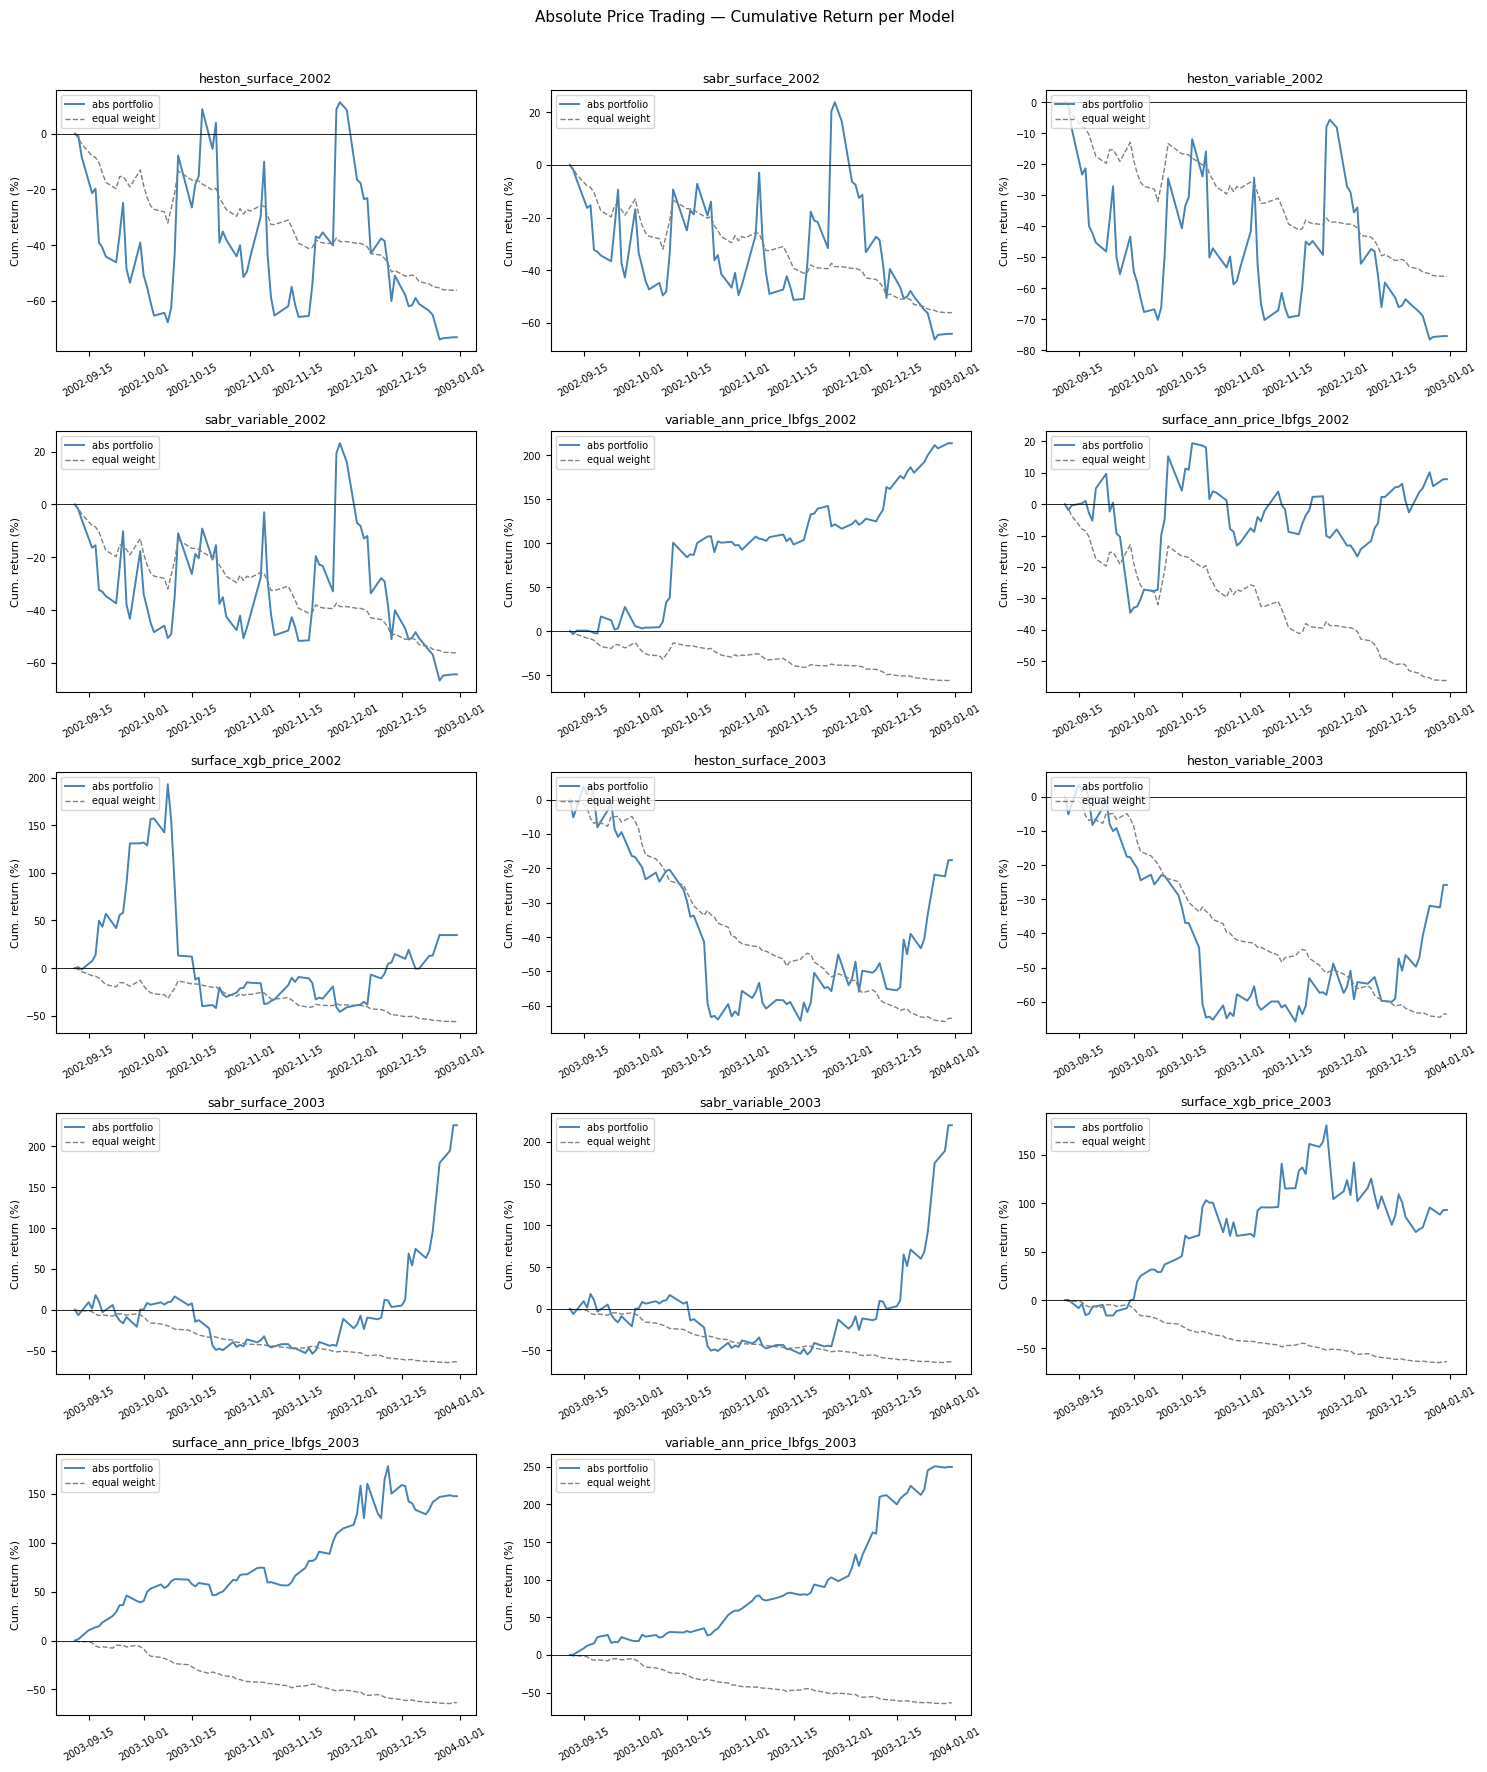

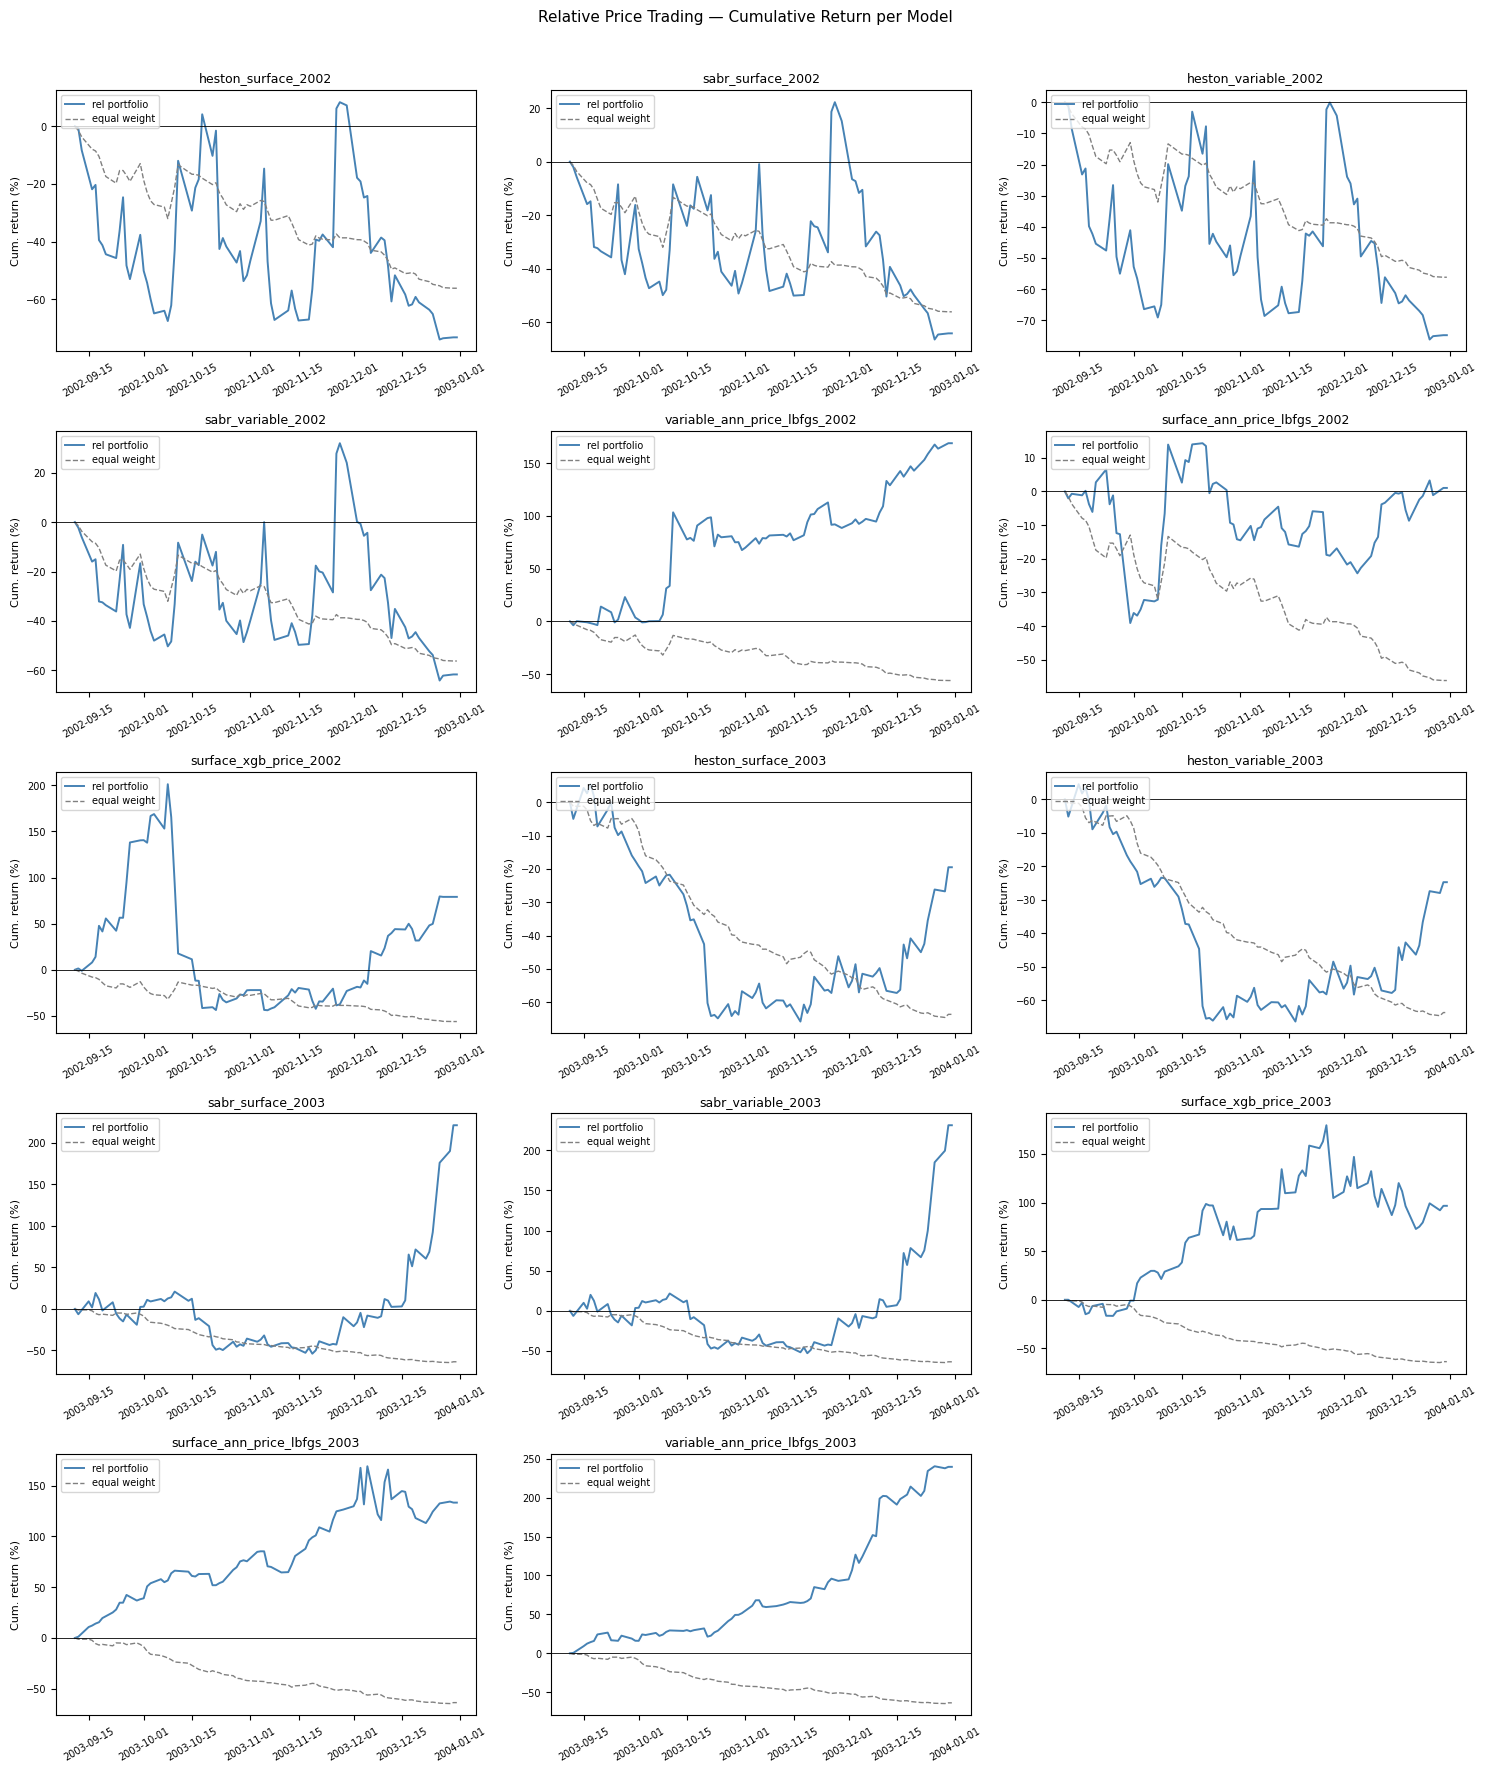

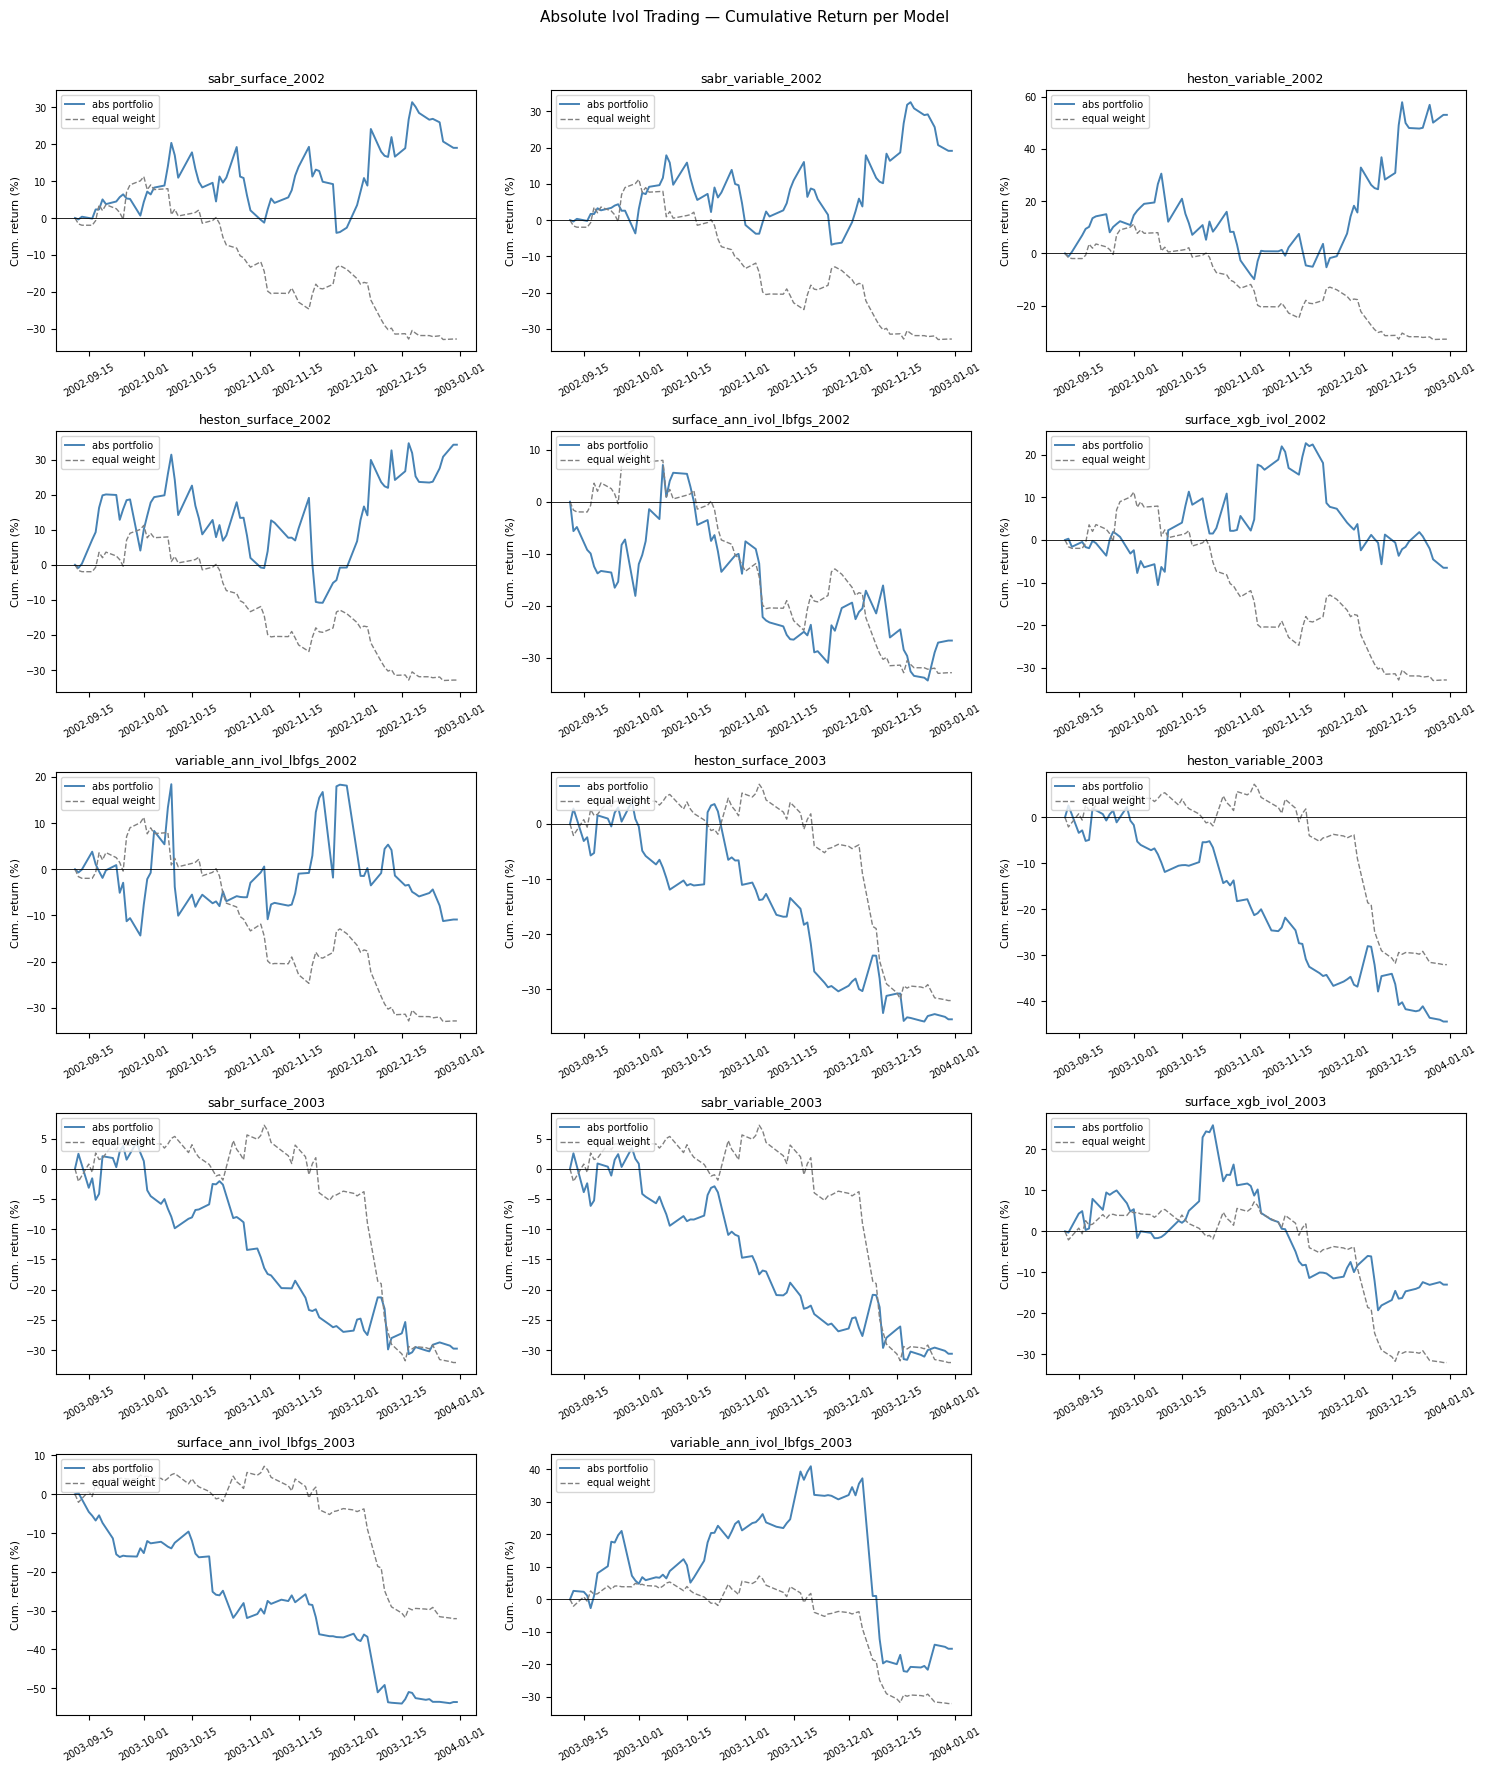

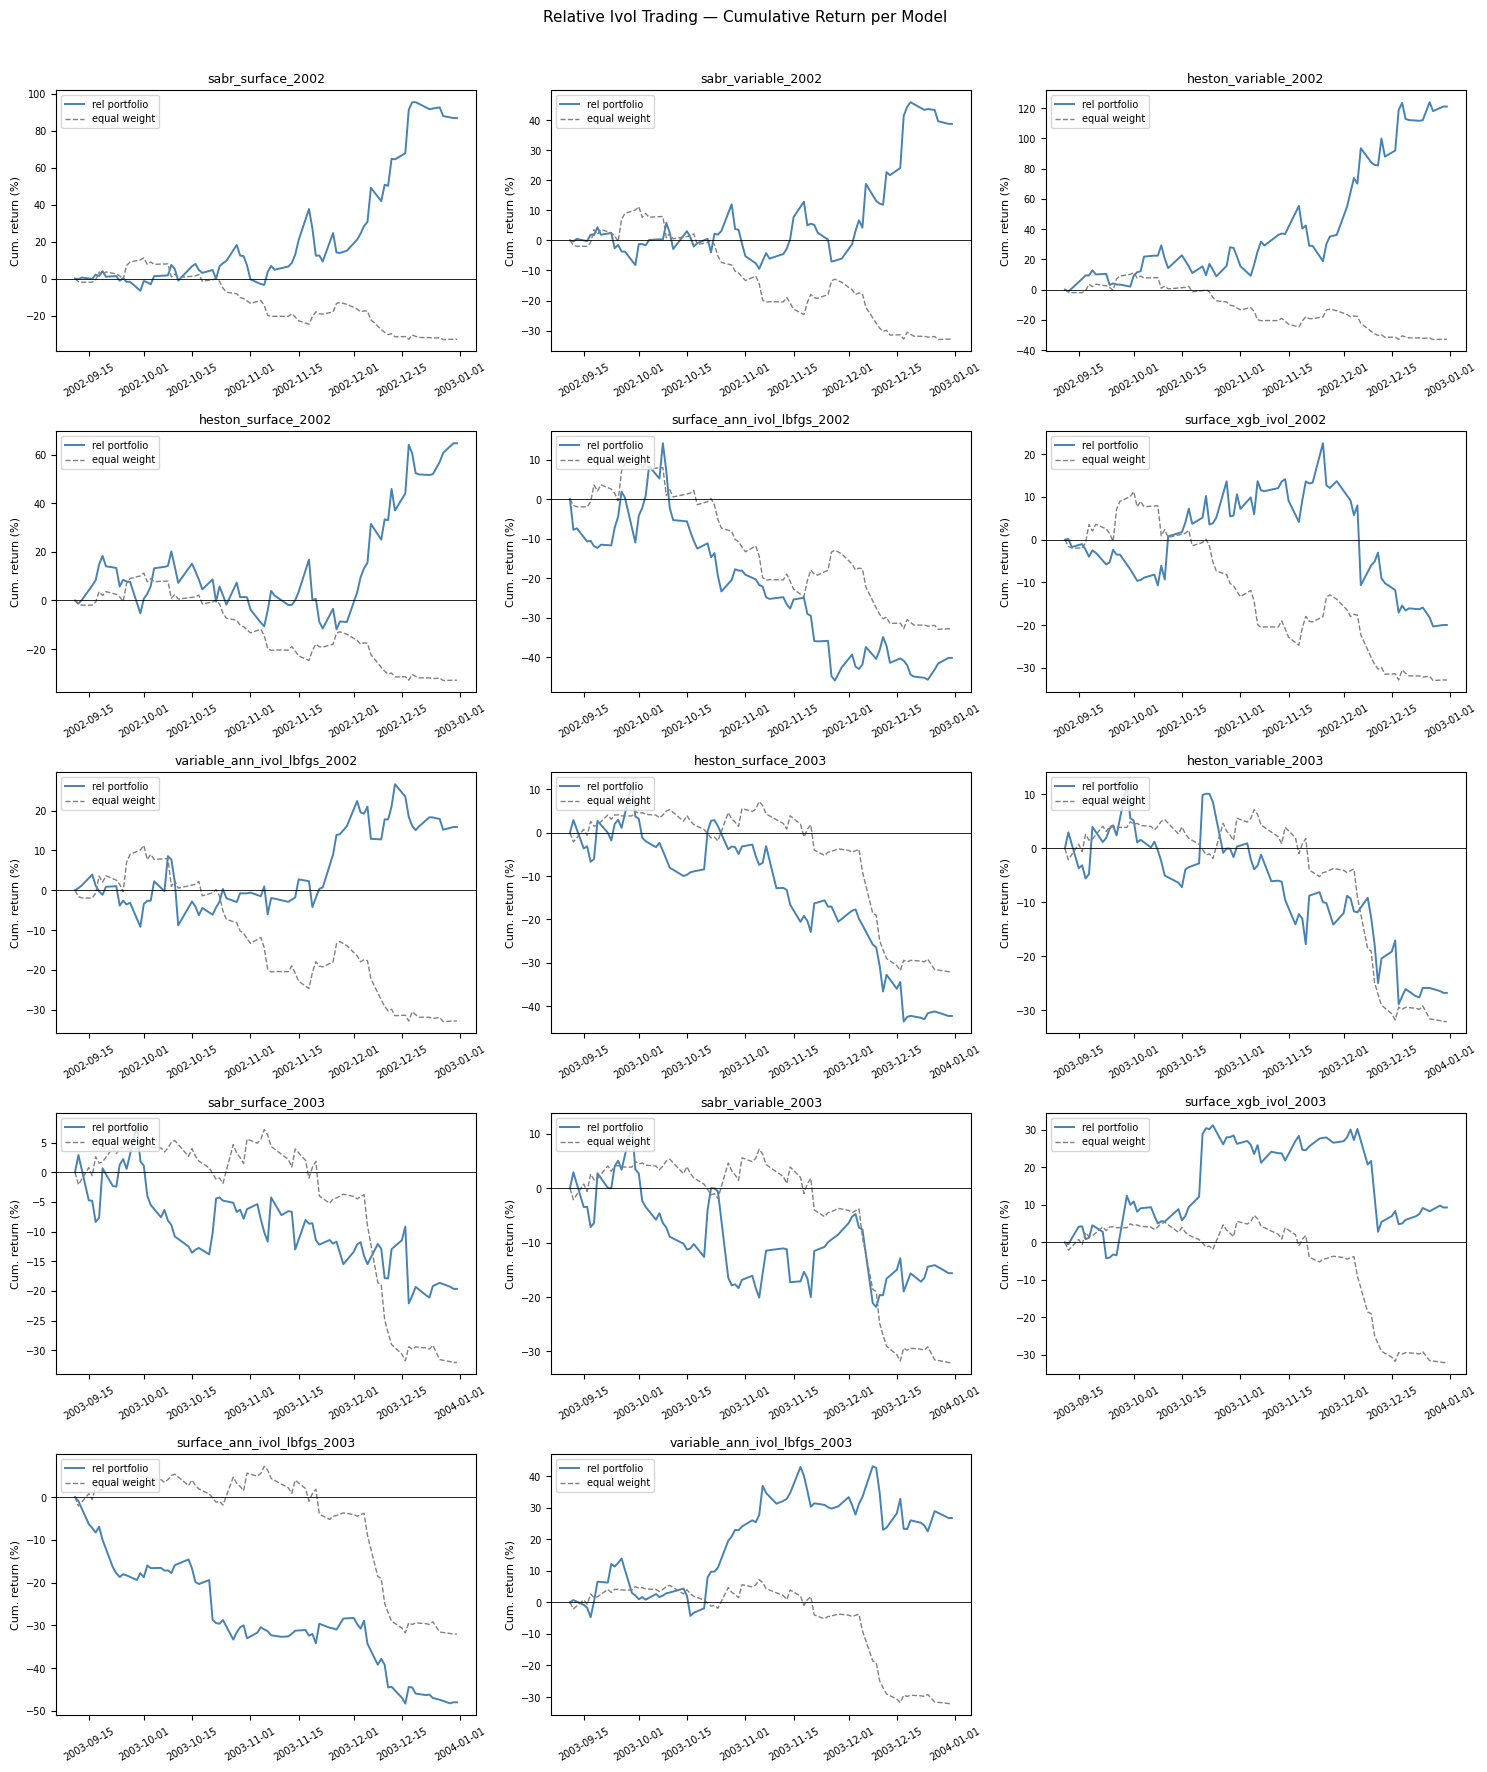

In [ ]:
# Plot cumulative returns

plot_trading_returns(price_partial_weights, strategy='abs')
plot_trading_returns(price_partial_weights, strategy='rel')

plot_trading_returns(ivol_partial_weights,  strategy='abs')
plot_trading_returns(ivol_partial_weights,  strategy='rel')


In [ ]:
# Stoch vol ML: GPU + parallel price models
stoch_vol_price_weights, stoch_vol_price_summary = run_price_trading_strategies_gpu(
    DATASET_STOCH_VOL_CONFIGS_PRICE,
    gamma           = 3,
    use_ewma        = True,
    ewma_lambda     = 0.94,
    os_trade_filter = 1,
    os_cov_filter   = 0,
    n_iter          = 20,
    lr              = 0.01,
    max_workers     = 4,
    verbose         = True,
)
stoch_vol_price_summary

Device: cuda  |  max_workers: 4
  [twostep_xgb_sabr_2002] Options: 168 x 75 days
  [twostep_lbfgs_sabr_2002] Options: 168 x 75 days
  [twostep_lbfgs_heston_2002] Options: 168 x 75 days
  [twostep_xgb_heston_2002] Options: 168 x 75 days
  [twostep_xgb_heston_2002] abs_price: 126.93% (Sharpe 1.44) | rel_price: -85.87% (Sharpe -2.77)
  [onestep_xgb_heston_2002] Options: 168 x 75 days
  [twostep_lbfgs_heston_2002] abs_price: -79.23% (Sharpe -1.83) | rel_price: 74.63% (Sharpe 0.84)
  [onestep_xgb_sabr_2002] Options: 168 x 75 days
  [twostep_lbfgs_sabr_2002] abs_price: -78.21% (Sharpe -1.72) | rel_price: 139.62% (Sharpe 1.47)
  [onestep_lbfgs_heston_2002] Options: 168 x 75 days
  [twostep_xgb_sabr_2002] abs_price: 98.84% (Sharpe 3.44) | rel_price: 77.85% (Sharpe 1.01)
  [onestep_lbfgs_sabr_2002] Options: 168 x 75 days
  [onestep_xgb_sabr_2002] abs_price: -71.25% (Sharpe -1.36) | rel_price: -18.04% (Sharpe -0.57)
  [twostep_xgb_heston_2003] Options: 141 x 75 days
  [onestep_xgb_heston_2002] a

,abs_p_total_%,abs_p_ann_%,abs_p_sharpe,abs_p_sortino,abs_p_mdd_%,abs_p_calmar,abs_p_win_%,rel_p_total_%,rel_p_ann_%,rel_p_sharpe,...,rel_p_calmar,rel_p_win_%,eq_abs_p_total_%,eq_abs_p_sharpe,eq_abs_p_mdd_%,eq_rel_p_total_%,eq_rel_p_sharpe,eq_rel_p_mdd_%,abs_p_destroyed,rel_p_destroyed
dataset,,,,,,,,,,,,,,,,,,,,,
twostep_xgb_heston_2002,126.93,1469.71,1.442,2.151,-73.13,20.098,54.7,-85.87,-99.98,-2.769,...,-1.153,48.2,-44.89,-5.671,-45.17,-30.30,-4.874,-38.72,False,False
twostep_xgb_sabr_2002,98.84,906.82,3.441,5.769,-23.16,39.149,56.0,77.85,1234.43,1.013,...,20.388,60.7,-44.89,-5.671,-45.17,-30.30,-4.874,-38.72,False,False
twostep_lbfgs_heston_2002,-79.23,-99.49,-1.826,-3.398,-80.50,-1.236,38.7,74.63,1129.07,0.842,...,19.877,62.5,-44.89,-5.671,-45.17,-30.30,-4.874,-38.72,False,False
twostep_lbfgs_sabr_2002,-78.21,-99.40,-1.723,-3.165,-79.80,-1.246,38.7,139.62,5003.01,1.474,...,90.669,60.7,-44.89,-5.671,-45.17,-30.30,-4.874,-38.72,False,False
onestep_xgb_heston_2002,-91.73,-99.98,-4.597,-6.803,-92.06,-1.086,37.3,17.65,107.79,0.247,...,1.845,58.9,-44.89,-5.671,-45.17,-30.30,-4.874,-38.72,False,False
onestep_xgb_sabr_2002,-71.25,-98.48,-1.360,-2.366,-83.97,-1.173,38.7,-18.04,-59.15,-0.566,...,-1.252,48.2,-44.89,-5.671,-45.17,-30.30,-4.874,-38.72,False,False
onestep_lbfgs_heston_2002,-65.20,-97.12,-1.878,-2.684,-80.38,-1.208,49.3,66.83,900.48,0.905,...,16.334,57.1,-44.89,-5.671,-45.17,-30.30,-4.874,-38.72,False,False
onestep_lbfgs_sabr_2002,-59.28,-95.12,-1.351,-2.408,-68.63,-1.386,44.0,30.20,227.85,0.429,...,3.949,53.6,-44.89,-5.671,-45.17,-30.30,-4.874,-38.72,False,False
twostep_xgb_heston_2003,28.18,130.31,0.435,0.941,-64.06,2.034,52.0,48.27,488.53,1.079,...,8.127,58.9,-49.28,-9.754,-50.04,-45.31,-10.732,-46.53,False,False


In [ ]:
# Stoch vol ML: GPU + parallel implied-vol models
stoch_vol_ivol_weights, stoch_vol_ivol_summary = run_ivol_trading_strategies_gpu(
    DATASET_STOCH_VOL_CONFIGS_IVOL,
    gamma             = 3,
    use_ewma          = True,
    ewma_lambda       = 0.94,
    os_trade_filter   = 1,
    os_cov_filter     = 0,
    n_iter            = 20,
    lr                = 0.01,
    l1_penalty_weight = 500,
    max_workers       = 4,
    verbose           = True,
)
stoch_vol_ivol_summary

Device: cuda  |  max_workers: 4
  [twostep_lbfgs_sabr_2002] Straddles: 68 x 75 days
  [twostep_xgb_sabr_2002] Straddles: 68 x 75 days
  [twostep_lbfgs_heston_2002] Straddles: 68 x 75 days
  [twostep_xgb_heston_2002] Straddles: 68 x 75 days
  [twostep_lbfgs_heston_2002] abs_ivol: -0.21% (Sharpe -0.01) | rel_ivol: 32.62% (Sharpe 1.59)
  [onestep_xgb_heston_2002] Straddles: 68 x 75 days
  [twostep_xgb_heston_2002] abs_ivol: 38.53% (Sharpe 2.47) | rel_ivol: 66.60% (Sharpe 4.73)
  [onestep_xgb_sabr_2002] Straddles: 68 x 75 days
  [twostep_lbfgs_sabr_2002] abs_ivol: -15.72% (Sharpe -0.89) | rel_ivol: 10.68% (Sharpe 0.64)
  [onestep_lbfgs_heston_2002] Straddles: 68 x 75 days
  [twostep_xgb_sabr_2002] abs_ivol: 46.51% (Sharpe 2.35) | rel_ivol: 7.25% (Sharpe 0.45)
  [onestep_lbfgs_sabr_2002] Straddles: 68 x 75 days
  [onestep_xgb_heston_2002] abs_ivol: -0.02% (Sharpe -0.00) | rel_ivol: 32.68% (Sharpe 1.59)
  [twostep_xgb_heston_2003] Straddles: 57 x 75 days
  [onestep_lbfgs_heston_2002] abs_ivo

,abs_iv_total_%,abs_iv_ann_%,abs_iv_sharpe,abs_iv_sortino,abs_iv_mdd_%,abs_iv_calmar,abs_iv_win_%,rel_iv_total_%,rel_iv_ann_%,rel_iv_sharpe,...,rel_iv_calmar,rel_iv_win_%,eq_abs_iv_total_%,eq_abs_iv_sharpe,eq_abs_iv_mdd_%,eq_rel_iv_total_%,eq_rel_iv_sharpe,eq_rel_iv_mdd_%,abs_iv_destroyed,rel_iv_destroyed
dataset,,,,,,,,,,,,,,,,,,,,,
twostep_xgb_heston_2002,38.53,198.95,2.473,3.157,-19.54,10.183,58.7,66.60,894.25,4.731,...,123.627,51.8,-22.42,-3.820,-24.07,-24.07,-5.391,-21.91,False,False
twostep_xgb_sabr_2002,46.51,260.87,2.348,3.087,-24.29,10.738,57.3,7.25,37.01,0.450,...,1.639,62.5,-22.42,-3.820,-24.07,-24.07,-5.391,-21.91,False,False
twostep_lbfgs_heston_2002,-0.21,-0.71,-0.008,-0.011,-48.20,-0.015,53.3,32.62,256.19,1.588,...,9.752,48.2,-22.42,-3.820,-24.07,-24.07,-5.391,-21.91,False,False
twostep_lbfgs_sabr_2002,-15.72,-43.70,-0.887,-1.203,-42.35,-1.032,48.0,10.68,57.88,0.638,...,2.529,66.1,-22.42,-3.820,-24.07,-24.07,-5.391,-21.91,False,False
onestep_xgb_heston_2002,-0.02,-0.08,-0.001,-0.001,-43.88,-0.002,52.0,32.68,256.98,1.595,...,9.789,48.2,-22.42,-3.820,-24.07,-24.07,-5.391,-21.91,False,False
onestep_xgb_sabr_2002,-23.96,-60.15,-1.388,-2.629,-33.76,-1.782,37.3,-23.22,-69.55,-1.565,...,-1.778,48.2,-22.42,-3.820,-24.07,-24.07,-5.391,-21.91,False,False
onestep_lbfgs_heston_2002,5.85,21.04,0.224,0.325,-45.71,0.460,54.7,32.29,252.28,1.575,...,9.540,48.2,-22.42,-3.820,-24.07,-24.07,-5.391,-21.91,False,False
onestep_lbfgs_sabr_2002,-35.25,-76.79,-3.344,-5.630,-39.02,-1.968,40.0,40.19,357.38,2.136,...,13.219,62.5,-22.42,-3.820,-24.07,-24.07,-5.391,-21.91,False,False
twostep_xgb_heston_2003,-18.49,-49.69,-2.771,-5.146,-31.89,-1.558,36.0,-21.91,-67.14,-3.642,...,-2.194,37.5,-17.01,-4.177,-23.63,-13.39,-4.197,-18.93,False,False


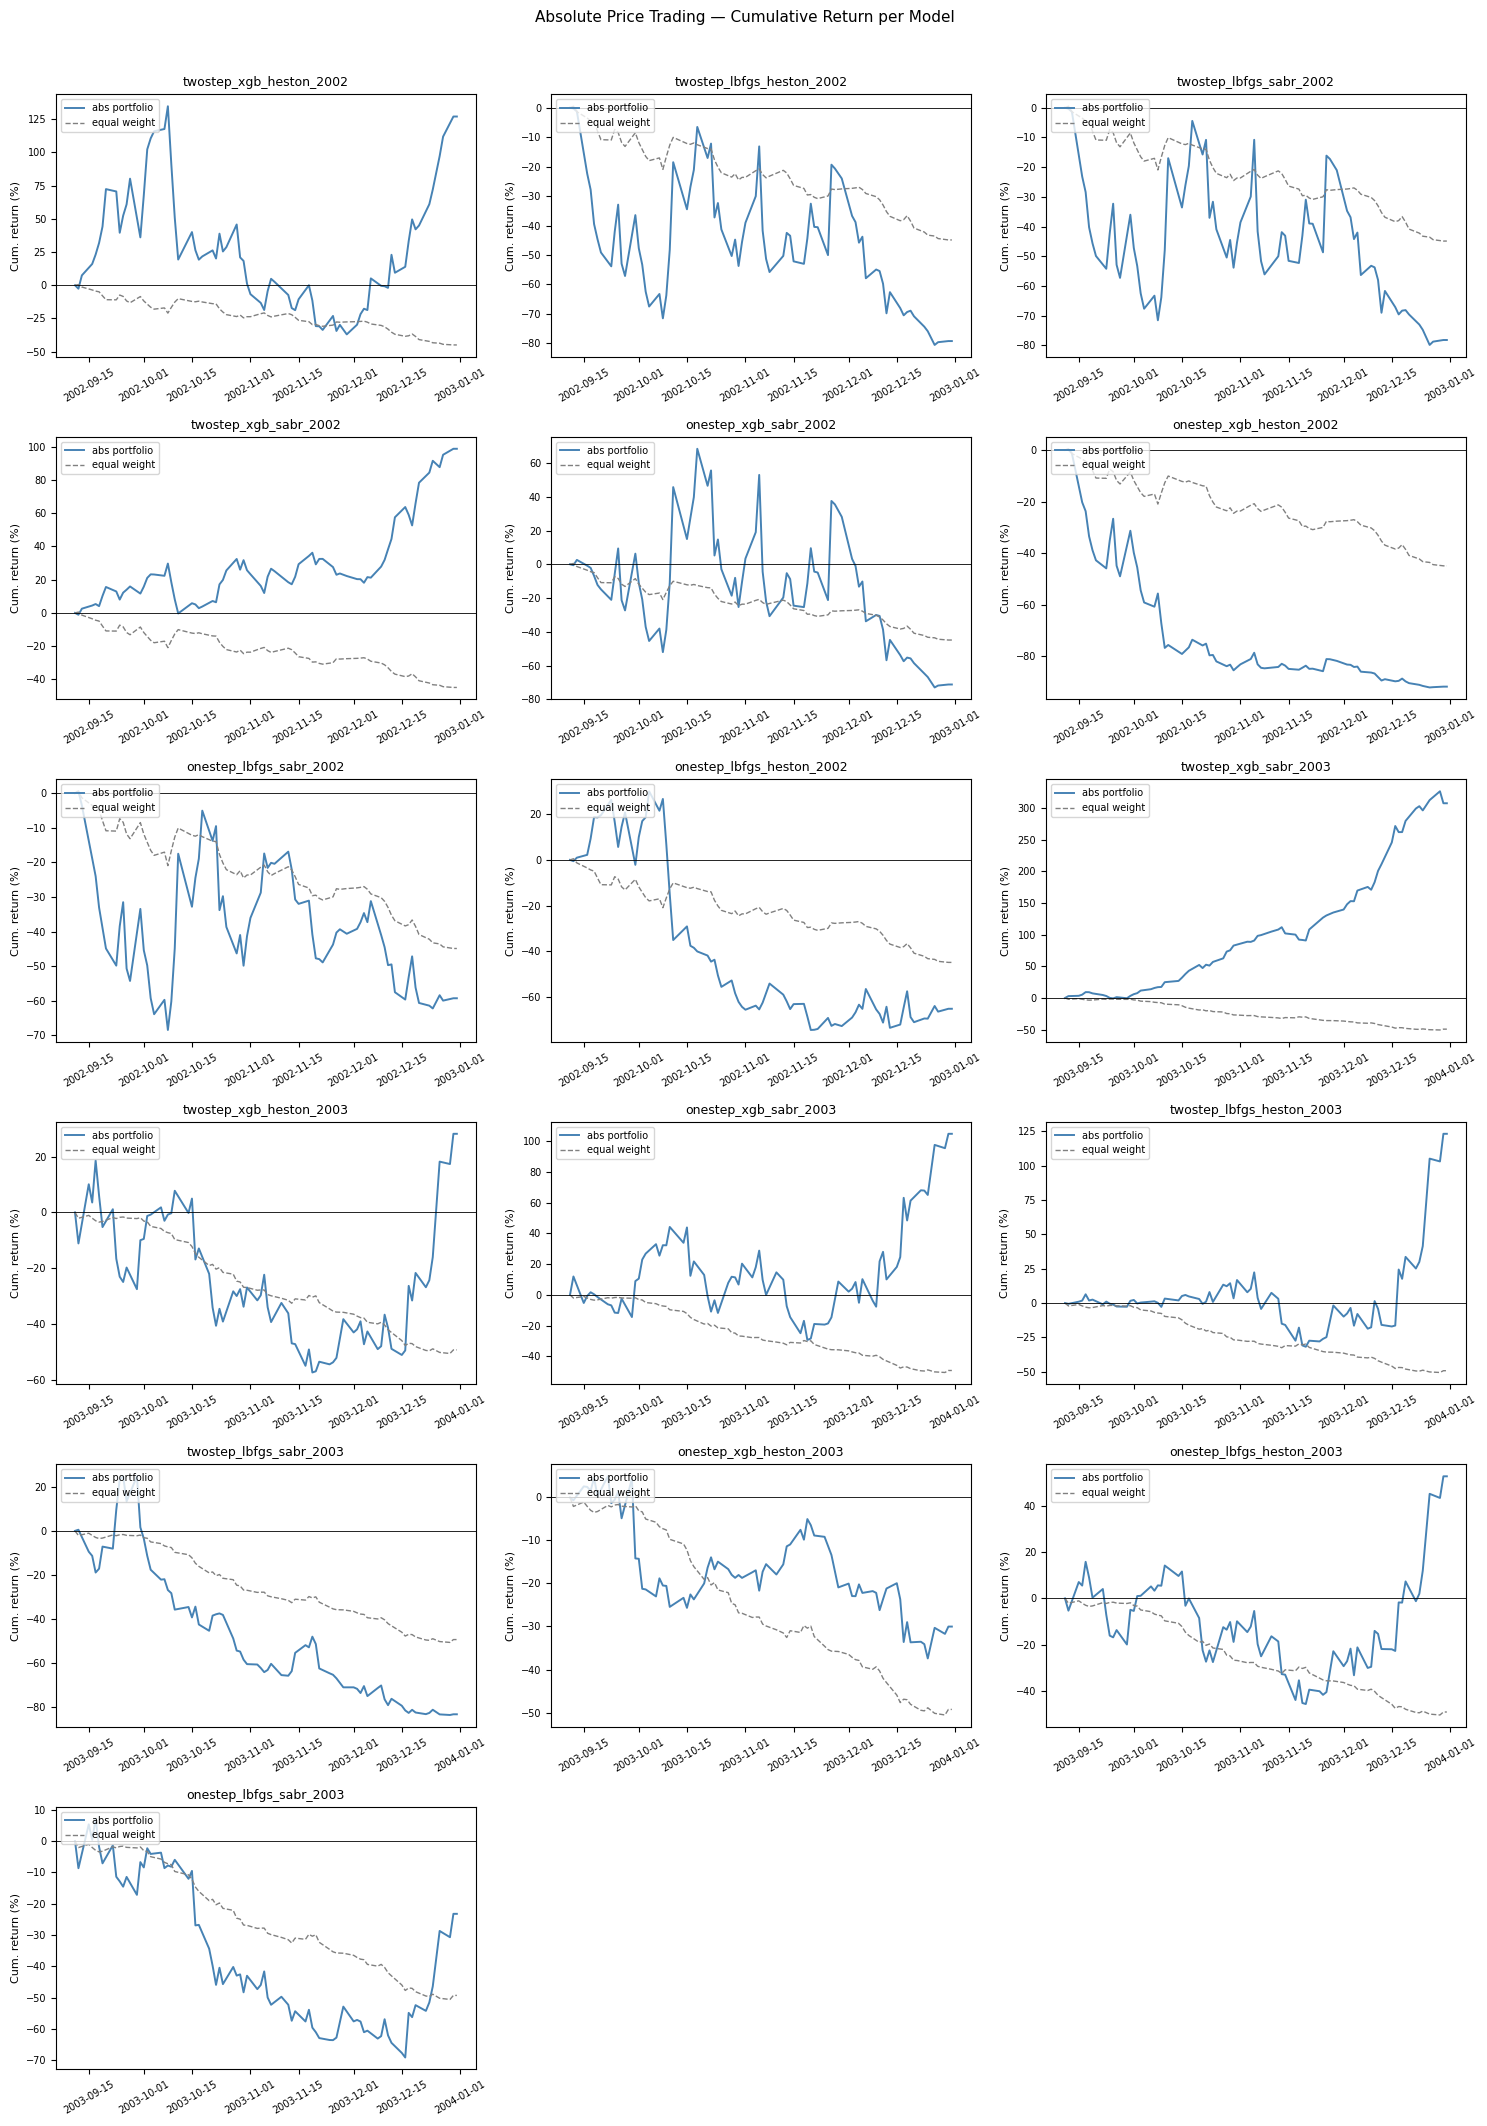

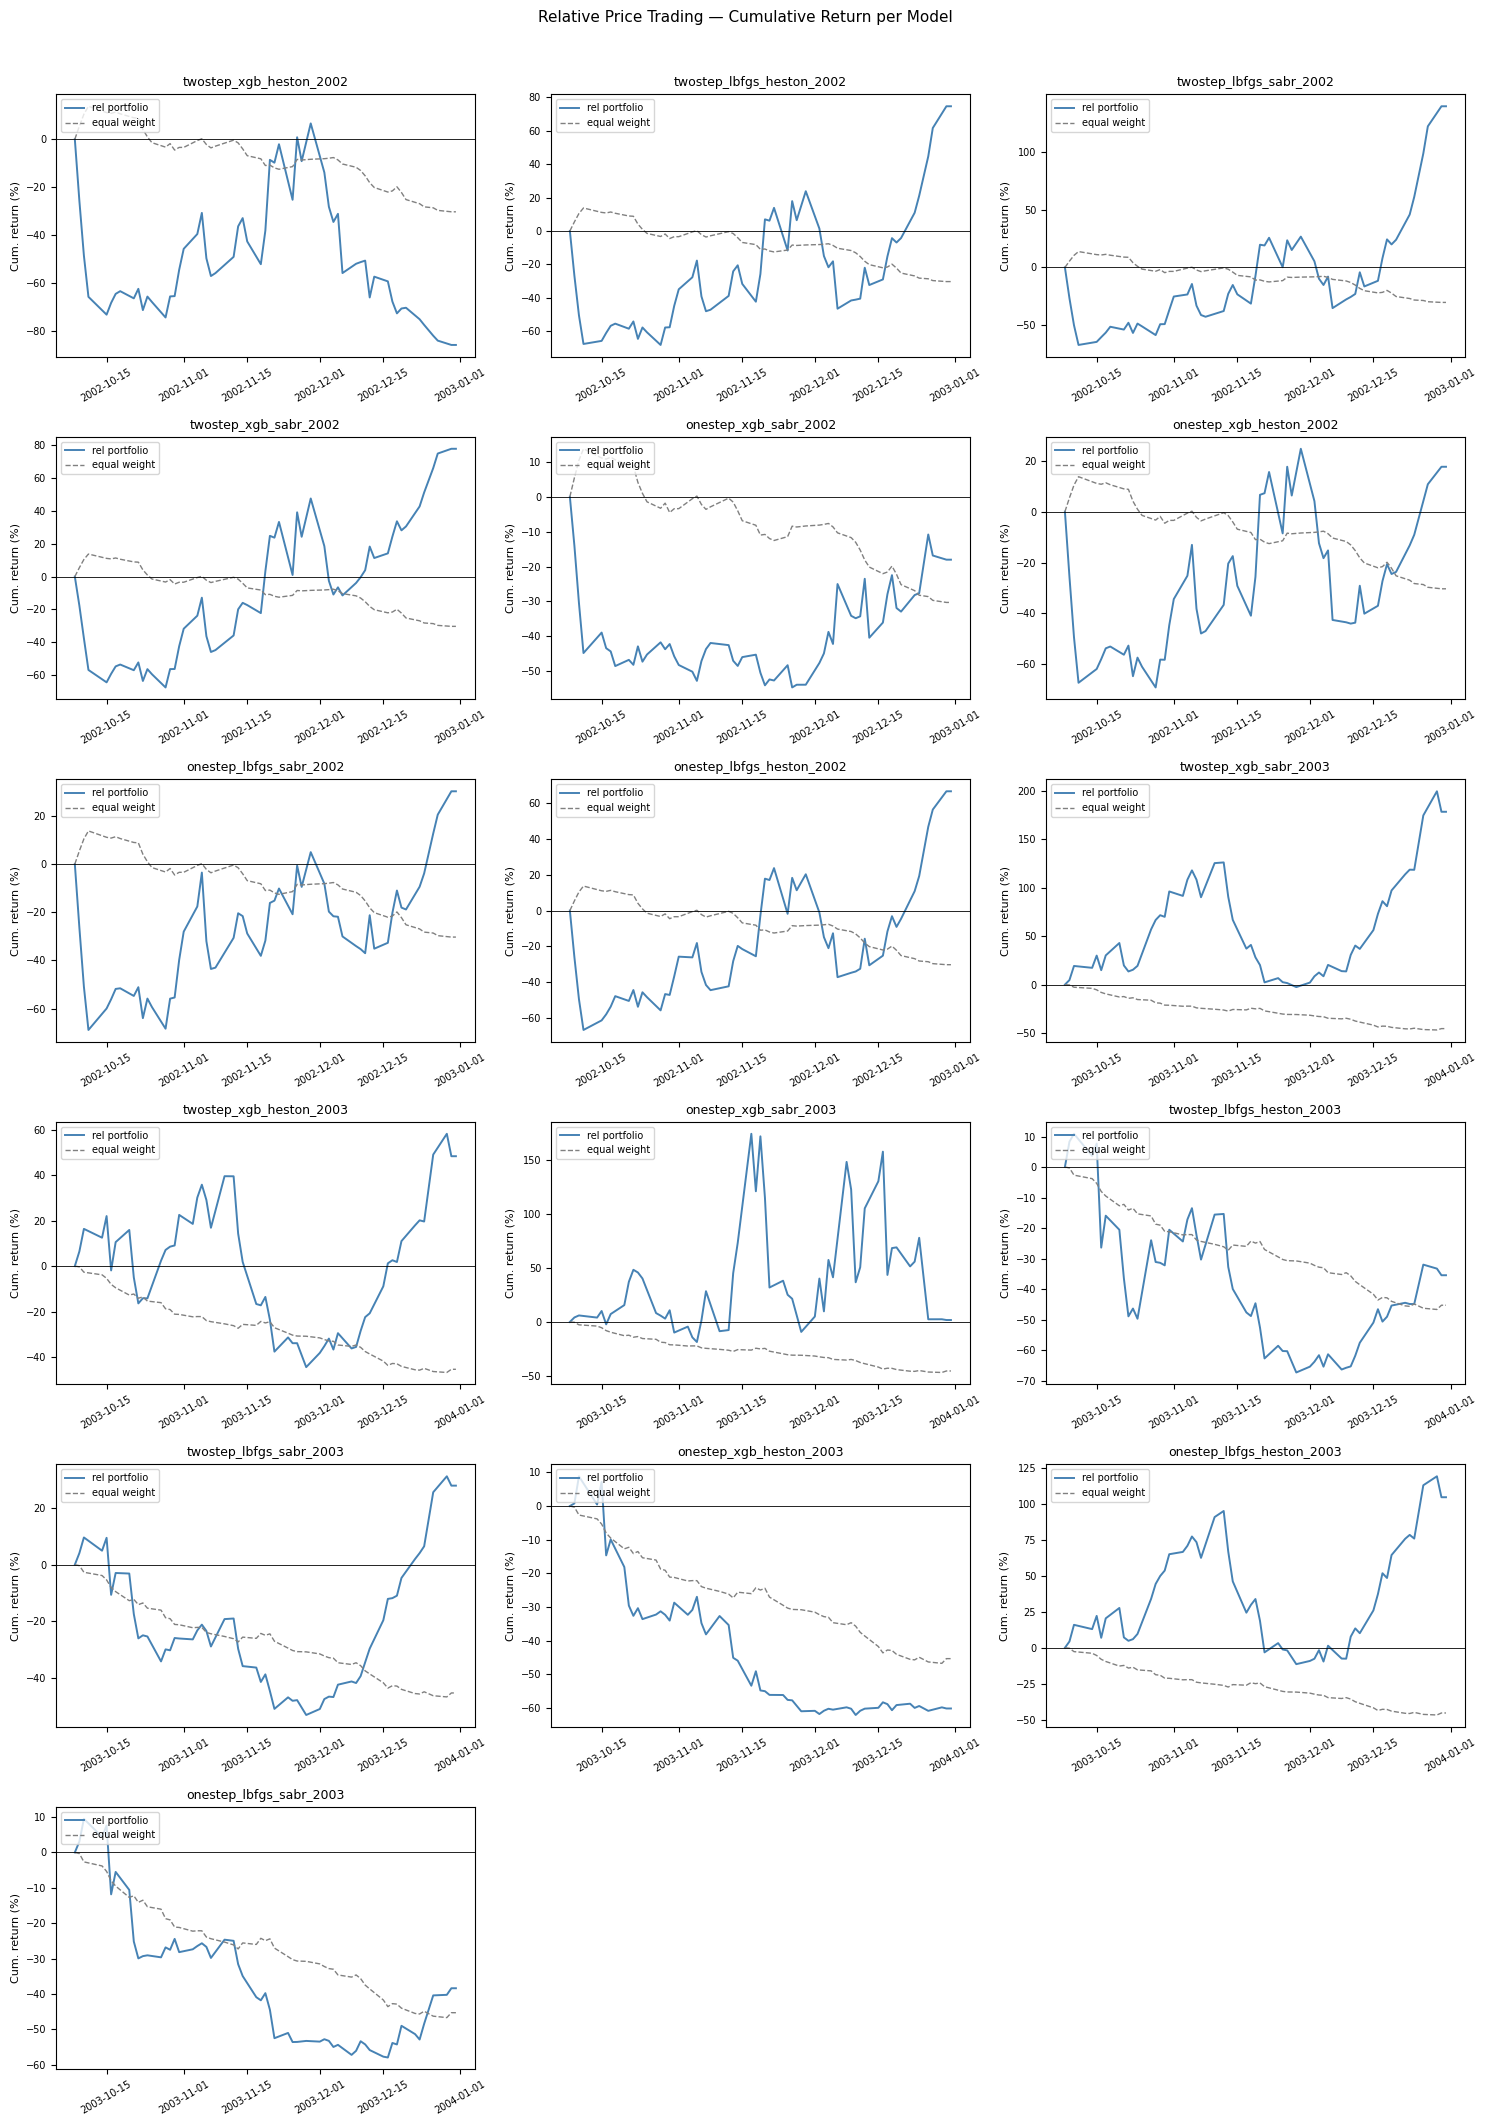

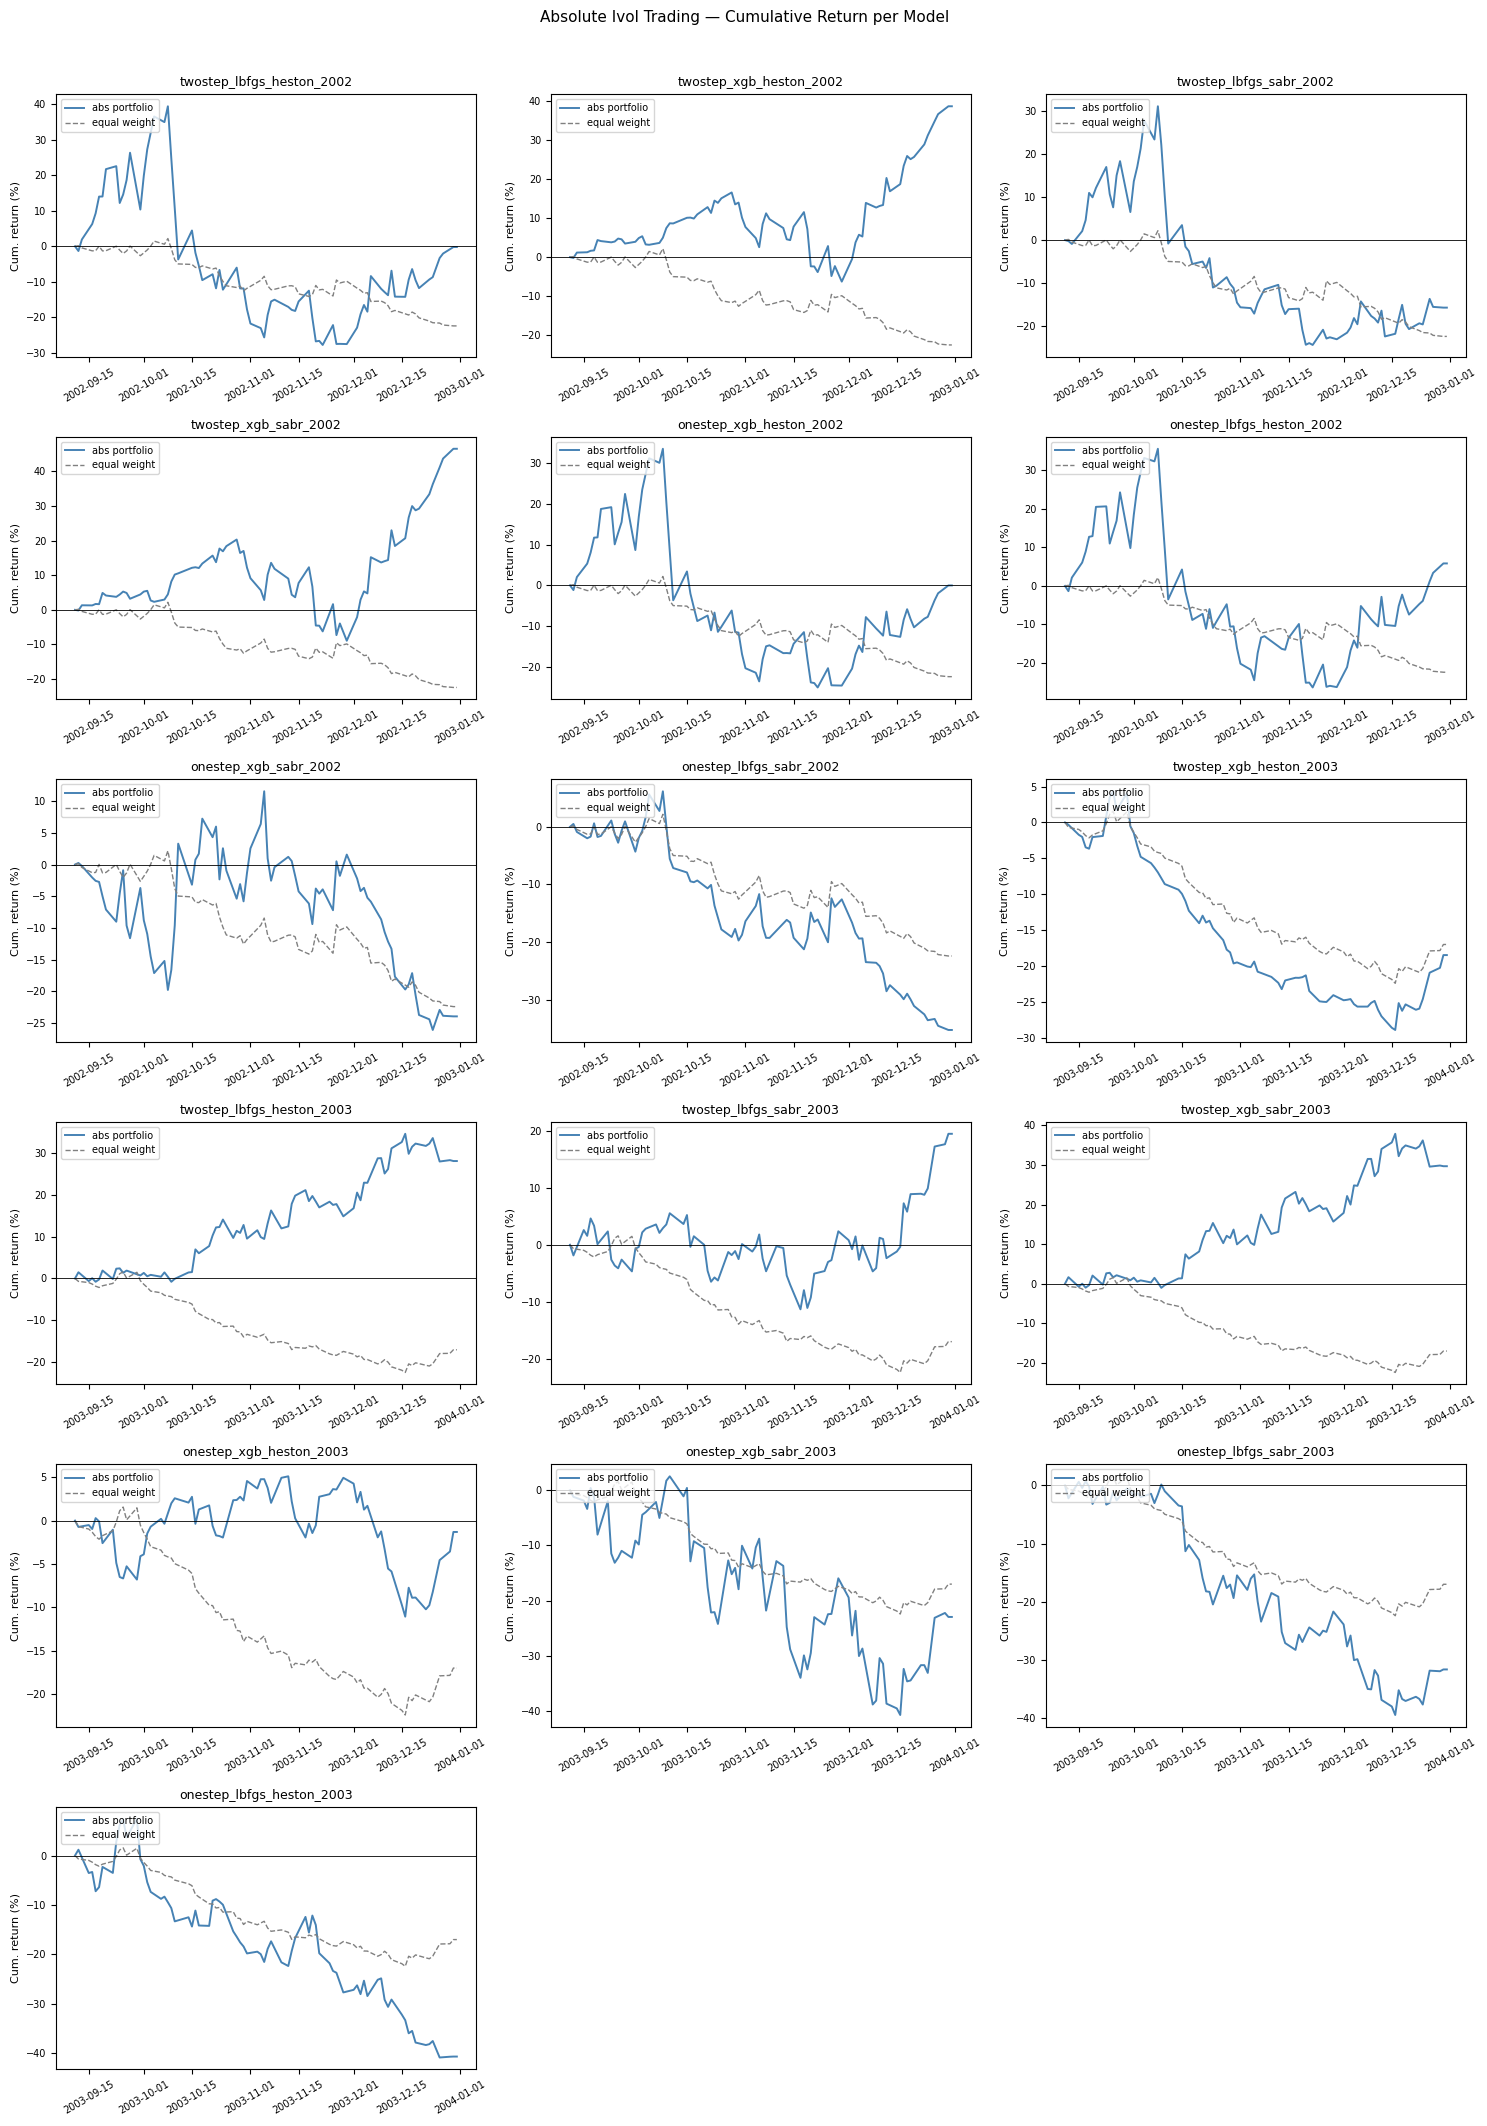

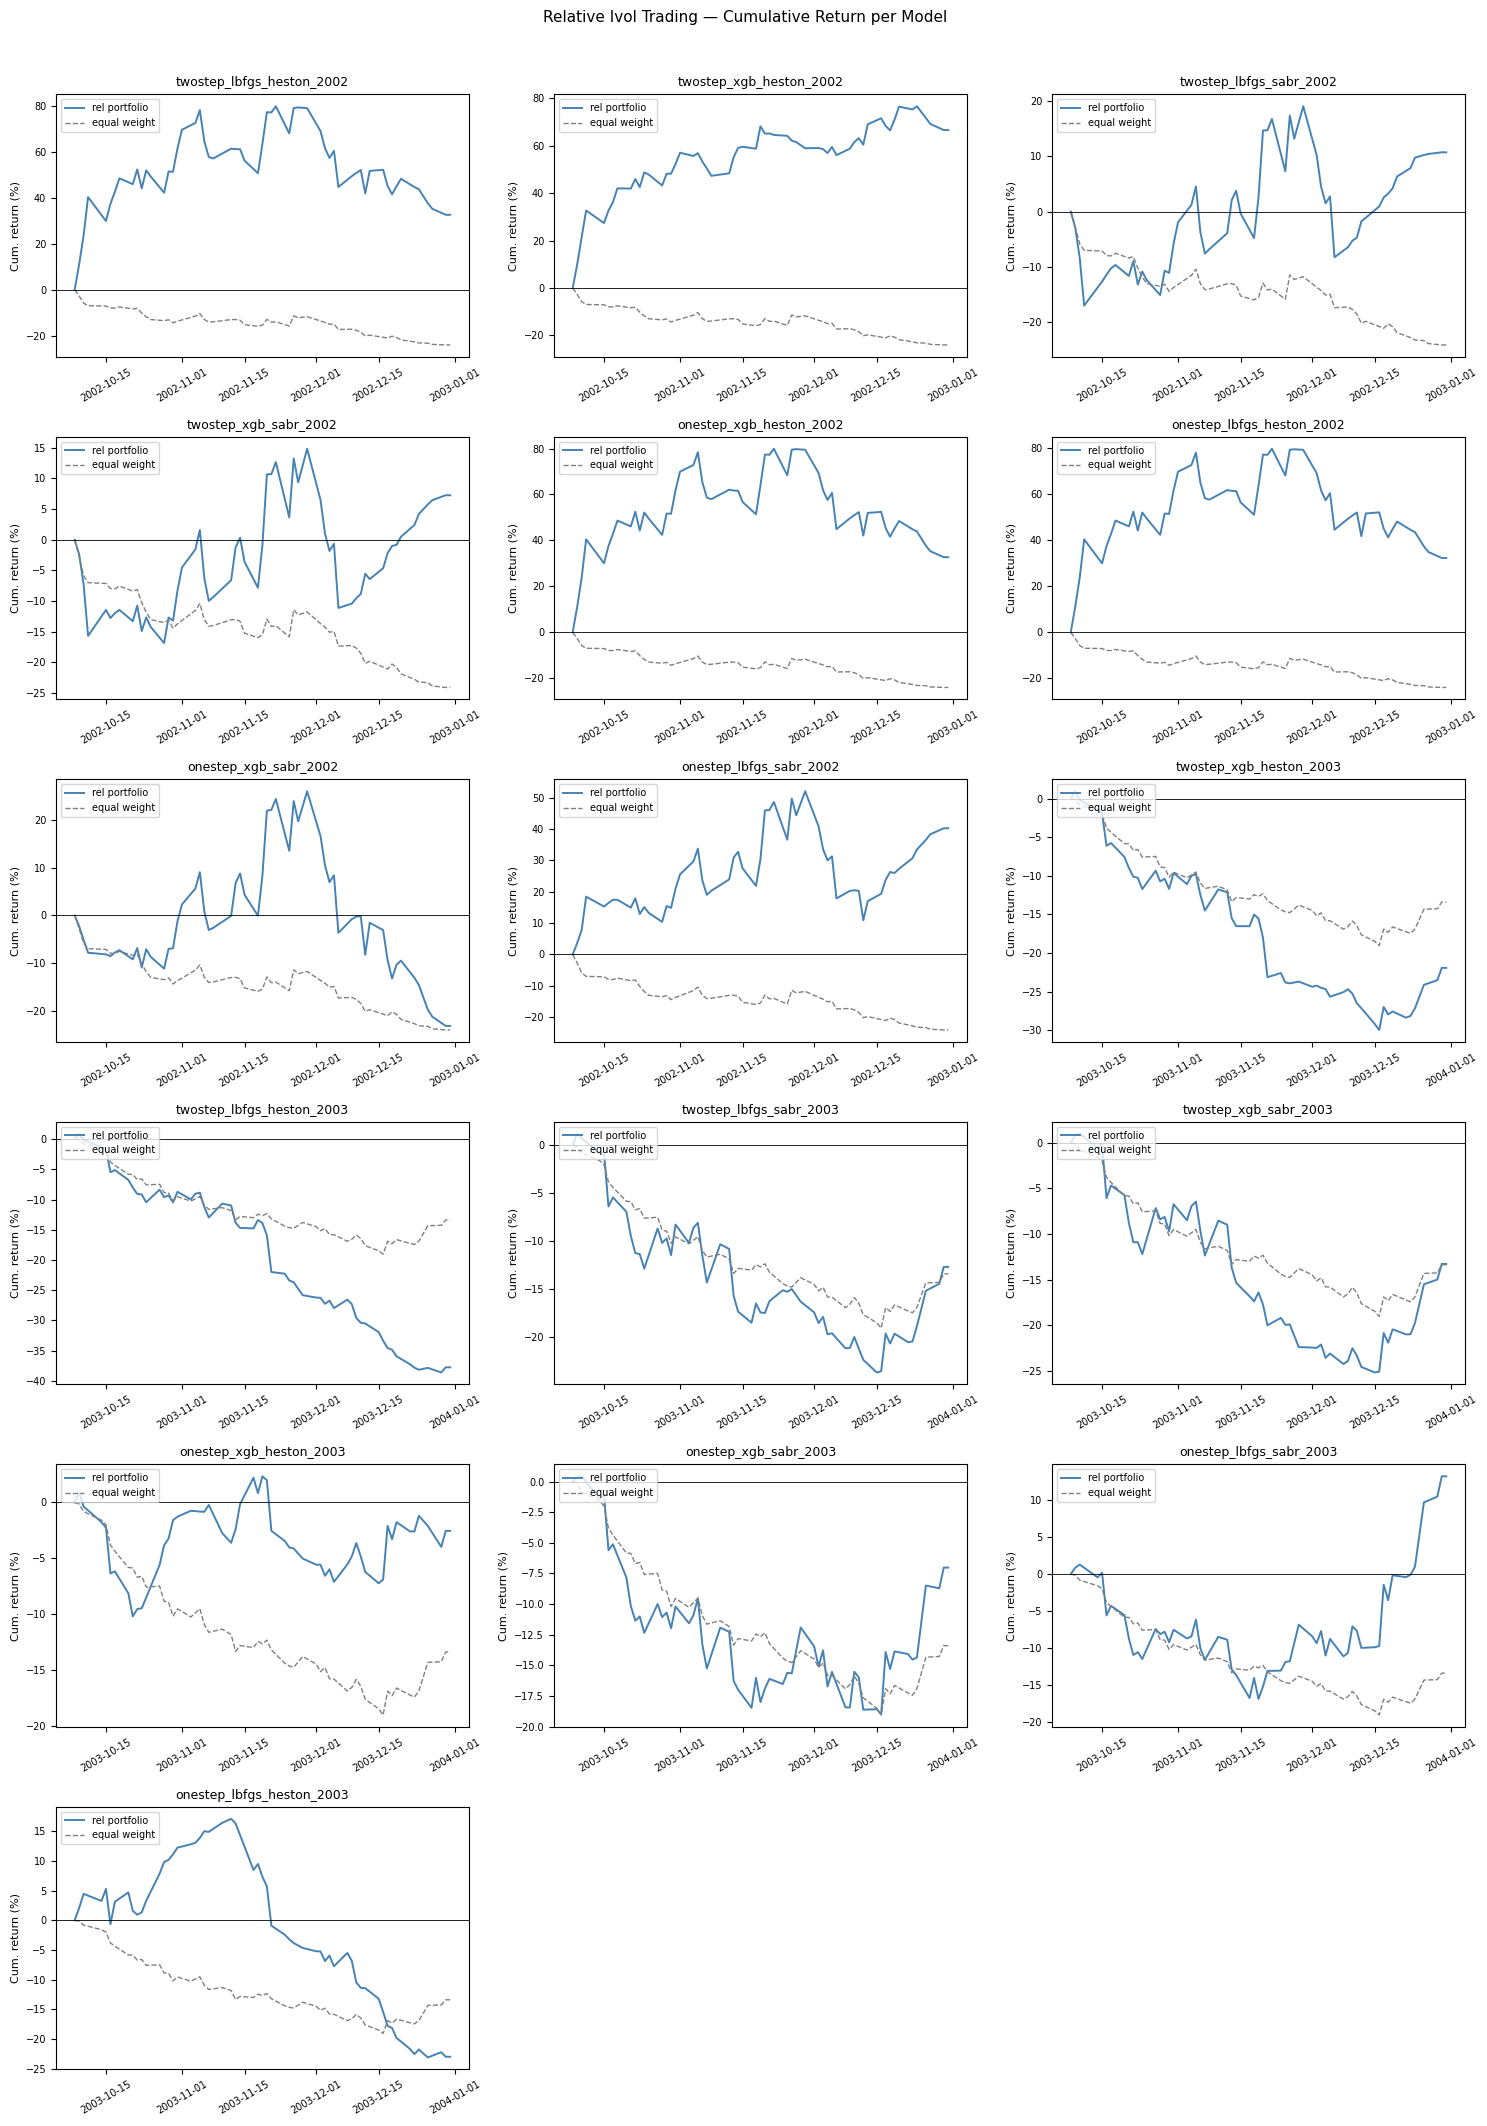

In [ ]:
# Plot cumulative returns

plot_trading_returns(stoch_vol_price_weights, strategy='abs')
plot_trading_returns(stoch_vol_price_weights, strategy='rel')

plot_trading_returns(stoch_vol_ivol_weights,  strategy='abs')
plot_trading_returns(stoch_vol_ivol_weights,  strategy='rel')

In [ ]:
# Export code
output_dir = r"C:\Users\chril\Downloads\Master_Thesis_Materials\Data\Working\Option_Metrics\models_final_output\Trading_results"

def export_weights(weights_dict, output_dir, prefix):
    for model_name, strategies in weights_dict.items():
        for strategy_key, df in strategies.items():
            if isinstance(df, pd.DataFrame):
                filename = f"{prefix}_{strategy_key}_{model_name}.dta"
                output_path = os.path.join(output_dir, filename)
                try:
                    df.to_stata(output_path)
                    print(f"Exported: {filename}")
                except Exception as e:
                    print(f"Failed {filename}: {e}")
                    csv_path = output_path.replace('.dta', '.csv')
                    df.to_csv(csv_path, index=True)
                    print(f"Exported CSV instead: {csv_path}")

export_weights(price_weights_gpu, output_dir, "price")
export_weights(ivol_weights_gpu, output_dir, "ivol")

price_summary_gpu.to_stata(os.path.join(output_dir, "price_summary.dta"))
ivol_summary_gpu.to_stata(os.path.join(output_dir, "ivol_summary.dta"))
print("Exported full-config summary tables")

export_weights(price_partial_weights, output_dir, "price_partial")
export_weights(ivol_partial_weights, output_dir, "ivol_partial")

price_partial_summary.to_stata(os.path.join(output_dir, "price_partial_summary.dta"))
ivol_partial_summary.to_stata(os.path.join(output_dir, "ivol_partial_summary.dta"))
print("Exported partial-config summary tables")

export_weights(stoch_vol_price_weights, output_dir, "stoch_vol_price")
export_weights(stoch_vol_ivol_weights, output_dir, "stoch_vol_ivol")

stoch_vol_price_summary.to_stata(os.path.join(output_dir, "stoch_vol_price_summary.dta"))
stoch_vol_ivol_summary.to_stata(os.path.join(output_dir, "stoch_vol_ivol_summary.dta"))
print("Exported stoch vol ML summary tables")

export_trading_plots(price_weights_gpu,       output_dir, "plot_price_full")
export_trading_plots(ivol_weights_gpu,        output_dir, "plot_ivol_full")
export_trading_plots(price_partial_weights,   output_dir, "plot_price_partial")
export_trading_plots(ivol_partial_weights,    output_dir, "plot_ivol_partial")
export_trading_plots(stoch_vol_price_weights, output_dir, "plot_stoch_vol_price")
export_trading_plots(stoch_vol_ivol_weights,  output_dir, "plot_stoch_vol_ivol")
print("Exported all trading return plots")